In [ ]:
#1
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
else:
    print("WARNING: GPU is not available.")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA: 13.0


In [ ]:
#2
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 9.4 MB/s eta 0:00:00


In [ ]:
#3
import ultralytics

print("Ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics: 8.4.173


In [ ]:
#4
from pathlib import Path

print("Contents under /content/stage2_input:\n")

for path in sorted(BASE_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(BASE_DIR))

Contents under /content/stage2_input:

frames\frame_000000.jpg
frames\frame_000004.jpg
frames\frame_000008.jpg
frames\frame_000012.jpg
frames\frame_000016.jpg
frames\frame_000020.jpg
frames\frame_000024.jpg
frames\frame_000028.jpg
frames\frame_000032.jpg
frames\frame_000036.jpg
frames\frame_000040.jpg
frames\frame_000044.jpg
frames\frame_000048.jpg
frames\frame_000052.jpg
frames\frame_000056.jpg
frames\frame_000060.jpg
frames\frame_000064.jpg
frames\frame_000068.jpg
frames\frame_000072.jpg
frames\frame_000076.jpg
frames\frame_000080.jpg
frames\frame_000084.jpg
frames\frame_000088.jpg
frames\frame_000092.jpg
frames\frame_000096.jpg
frames\frame_000100.jpg
frames\frame_000104.jpg
frames\frame_000108.jpg
frames\frame_000112.jpg
frames\frame_000116.jpg
frames\frame_000120.jpg
frames\frame_000124.jpg
frames\frame_000128.jpg
frames\frame_000132.jpg
frames\frame_000136.jpg
frames\frame_000140.jpg
frames\frame_000144.jpg
frames\frame_000148.jpg
frames\frame_000152.jpg
frames\frame_000156.jpg
f

In [ ]:
#5
frames = sorted(FRAMES_DIR.glob("frame_*.jpg"))

print("Number of frames:", len(frames))

if frames:
    print("First frame:", frames[0])
    print("Last frame :", frames[-1])

Number of frames: 301
First frame: /content/stage2_input/frames/frame_000000.jpg
Last frame : /content/stage2_input/frames/frame_001200.jpg


In [ ]:
#6
# Find the Stage 1 CSV automatically
csv_files = sorted(BASE_DIR.rglob("*.csv"))

print("CSV files found:", len(csv_files))

for csv_file in csv_files:
    print(csv_file)

CSV files found: 0


In [ ]:
#7
import re

image_numbers = [
    int(re.search(r"frame_(\d+)\.jpg", p.name).group(1))
    for p in frames
]

csv_numbers = frame_index["frame_number"].astype(int).tolist()

print("Image count:", len(image_numbers))
print("CSV count  :", len(csv_numbers))

print("Image range:", min(image_numbers), "to", max(image_numbers))
print("CSV range  :", min(csv_numbers), "to", max(csv_numbers))

print("Same frame numbers:", image_numbers == csv_numbers)

Image count: 301
CSV count  : 301
Image range: 0 to 1200
CSV range  : 0 to 1200
Same frame numbers: True


In [ ]:
#8
print("Timestamp range:")
print(
    frame_index["timestamp_seconds"].min(),
    "to",
    frame_index["timestamp_seconds"].max(),
    "seconds"
)

print("\nSample index:")
display(
    frame_index[
        ["frame_number", "timestamp_seconds", "image_path"]
    ].head(10)
)

Timestamp range:
0.0 to 60.0 seconds

Sample index:


,frame_number,timestamp_seconds,image_path
0,0,0.0,data\processed\DLR_HT_060000_060100\frames\fra...
1,4,0.2,data\processed\DLR_HT_060000_060100\frames\fra...
2,8,0.4,data\processed\DLR_HT_060000_060100\frames\fra...
3,12,0.6,data\processed\DLR_HT_060000_060100\frames\fra...
4,16,0.8,data\processed\DLR_HT_060000_060100\frames\fra...
5,20,1.0,data\processed\DLR_HT_060000_060100\frames\fra...
6,24,1.2,data\processed\DLR_HT_060000_060100\frames\fra...
7,28,1.4,data\processed\DLR_HT_060000_060100\frames\fra...
8,32,1.6,data\processed\DLR_HT_060000_060100\frames\fra...
9,36,1.8,data\processed\DLR_HT_060000_060100\frames\fra...


FIXED SESSION 1 — XML -> YOLO

Checking downloaded data...
PASS: Downloaded dataset found.
Raw data: /content/detrac_stage2/raw

Removing previous incorrect YOLO output...
Fresh YOLO output directories created.

1. TESTING XML PARSER
Test sequence: MVI_20012
Frames parsed: 936
Vehicle boxes: 8,608

First annotated frame:
  Frame 1: 11 boxes
    ('car', 500.55, 246.63, 108.45, 113.68)
    ('car', 451.21, 47.25, 23.85, 23.845)
    ('van', 539.5, 55.04, 29.0, 29.035)
    ('car', 540.0, 38.943, 23.35, 25.402)
    ('car', 589.85, 51.925, 36.8, 29.035)
  Frame 2: 11 boxes
    ('car', 500.65, 251.13, 110.55, 117.57)
    ('car', 451.56, 46.731, 23.84, 24.364)
    ('van', 539.3, 55.47, 29.75, 28.78)
    ('car', 539.4, 38.682, 24.1, 25.753)
    ('car', 590.7, 52.185, 36.85, 29.815)
  Frame 3: 11 boxes
    ('car', 500.7, 255.63, 112.65, 121.47)
    ('car', 451.9, 46.212, 23.85, 24.883)
    ('van', 539.15, 55.905, 30.4, 28.52)
    ('car', 538.8, 38.423, 24.85, 26.097)
    ('car', 591.6, 52.44, 36.

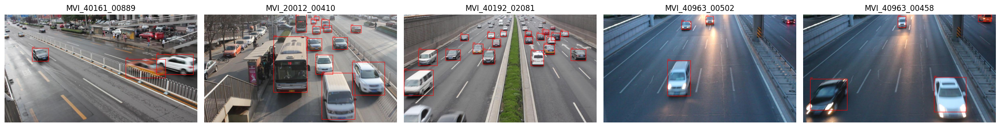


SESSION 1 FINAL STATUS

PASS — Dataset preparation is complete.

The XML annotations were successfully converted to YOLO format.
Training and validation contain real bounding boxes.
The visual samples above should show vehicle bounding boxes.

Ready for Session 2: YOLO11n traffic-domain training.



In [ ]:
#9
# ============================================================
# SESSION 1 — FIXED XML -> YOLO CONVERSION   (34) historical
# ============================================================
# Reuses the already-downloaded UA-DETRAC files.
# DOES NOT download anything.
# ============================================================

import os
import shutil
import random
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw


# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE_DIR = Path("/content/detrac_stage2")

RAW_DIR = BASE_DIR / "raw"
DATASET_DIR = BASE_DIR / "yolo_dataset"

IMAGE_ROOT = (
    RAW_DIR
    / "DETRAC"
    / "DETRAC-Images"
    / "DETRAC-Images"
)

XML_ROOT = (
    RAW_DIR
    / "DETRAC"
    / "DETRAC-Train-Annotations-XML"
    / "DETRAC-Train-Annotations-XML"
)

SEQUENCES = [
    "MVI_20012",
    "MVI_40161",
    "MVI_40192",
    "MVI_40752",
    "MVI_40962",
    "MVI_40963",
]

VAL_SEQUENCE = "MVI_40963"

TRAIN_SEQUENCES = [
    s for s in SEQUENCES
    if s != VAL_SEQUENCE
]

CLASS_NAMES = [
    "car",
    "bus",
    "van",
    "others",
]

CLASS_TO_ID = {
    "car": 0,
    "bus": 1,
    "van": 2,
    "others": 3,
}

IMG_W = 960
IMG_H = 540

TRAIN_IMG_DIR = DATASET_DIR / "images" / "train"
VAL_IMG_DIR = DATASET_DIR / "images" / "val"

TRAIN_LABEL_DIR = DATASET_DIR / "labels" / "train"
VAL_LABEL_DIR = DATASET_DIR / "labels" / "val"


# ============================================================
# 2. CONFIRM RAW DATA EXISTS
# ============================================================

print("=" * 80)
print("FIXED SESSION 1 — XML -> YOLO")
print("=" * 80)

print("\nChecking downloaded data...")

if not IMAGE_ROOT.exists():
    raise FileNotFoundError(
        f"Image directory not found:\n{IMAGE_ROOT}"
    )

if not XML_ROOT.exists():
    raise FileNotFoundError(
        f"XML directory not found:\n{XML_ROOT}"
    )

print("PASS: Downloaded dataset found.")
print(f"Raw data: {RAW_DIR}")


# ============================================================
# 3. REMOVE ONLY THE BROKEN YOLO OUTPUT
# ============================================================

if DATASET_DIR.exists():
    print("\nRemoving previous incorrect YOLO output...")
    shutil.rmtree(DATASET_DIR)

TRAIN_IMG_DIR.mkdir(parents=True, exist_ok=True)
VAL_IMG_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_LABEL_DIR.mkdir(parents=True, exist_ok=True)
VAL_LABEL_DIR.mkdir(parents=True, exist_ok=True)

print("Fresh YOLO output directories created.")


# ============================================================
# 4. CORRECT UA-DETRAC XML PARSER
# ============================================================

def parse_detrac_xml(xml_path):
    """
    Parse the actual UA-DETRAC structure:

        sequence
        └── frame
            └── target_list
                └── target
                    ├── box
                    └── attribute
                        └── vehicle_type

    Returns:
        {
            frame_number: [
                (class_name, left, top, width, height),
                ...
            ]
        }
    """

    tree = ET.parse(xml_path)
    root = tree.getroot()

    annotations = {}

    for frame in root.findall("frame"):

        frame_num = int(frame.attrib["num"])

        frame_annotations = []

        target_list = frame.find("target_list")

        if target_list is None:
            annotations[frame_num] = []
            continue

        for target in target_list.findall("target"):

            # ------------------------------------------------
            # Get bounding box
            # ------------------------------------------------
            box = target.find("box")

            if box is None:
                continue

            try:
                left = float(box.attrib["left"])
                top = float(box.attrib["top"])
                width = float(box.attrib["width"])
                height = float(box.attrib["height"])
            except (KeyError, ValueError):
                continue

            # ------------------------------------------------
            # Get vehicle type from <attribute>
            # ------------------------------------------------
            attribute = target.find("attribute")

            if attribute is None:
                continue

            vehicle_type = attribute.attrib.get(
                "vehicle_type"
            )

            if vehicle_type is None:
                continue

            vehicle_type = vehicle_type.lower().strip()

            if vehicle_type not in CLASS_TO_ID:
                continue

            frame_annotations.append(
                (
                    vehicle_type,
                    left,
                    top,
                    width,
                    height,
                )
            )

        annotations[frame_num] = frame_annotations

    return annotations


# ============================================================
# 5. TEST THE PARSER BEFORE CONVERTING 10,341 IMAGES
# ============================================================

print("\n" + "=" * 80)
print("1. TESTING XML PARSER")
print("=" * 80)

test_xml = XML_ROOT / "MVI_20012.xml"

test_annotations = parse_detrac_xml(test_xml)

test_box_count = sum(
    len(v)
    for v in test_annotations.values()
)

print(f"Test sequence: MVI_20012")
print(f"Frames parsed: {len(test_annotations):,}")
print(f"Vehicle boxes: {test_box_count:,}")

print("\nFirst annotated frame:")

for frame_num in sorted(test_annotations)[:3]:

    print(
        f"  Frame {frame_num}: "
        f"{len(test_annotations[frame_num])} boxes"
    )

    for annotation in test_annotations[frame_num][:5]:
        print("   ", annotation)

if test_box_count == 0:
    raise RuntimeError(
        "Parser still found zero vehicle boxes. "
        "STOP — do not continue."
    )

print("\nPASS: XML parser is finding vehicle annotations.")


# ============================================================
# 6. CONVERT ONE SEQUENCE
# ============================================================

def convert_sequence(sequence, split):

    print("\n" + "-" * 70)
    print(f"Processing {sequence} -> {split}")
    print("-" * 70)

    image_dir = IMAGE_ROOT / sequence
    xml_path = XML_ROOT / f"{sequence}.xml"

    if split == "train":
        image_dest = TRAIN_IMG_DIR
        label_dest = TRAIN_LABEL_DIR
    else:
        image_dest = VAL_IMG_DIR
        label_dest = VAL_LABEL_DIR

    # Parse annotations
    annotations = parse_detrac_xml(xml_path)

    # Find images
    image_files = sorted(
        image_dir.glob("*.jpg"),
        key=lambda p: int(
            p.stem.replace("img", "")
        )
    )

    image_numbers = [
        int(p.stem.replace("img", ""))
        for p in image_files
    ]

    xml_numbers = sorted(
        annotations.keys()
    )

    if image_numbers != xml_numbers:
        raise RuntimeError(
            f"Frame mismatch in {sequence}"
        )

    class_counter = Counter()
    total_boxes = 0
    empty_images = 0

    for image_path in image_files:

        frame_num = int(
            image_path.stem.replace("img", "")
        )

        output_stem = (
            f"{sequence}_{frame_num:05d}"
        )

        output_image = (
            image_dest
            / f"{output_stem}.jpg"
        )

        output_label = (
            label_dest
            / f"{output_stem}.txt"
        )

        # Copy image
        shutil.copy2(
            image_path,
            output_image,
        )

        yolo_lines = []

        for (
            class_name,
            left,
            top,
            width,
            height,
        ) in annotations[frame_num]:

            # Basic annotation validation
            if (
                width <= 0
                or height <= 0
            ):
                continue

            right = left + width
            bottom = top + height

            if (
                left < 0
                or top < 0
                or right > IMG_W
                or bottom > IMG_H
            ):
                continue

            class_id = CLASS_TO_ID[
                class_name
            ]

            # Convert to YOLO normalized format
            x_center = (
                left + width / 2
            ) / IMG_W

            y_center = (
                top + height / 2
            ) / IMG_H

            norm_width = (
                width / IMG_W
            )

            norm_height = (
                height / IMG_H
            )

            yolo_lines.append(
                f"{class_id} "
                f"{x_center:.6f} "
                f"{y_center:.6f} "
                f"{norm_width:.6f} "
                f"{norm_height:.6f}"
            )

            class_counter[class_name] += 1
            total_boxes += 1

        if not yolo_lines:
            empty_images += 1

        output_label.write_text(
            "\n".join(yolo_lines),
            encoding="utf-8",
        )

    print(f"Images:       {len(image_files):,}")
    print(f"Valid boxes:  {total_boxes:,}")
    print(f"Empty images: {empty_images:,}")

    print("Classes:")

    for class_name in CLASS_NAMES:
        print(
            f"  {class_name:8s}: "
            f"{class_counter[class_name]:,}"
        )

    return {
        "images": len(image_files),
        "boxes": total_boxes,
        "empty": empty_images,
        "classes": class_counter,
    }


# ============================================================
# 7. CONVERT ALL SEQUENCES
# ============================================================

print("\n" + "=" * 80)
print("2. CONVERTING DATASET")
print("=" * 80)

sequence_stats = {}

for sequence in TRAIN_SEQUENCES:

    sequence_stats[sequence] = (
        convert_sequence(
            sequence,
            "train",
        )
    )

sequence_stats[VAL_SEQUENCE] = (
    convert_sequence(
        VAL_SEQUENCE,
        "val",
    )
)


# ============================================================
# 8. CREATE data.yaml
# ============================================================

yaml_path = DATASET_DIR / "data.yaml"

yaml_path.write_text(
    f"""path: {DATASET_DIR}
train: images/train
val: images/val

nc: 4
names:
  0: car
  1: bus
  2: van
  3: others
""",
    encoding="utf-8",
)


# ============================================================
# 9. FINAL COUNTS
# ============================================================

train_images = sorted(
    TRAIN_IMG_DIR.glob("*.jpg")
)

val_images = sorted(
    VAL_IMG_DIR.glob("*.jpg")
)

train_labels = sorted(
    TRAIN_LABEL_DIR.glob("*.txt")
)

val_labels = sorted(
    VAL_LABEL_DIR.glob("*.txt")
)

total_train_boxes = sum(
    sequence_stats[s]["boxes"]
    for s in TRAIN_SEQUENCES
)

total_val_boxes = (
    sequence_stats[VAL_SEQUENCE]["boxes"]
)

print("\n" + "=" * 80)
print("3. FINAL DATASET COUNTS")
print("=" * 80)

print(f"""
Train images:       {len(train_images):,}
Train labels:       {len(train_labels):,}

Validation images:  {len(val_images):,}
Validation labels:  {len(val_labels):,}

Train boxes:        {total_train_boxes:,}
Validation boxes:   {total_val_boxes:,}
Total boxes:        {total_train_boxes + total_val_boxes:,}

Image size:         {IMG_W} x {IMG_H}

Dataset YAML:
{yaml_path}
""")


# ============================================================
# 10. CHECK LABEL FILES
# ============================================================

print("=" * 80)
print("4. YOLO LABEL VALIDATION")
print("=" * 80)

invalid = []
class_counts = Counter()

for label_path in (
    train_labels + val_labels
):

    for line_number, line in enumerate(
        label_path.read_text(
            encoding="utf-8"
        ).splitlines(),
        start=1,
    ):

        if not line.strip():
            continue

        parts = line.split()

        if len(parts) != 5:
            invalid.append(
                (
                    label_path.name,
                    line_number,
                    "wrong field count",
                )
            )
            continue

        try:
            class_id = int(parts[0])

            values = [
                float(x)
                for x in parts[1:]
            ]

        except ValueError:
            invalid.append(
                (
                    label_path.name,
                    line_number,
                    "non-numeric",
                )
            )
            continue

        x, y, w, h = values

        if not (
            0 <= class_id <= 3
            and 0 <= x <= 1
            and 0 <= y <= 1
            and 0 < w <= 1
            and 0 < h <= 1
        ):
            invalid.append(
                (
                    label_path.name,
                    line_number,
                    "invalid YOLO values",
                )
            )
            continue

        class_counts[class_id] += 1


print(f"Invalid entries: {len(invalid):,}")

if invalid:
    print("\nFirst invalid entries:")
    for item in invalid[:10]:
        print(item)

    raise RuntimeError(
        "YOLO label validation failed."
    )

print("PASS: All YOLO labels are valid.")

print("\nClass totals:")

for class_id, class_name in enumerate(
    CLASS_NAMES
):
    print(
        f"  {class_id}: "
        f"{class_name:8s} "
        f"{class_counts[class_id]:,}"
    )


# ============================================================
# 11. VISUALIZE REAL BOUNDING BOXES
# ============================================================

print("\n" + "=" * 80)
print("5. VISUAL SANITY CHECK")
print("=" * 80)

random.seed(42)

visual_samples = (
    random.sample(
        train_images,
        3,
    )
    +
    random.sample(
        val_images,
        2,
    )
)

fig, axes = plt.subplots(
    1,
    len(visual_samples),
    figsize=(22, 5),
)

for ax, image_path in zip(
    axes,
    visual_samples,
):

    image = Image.open(
        image_path
    ).convert("RGB")

    draw = ImageDraw.Draw(image)

    if "images/train" in str(
        image_path
    ):
        label_dir = TRAIN_LABEL_DIR
    else:
        label_dir = VAL_LABEL_DIR

    label_path = (
        label_dir
        / f"{image_path.stem}.txt"
    )

    for line in label_path.read_text(
        encoding="utf-8"
    ).splitlines():

        if not line.strip():
            continue

        class_id, xc, yc, w, h = (
            line.split()
        )

        class_id = int(class_id)

        xc = float(xc) * IMG_W
        yc = float(yc) * IMG_H
        w = float(w) * IMG_W
        h = float(h) * IMG_H

        x1 = xc - w / 2
        y1 = yc - h / 2
        x2 = xc + w / 2
        y2 = yc + h / 2

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=2,
        )

        draw.text(
            [
                x1,
                max(0, y1 - 12),
            ],
            CLASS_NAMES[class_id],
            fill="red",
        )

    ax.imshow(image)
    ax.set_title(
        image_path.stem
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# 12. FINAL STATUS
# ============================================================

print("\n" + "=" * 80)
print("SESSION 1 FINAL STATUS")
print("=" * 80)

if (
    len(train_images) == len(train_labels)
    and len(val_images) == len(val_labels)
    and len(invalid) == 0
    and total_train_boxes > 0
    and total_val_boxes > 0
):
    print("""
PASS — Dataset preparation is complete.

The XML annotations were successfully converted to YOLO format.
Training and validation contain real bounding boxes.
The visual samples above should show vehicle bounding boxes.

Ready for Session 2: YOLO11n traffic-domain training.
""")
else:
    print("""
FAIL — Dataset preparation is NOT complete.
Do not train yet.
""")

print("=" * 80)

In [ ]:
#10
# =============================================================================
# SESSION 2 — YOLO11n TRAFFIC-DOMAIN TRAINING  (35) historical
# =============================================================================
#
# Goal:
#   Fine-tune pretrained YOLO11n on UA-DETRAC traffic-surveillance data.
#
# Experiment:
#   COCO-pretrained YOLO11n
#              ↓
#   UA-DETRAC traffic-domain fine-tuning
#              ↓
#   held-out UA-DETRAC validation
#
# Dataset:
#   5 sequences for training
#   MVI_40963 held out for validation
#
# =============================================================================

from pathlib import Path
import os
import shutil
import json
import yaml
import torch

from ultralytics import YOLO


# =============================================================================
# 0. CONFIGURATION
# =============================================================================

DATASET_ROOT = Path("/content/detrac_stage2/yolo_dataset")
DATA_YAML = DATASET_ROOT / "data.yaml"

MODEL_NAME = "yolo11n.pt"

RUN_PROJECT = Path("/content/detrac_stage2/runs")

RUN_NAME = "yolo11n_detrac_baseline"

BEST_MODEL_COPY = Path(
    "/content/detrac_stage2/yolo11n_detrac_best.pt"
)

FINAL_MODEL_COPY = Path(
    "/content/detrac_stage2/yolo11n_detrac_final.pt"
)

METRICS_FILE = Path(
    "/content/detrac_stage2/yolo11n_detrac_metrics.json"
)


# =============================================================================
# 1. ENVIRONMENT CHECK
# =============================================================================

print("=" * 80)
print("SESSION 2 — ENVIRONMENT CHECK")
print("=" * 80)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is not available. Enable a GPU runtime before training."
    )

print("GPU:", torch.cuda.get_device_name(0))

free_vram, total_vram = torch.cuda.mem_get_info()

print(
    f"Free VRAM:  {free_vram / (1024**3):.2f} GB"
)

print(
    f"Total VRAM: {total_vram / (1024**3):.2f} GB"
)


# =============================================================================
# 2. CHECK DATASET
# =============================================================================

print("\n" + "=" * 80)
print("1. LOCATING DATASET")
print("=" * 80)

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root does not exist:\n{DATASET_ROOT}"
    )

print("Dataset root:", DATASET_ROOT)


# =============================================================================
# 3. FIND ACTUAL IMAGE/LABEL DIRECTORY STRUCTURE
# =============================================================================
#
# Session 1 reported:
#
#   Train images: 8,521
#   Validation images: 1,820
#
# But the pre-flight checker looked for:
#
#   yolo_dataset/train/images
#   yolo_dataset/val/images
#
# and found nothing.
#
# So we locate the actual directories instead of assuming the layout.
# =============================================================================

print("\n" + "=" * 80)
print("2. LOCATING TRAIN / VALIDATION DIRECTORIES")
print("=" * 80)


def count_image_files(path):
    if not path.exists():
        return 0

    extensions = {
        ".jpg",
        ".jpeg",
        ".png",
        ".bmp",
        ".webp"
    }

    return sum(
        1
        for p in path.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )


def count_label_files(path):
    if not path.exists():
        return 0

    return sum(
        1
        for p in path.rglob("*.txt")
        if p.is_file()
    )


# Possible layouts
candidates = {
    "layout_A": {
        "train_images": DATASET_ROOT / "images" / "train",
        "val_images": DATASET_ROOT / "images" / "val",
        "train_labels": DATASET_ROOT / "labels" / "train",
        "val_labels": DATASET_ROOT / "labels" / "val",
    },

    "layout_B": {
        "train_images": DATASET_ROOT / "train" / "images",
        "val_images": DATASET_ROOT / "val" / "images",
        "train_labels": DATASET_ROOT / "train" / "labels",
        "val_labels": DATASET_ROOT / "val" / "labels",
    },
}


selected_layout = None

for layout_name, paths in candidates.items():

    train_count = count_image_files(paths["train_images"])
    val_count = count_image_files(paths["val_images"])

    train_labels = count_label_files(paths["train_labels"])
    val_labels = count_label_files(paths["val_labels"])

    print(f"\n{layout_name}")
    print("  train images:", paths["train_images"])
    print("  train image count:", train_count)
    print("  train labels:", paths["train_labels"])
    print("  train label count:", train_labels)
    print("  val images:", paths["val_images"])
    print("  val image count:", val_count)
    print("  val labels:", paths["val_labels"])
    print("  val label count:", val_labels)

    if train_count > 0 and val_count > 0:
        selected_layout = paths
        print("\n  --> SELECTED")


if selected_layout is None:
    raise RuntimeError(
        "\nCould not locate the train/validation image directories.\n"
        "The dataset structure does not match either expected YOLO layout."
    )


TRAIN_IMAGES = selected_layout["train_images"]
VAL_IMAGES = selected_layout["val_images"]

TRAIN_LABELS = selected_layout["train_labels"]
VAL_LABELS = selected_layout["val_labels"]


print("\nSelected dataset layout:")
print("TRAIN IMAGES :", TRAIN_IMAGES)
print("TRAIN LABELS :", TRAIN_LABELS)
print("VAL IMAGES   :", VAL_IMAGES)
print("VAL LABELS   :", VAL_LABELS)


# =============================================================================
# 4. DATASET COUNTS
# =============================================================================

print("\n" + "=" * 80)
print("3. DATASET COUNTS")
print("=" * 80)

train_images = sorted(
    p for p in TRAIN_IMAGES.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
)

val_images = sorted(
    p for p in VAL_IMAGES.rglob("*")
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp"
    }
)

train_label_files = sorted(TRAIN_LABELS.rglob("*.txt"))
val_label_files = sorted(VAL_LABELS.rglob("*.txt"))

print("Train images:", len(train_images))
print("Train labels:", len(train_label_files))
print("Val images:", len(val_images))
print("Val labels:", len(val_label_files))


# =============================================================================
# 5. VERIFY IMAGE/LABEL PAIRING
# =============================================================================

print("\n" + "=" * 80)
print("4. VERIFYING IMAGE / LABEL PAIRS")
print("=" * 80)


def image_stem_set(paths):
    return {
        p.stem
        for p in paths
    }


train_image_stems = image_stem_set(train_images)
val_image_stems = image_stem_set(val_images)

train_label_stems = {
    p.stem
    for p in train_label_files
}

val_label_stems = {
    p.stem
    for p in val_label_files
}


train_missing_labels = train_image_stems - train_label_stems
val_missing_labels = val_image_stems - val_label_stems

train_orphan_labels = train_label_stems - train_image_stems
val_orphan_labels = val_label_stems - val_image_stems


print("Train images without labels:", len(train_missing_labels))
print("Train labels without images:", len(train_orphan_labels))

print("Val images without labels:", len(val_missing_labels))
print("Val labels without images:", len(val_orphan_labels))


if train_missing_labels:
    print("\nExample missing train labels:")
    for x in sorted(train_missing_labels)[:5]:
        print(" ", x)

if val_missing_labels:
    print("\nExample missing validation labels:")
    for x in sorted(val_missing_labels)[:5]:
        print(" ", x)


if (
    train_missing_labels
    or val_missing_labels
    or train_orphan_labels
    or val_orphan_labels
):
    raise RuntimeError(
        "Image/label pairing problem detected. "
        "Training stopped before modifying the dataset."
    )


print("PASS: Every image has a corresponding label file.")


# =============================================================================
# 6. CHECK A FEW LABEL FILES
# =============================================================================

print("\n" + "=" * 80)
print("5. SAMPLE YOLO LABELS")
print("=" * 80)

sample_label_files = train_label_files[:3]

for label_file in sample_label_files:

    print("\n", label_file)

    with open(label_file, "r") as f:
        lines = [
            line.strip()
            for line in f
            if line.strip()
        ]

    print("Annotations:", len(lines))

    for line in lines[:5]:
        print(" ", line)


# =============================================================================
# 7. READ / CORRECT DATA.YAML
# =============================================================================

print("\n" + "=" * 80)
print("6. CONFIGURING DATA.YAML")
print("=" * 80)

with open(DATA_YAML, "r") as f:
    data_config = yaml.safe_load(f)


print("Original YAML:")
print(yaml.dump(data_config, sort_keys=False))


# Use paths relative to dataset root.
#
# For example:
#
#   images/train
#   images/val
#
# or:
#
#   train/images
#   val/images
#
# whichever was actually detected above.

train_relative = TRAIN_IMAGES.relative_to(DATASET_ROOT)
val_relative = VAL_IMAGES.relative_to(DATASET_ROOT)

data_config["path"] = str(DATASET_ROOT)
data_config["train"] = str(train_relative)
data_config["val"] = str(val_relative)

data_config["nc"] = 4
data_config["names"] = {
    0: "car",
    1: "bus",
    2: "van",
    3: "others"
}


with open(DATA_YAML, "w") as f:
    yaml.safe_dump(
        data_config,
        f,
        sort_keys=False
    )


print("\nCorrected YAML:")
print(yaml.dump(data_config, sort_keys=False))

print("PASS: data.yaml configured for actual dataset layout.")


# =============================================================================
# 8. FINAL DATASET CHECK
# =============================================================================

print("\n" + "=" * 80)
print("7. FINAL DATASET CHECK")
print("=" * 80)

print("Training images:", len(train_images))
print("Validation images:", len(val_images))

if len(train_images) < 8000:
    raise RuntimeError(
        f"Unexpectedly low train image count: {len(train_images)}"
    )

if len(val_images) < 1500:
    raise RuntimeError(
        f"Unexpectedly low validation image count: {len(val_images)}"
    )

print("PASS: Dataset size matches the Session 1 preparation.")


# =============================================================================
# 9. LOAD PRETRAINED YOLO11n
# =============================================================================

print("\n" + "=" * 80)
print("8. LOADING PRETRAINED YOLO11n")
print("=" * 80)

model = YOLO(MODEL_NAME)

print("Model:", MODEL_NAME)
print("Task:", model.task)

total_params = sum(
    p.numel()
    for p in model.model.parameters()
)

print(f"Parameters: {total_params:,}")

print("PASS: YOLO11n loaded.")


# =============================================================================
# 10. TRAINING CONFIGURATION
# =============================================================================

print("\n" + "=" * 80)
print("9. TRAINING CONFIGURATION")
print("=" * 80)

EPOCHS = 30
IMAGE_SIZE = 640
BATCH_SIZE = 16

print("Epochs:", EPOCHS)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Device: CUDA GPU")
print("Workers: 2")
print("Pretrained: True")

print("\nThis is the FIRST baseline training run.")
print("No hyperparameter sweep or custom augmentation is being used.")


# =============================================================================
# 11. TRAIN
# =============================================================================

print("\n" + "=" * 80)
print("10. STARTING YOLO11n TRAINING")
print("=" * 80)

print("\nTraining may take a while on the T4.")
print("Do not restart the runtime while training is running.\n")


results = model.train(

    # -------------------------------------------------------------------------
    # Dataset / model
    # -------------------------------------------------------------------------
    data=str(DATA_YAML),
    pretrained=True,

    # -------------------------------------------------------------------------
    # Training duration
    # -------------------------------------------------------------------------
    epochs=EPOCHS,

    # -------------------------------------------------------------------------
    # Input / batch
    # -------------------------------------------------------------------------
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,

    # -------------------------------------------------------------------------
    # GPU
    # -------------------------------------------------------------------------
    device=0,

    # -------------------------------------------------------------------------
    # Data loading
    # -------------------------------------------------------------------------
    workers=2,

    # -------------------------------------------------------------------------
    # Saving
    # -------------------------------------------------------------------------
    project=str(RUN_PROJECT),
    name=RUN_NAME,
    exist_ok=True,

    save=True,
    save_period=-1,

    # -------------------------------------------------------------------------
    # Validation
    # -------------------------------------------------------------------------
    val=True,

    # -------------------------------------------------------------------------
    # Logging / plots
    # -------------------------------------------------------------------------
    plots=True,
    verbose=True,

    # -------------------------------------------------------------------------
    # Reproducibility
    # -------------------------------------------------------------------------
    seed=42,

    # -------------------------------------------------------------------------
    # Training behavior
    # -------------------------------------------------------------------------
    patience=8,

    # -------------------------------------------------------------------------
    # Keep caching conservative for Colab storage
    # -------------------------------------------------------------------------
    cache=False,
)


# =============================================================================
# 12. LOCATE TRAINING OUTPUTS
# =============================================================================

print("\n" + "=" * 80)
print("11. TRAINING OUTPUT")
print("=" * 80)

RUN_DIR = RUN_PROJECT / RUN_NAME

print("Run directory:", RUN_DIR)
print("Exists:", RUN_DIR.exists())


if not RUN_DIR.exists():
    raise RuntimeError(
        "Training finished but the expected run directory was not found."
    )


WEIGHTS_DIR = RUN_DIR / "weights"

BEST_MODEL = WEIGHTS_DIR / "best.pt"
LAST_MODEL = WEIGHTS_DIR / "last.pt"


print("\nBest model:", BEST_MODEL)
print("Best model exists:", BEST_MODEL.exists())

print("Last model:", LAST_MODEL)
print("Last model exists:", LAST_MODEL.exists())


if not BEST_MODEL.exists():
    raise RuntimeError(
        "best.pt was not created."
    )


# =============================================================================
# 13. COPY BEST MODEL TO STABLE LOCATION
# =============================================================================

print("\n" + "=" * 80)
print("12. SAVING BEST MODEL")
print("=" * 80)

shutil.copy2(
    BEST_MODEL,
    BEST_MODEL_COPY
)

print("Best model copied to:")
print(BEST_MODEL_COPY)


if LAST_MODEL.exists():

    shutil.copy2(
        LAST_MODEL,
        FINAL_MODEL_COPY
    )

    print("Last model copied to:")
    print(FINAL_MODEL_COPY)


# =============================================================================
# 14. RUN EXPLICIT VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("13. EXPLICIT VALIDATION ON HELD-OUT MVI_40963")
print("=" * 80)

best_model = YOLO(str(BEST_MODEL))

validation_results = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    workers=2,
    plots=True,
    project=str(RUN_PROJECT),
    name=f"{RUN_NAME}_validation",
    exist_ok=True,
    verbose=True,
)


# =============================================================================
# 15. EXTRACT METRICS
# =============================================================================

print("\n" + "=" * 80)
print("14. VALIDATION METRICS")
print("=" * 80)


metrics = {}

try:
    metrics["box_map50_95"] = float(
        validation_results.box.map
    )
except Exception:
    metrics["box_map50_95"] = None

try:
    metrics["box_map50"] = float(
        validation_results.box.map50
    )
except Exception:
    metrics["box_map50"] = None

try:
    metrics["box_map75"] = float(
        validation_results.box.map75
    )
except Exception:
    metrics["box_map75"] = None

try:
    metrics["precision"] = float(
        validation_results.box.mp
    )
except Exception:
    metrics["precision"] = None

try:
    metrics["recall"] = float(
        validation_results.box.mr
    )
except Exception:
    metrics["recall"] = None


print(
    "mAP50-95:",
    metrics["box_map50_95"]
)

print(
    "mAP50:",
    metrics["box_map50"]
)

print(
    "mAP75:",
    metrics["box_map75"]
)

print(
    "Precision:",
    metrics["precision"]
)

print(
    "Recall:",
    metrics["recall"]
)


# =============================================================================
# 16. SAVE METRICS
# =============================================================================

print("\n" + "=" * 80)
print("15. SAVING METRICS")
print("=" * 80)

output_summary = {
    "experiment": "YOLO11n traffic-domain baseline",
    "model": "YOLO11n",
    "dataset": "UA-DETRAC",
    "train_images": len(train_images),
    "validation_images": len(val_images),
    "classes": {
        "0": "car",
        "1": "bus",
        "2": "van",
        "3": "others"
    },
    "epochs_requested": EPOCHS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "gpu": torch.cuda.get_device_name(0),
    "metrics": metrics,
    "best_model": str(BEST_MODEL),
    "run_directory": str(RUN_DIR),
}


with open(METRICS_FILE, "w") as f:
    json.dump(
        output_summary,
        f,
        indent=2
    )


print("Metrics saved to:")
print(METRICS_FILE)


# =============================================================================
# 17. FINAL STATUS
# =============================================================================

print("\n" + "=" * 80)
print("SESSION 2 FINAL STATUS")
print("=" * 80)

print("PASS — YOLO11n traffic-domain training completed.")

print("\nDataset:")
print("  Train images:", len(train_images))
print("  Validation images:", len(val_images))

print("\nTraining:")
print("  Model: YOLO11n")
print("  Epochs requested:", EPOCHS)
print("  Image size:", IMAGE_SIZE)
print("  Batch size:", BATCH_SIZE)
print("  GPU:", torch.cuda.get_device_name(0))

print("\nValidation:")
print("  mAP50-95:", metrics["box_map50_95"])
print("  mAP50:", metrics["box_map50"])
print("  Precision:", metrics["precision"])
print("  Recall:", metrics["recall"])

print("\nBest model:")
print(" ", BEST_MODEL_COPY)

print("\nTraining run:")
print(" ", RUN_DIR)

print("\nMetrics:")
print(" ", METRICS_FILE)

print("\n" + "=" * 80)
print("READY FOR NEXT STAGE:")
print("Compare the traffic-domain model against the original COCO model")
print("on the actual Stage 1 CCTV frames.")
print("=" * 80)

SESSION 2 — ENVIRONMENT CHECK
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Free VRAM:  14.10 GB
Total VRAM: 14.56 GB

1. LOCATING DATASET
Dataset root: /content/detrac_stage2/yolo_dataset

2. LOCATING TRAIN / VALIDATION DIRECTORIES

layout_A
  train images: /content/detrac_stage2/yolo_dataset/images/train
  train image count: 8521
  train labels: /content/detrac_stage2/yolo_dataset/labels/train
  train label count: 8521
  val images: /content/detrac_stage2/yolo_dataset/images/val
  val image count: 1820
  val labels: /content/detrac_stage2/yolo_dataset/labels/val
  val label count: 1820

  --> SELECTED

layout_B
  train images: /content/detrac_stage2/yolo_dataset/train/images
  train image count: 0
  train labels: /content/detrac_stage2/yolo_dataset/train/labels
  train label count: 0
  val images: /content/detrac_stage2/yolo_dataset/val/images
  val image count: 0
  val labels: /content/detrac_stage2/yolo_dataset/val/labels
  val label count: 0

Selected dataset layout:
TR

In [ ]:
#11
# ============================================================
# SESSION 3
# TARGET CCTV DETECTION WITH TRAFFIC-DOMAIN YOLO11n    (36) historical
# ============================================================

from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import cv2
from ultralytics import YOLO

# ============================================================
# CONFIGURATION
# ============================================================

PROJECT_ROOT = Path("/content/detrac_stage2")

# Stage 1 frame directory
FRAME_DIR = Path("/content/stage2_frames")

# Stage 1 timestamp index
FRAME_INDEX = Path("/content/frame_index.csv")

# Trained traffic-domain detector
MODEL_PATH = PROJECT_ROOT / "yolo11n_detrac_best.pt"

# Session 3 output
OUTPUT_ROOT = PROJECT_ROOT / "target_cctv"
VIS_DIR = OUTPUT_ROOT / "visualizations"

DETECTIONS_CSV = OUTPUT_ROOT / "detections.csv"
SUMMARY_JSON = OUTPUT_ROOT / "summary.json"

# Detection settings
CONF_THRESHOLD = 0.25
IMAGE_SIZE = 640
DEVICE = 0

# Generate visualizations for these frame numbers.
# These are representative positions through the 60-second video.
VISUAL_FRAME_NUMBERS = [
    0,
    200,
    400,
    600,
    800,
    1000,
    1200
]

# ============================================================
# HELPERS
# ============================================================

def print_header(title):
    print("\n" + "=" * 80)
    print(title)
    print("=" * 80)


def fail(message):
    raise RuntimeError("\nFAIL: " + message)


# ============================================================
# 1. ENVIRONMENT CHECK
# ============================================================

print_header("SESSION 3 — ENVIRONMENT CHECK")

print("Project root:", PROJECT_ROOT)
print("Frame directory:", FRAME_DIR)
print("Frame index:", FRAME_INDEX)
print("Model:", MODEL_PATH)

if not PROJECT_ROOT.exists():
    fail(f"Project root does not exist: {PROJECT_ROOT}")

if not FRAME_DIR.exists():
    fail(f"Stage 1 frame directory does not exist: {FRAME_DIR}")

if not FRAME_INDEX.exists():
    fail(f"Stage 1 frame_index.csv does not exist: {FRAME_INDEX}")

if not MODEL_PATH.exists():
    fail(f"Trained model does not exist: {MODEL_PATH}")

print("PASS: Required paths exist.")


# ============================================================
# 2. LOAD FRAME INDEX
# ============================================================

print_header("1. LOADING STAGE 1 FRAME INDEX")

frame_index = pd.read_csv(FRAME_INDEX)

print("Columns:", list(frame_index.columns))
print("Rows:", len(frame_index))

required_columns = [
    "frame_number",
    "timestamp_seconds",
    "image_path"
]

missing_columns = [
    c for c in required_columns
    if c not in frame_index.columns
]

if missing_columns:
    fail(f"Missing frame_index columns: {missing_columns}")

if len(frame_index) != 301:
    fail(
        f"Expected 301 Stage 1 frames, "
        f"but frame_index.csv contains {len(frame_index)} rows."
    )

if not frame_index["frame_number"].is_monotonic_increasing:
    fail("Frame numbers are not monotonically increasing.")

if not frame_index["timestamp_seconds"].is_monotonic_increasing:
    fail("Timestamps are not monotonically increasing.")

print("PASS: Stage 1 frame index loaded.")
print("Frame range:",
      int(frame_index["frame_number"].min()),
      "to",
      int(frame_index["frame_number"].max()))

print("Timestamp range:",
      float(frame_index["timestamp_seconds"].min()),
      "to",
      float(frame_index["timestamp_seconds"].max()),
      "seconds")


# ============================================================
# 3. VERIFY FRAME FILES
# ============================================================

print_header("2. VERIFYING STAGE 1 FRAME FILES")

missing_frames = []

for _, row in frame_index.iterrows():

    frame_number = int(row["frame_number"])

    # Stage 1 normalized frame naming:
    # frame_000000.jpg
    expected_path = FRAME_DIR / f"frame_{frame_number:06d}.jpg"

    if not expected_path.exists():
        missing_frames.append(
            (frame_number, str(expected_path))
        )

print("Expected frames:", len(frame_index))
print("Missing frames:", len(missing_frames))

if missing_frames:
    print("\nFirst missing frames:")
    for item in missing_frames[:10]:
        print(item)

    fail("One or more Stage 1 frames are missing.")

print("PASS: All 301 Stage 1 frames exist.")


# ============================================================
# 4. PREPARE OUTPUT DIRECTORIES
# ============================================================

print_header("3. PREPARING OUTPUT DIRECTORIES")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

print("Output root:", OUTPUT_ROOT)
print("Visualization directory:", VIS_DIR)

print("PASS: Output directories ready.")


# ============================================================
# 5. LOAD TRAFFIC-DOMAIN YOLO11n
# ============================================================

print_header("4. LOADING TRAFFIC-DOMAIN YOLO11n")

model = YOLO(str(MODEL_PATH))

print("Model loaded:", MODEL_PATH)
print("Task:", model.task)

print("PASS: Traffic-domain YOLO11n loaded.")


# ============================================================
# 6. CLASS MAPPING
# ============================================================

print_header("5. CLASS CONFIGURATION")

# These are the native classes used during Session 2 training.
CLASS_NAMES = {
    0: "car",
    1: "bus",
    2: "van",
    3: "others"
}

print("Classes:")
for class_id, class_name in CLASS_NAMES.items():
    print(f"  {class_id}: {class_name}")

print("Confidence threshold:", CONF_THRESHOLD)
print("Image size:", IMAGE_SIZE)

print("PASS: Class configuration ready.")


# ============================================================
# 7. RUN DETECTION ON ALL 301 FRAMES
# ============================================================

print_header("6. RUNNING DETECTION ON TARGET CCTV")

all_detections = []

frame_detection_counts = {}

total_frames = len(frame_index)

for position, row in enumerate(frame_index.itertuples(index=False), start=1):

    frame_number = int(row.frame_number)
    timestamp = float(row.timestamp_seconds)

    frame_path = FRAME_DIR / f"frame_{frame_number:06d}.jpg"

    # Run YOLO detection.
    results = model.predict(
        source=str(frame_path),
        conf=CONF_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=DEVICE,
        verbose=False
    )

    result = results[0]

    frame_count = 0

    if result.boxes is not None:

        boxes = result.boxes

        xyxy = boxes.xyxy.cpu().numpy()
        confidences = boxes.conf.cpu().numpy()
        classes = boxes.cls.cpu().numpy().astype(int)

        for box, confidence, class_id in zip(
            xyxy,
            confidences,
            classes
        ):

            x1, y1, x2, y2 = box

            class_name = CLASS_NAMES.get(
                int(class_id),
                f"class_{class_id}"
            )

            all_detections.append({
                "frame_number": frame_number,
                "timestamp_seconds": timestamp,
                "class": class_name,
                "confidence": float(confidence),
                "x1": float(x1),
                "y1": float(y1),
                "x2": float(x2),
                "y2": float(y2)
            })

            frame_count += 1

    frame_detection_counts[frame_number] = frame_count

    if position % 25 == 0 or position == total_frames:
        print(
            f"Processed {position}/{total_frames} frames "
            f"| detections so far: {len(all_detections)}"
        )

print("\nPASS: Detection completed on all Stage 1 frames.")


# ============================================================
# 8. CREATE DETECTIONS DATAFRAME
# ============================================================

print_header("7. CREATING DETECTIONS TABLE")

detection_columns = [
    "frame_number",
    "timestamp_seconds",
    "class",
    "confidence",
    "x1",
    "y1",
    "x2",
    "y2"
]

detections_df = pd.DataFrame(
    all_detections,
    columns=detection_columns
)

print("Total detections:", len(detections_df))

if len(detections_df) > 0:

    print("\nDetections by class:")
    print(
        detections_df["class"]
        .value_counts()
        .sort_index()
        .to_string()
    )

    print("\nConfidence summary:")
    print(
        detections_df["confidence"]
        .describe()
        .to_string()
    )

else:
    print("WARNING: No detections were produced.")


# ============================================================
# 9. SAVE DETECTIONS CSV
# ============================================================

print_header("8. SAVING DETECTIONS CSV")

detections_df.to_csv(
    DETECTIONS_CSV,
    index=False
)

print("Saved:", DETECTIONS_CSV)
print("Rows:", len(detections_df))

if not DETECTIONS_CSV.exists():
    fail("detections.csv was not created.")

print("PASS: detections.csv created.")


# ============================================================
# 10. FRAME-LEVEL SUMMARY
# ============================================================

print_header("9. FRAME-LEVEL DETECTION SUMMARY")

frames_with_detections = sum(
    count > 0
    for count in frame_detection_counts.values()
)

frames_without_detections = total_frames - frames_with_detections

counts = np.array(
    list(frame_detection_counts.values()),
    dtype=np.int32
)

print("Total frames:", total_frames)
print("Frames with detections:", frames_with_detections)
print("Frames without detections:", frames_without_detections)

if len(counts) > 0:
    print("Minimum detections/frame:", int(counts.min()))
    print("Maximum detections/frame:", int(counts.max()))
    print("Mean detections/frame:", round(float(counts.mean()), 3))
    print("Median detections/frame:", round(float(np.median(counts)), 3))


# ============================================================
# 11. CREATE VISUALIZATIONS
# ============================================================

print_header("10. CREATING REPRESENTATIVE VISUALIZATIONS")

created_visualizations = []

for frame_number in VISUAL_FRAME_NUMBERS:

    frame_path = FRAME_DIR / f"frame_{frame_number:06d}.jpg"

    if not frame_path.exists():
        print(
            f"WARNING: Visualization frame does not exist: "
            f"{frame_number}"
        )
        continue

    image = cv2.imread(str(frame_path))

    if image is None:
        print(
            f"WARNING: Could not read frame {frame_number}"
        )
        continue

    frame_rows = detections_df[
        detections_df["frame_number"] == frame_number
    ]

    for _, det in frame_rows.iterrows():

        x1 = int(round(det["x1"]))
        y1 = int(round(det["y1"]))
        x2 = int(round(det["x2"]))
        y2 = int(round(det["y2"]))

        class_name = det["class"]
        confidence = float(det["confidence"])

        # Draw bounding box.
        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        label = f"{class_name} {confidence:.2f}"

        # Label background.
        (text_w, text_h), baseline = cv2.getTextSize(
            label,
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            1
        )

        label_y1 = max(0, y1 - text_h - baseline - 4)
        label_y2 = y1

        cv2.rectangle(
            image,
            (x1, label_y1),
            (x1 + text_w + 4, label_y2),
            (0, 255, 0),
            -1
        )

        cv2.putText(
            image,
            label,
            (x1 + 2, y1 - 4),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 0),
            1,
            cv2.LINE_AA
        )

    timestamp_row = frame_index[
        frame_index["frame_number"] == frame_number
    ]

    if len(timestamp_row) != 1:
        fail(
            f"Could not uniquely find timestamp for "
            f"frame {frame_number}"
        )

    timestamp = float(
        timestamp_row.iloc[0]["timestamp_seconds"]
    )

    # Add frame/timestamp information to visualization.
    info = (
        f"Frame: {frame_number}   "
        f"Time: {timestamp:.3f}s   "
        f"Detections: {len(frame_rows)}"
    )

    cv2.putText(
        image,
        info,
        (10, 25),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.65,
        (255, 255, 255),
        2,
        cv2.LINE_AA
    )

    output_path = (
        VIS_DIR /
        f"frame_{frame_number:06d}_detections.jpg"
    )

    cv2.imwrite(
        str(output_path),
        image
    )

    created_visualizations.append(str(output_path))

print("Visualizations created:", len(created_visualizations))

for path in created_visualizations:
    print(" ", path)


# ============================================================
# 12. CLASS-LEVEL SUMMARY
# ============================================================

print_header("11. CLASS-LEVEL SUMMARY")

class_summary = {}

for class_name in CLASS_NAMES.values():

    class_rows = detections_df[
        detections_df["class"] == class_name
    ]

    class_summary[class_name] = {
        "detections": int(len(class_rows)),
        "frames": int(
            class_rows["frame_number"].nunique()
        ) if len(class_rows) > 0 else 0,
        "mean_confidence": (
            float(class_rows["confidence"].mean())
            if len(class_rows) > 0
            else 0.0
        )
    }

    print(
        f"{class_name:>8}: "
        f"{class_summary[class_name]['detections']:5d} detections | "
        f"{class_summary[class_name]['frames']:3d} frames | "
        f"mean confidence "
        f"{class_summary[class_name]['mean_confidence']:.3f}"
    )


# ============================================================
# 13. SAVE SUMMARY JSON
# ============================================================

print_header("12. SAVING SESSION SUMMARY")

summary = {
    "session": 3,
    "model": str(MODEL_PATH),
    "source_frame_index": str(FRAME_INDEX),
    "source_frame_directory": str(FRAME_DIR),

    "total_frames": int(total_frames),

    "frames_with_detections": int(
        frames_with_detections
    ),

    "frames_without_detections": int(
        frames_without_detections
    ),

    "total_detections": int(
        len(detections_df)
    ),

    "mean_detections_per_frame": (
        float(counts.mean())
        if len(counts) > 0
        else 0.0
    ),

    "median_detections_per_frame": (
        float(np.median(counts))
        if len(counts) > 0
        else 0.0
    ),

    "min_detections_per_frame": (
        int(counts.min())
        if len(counts) > 0
        else 0
    ),

    "max_detections_per_frame": (
        int(counts.max())
        if len(counts) > 0
        else 0
    ),

    "confidence_threshold": CONF_THRESHOLD,
    "image_size": IMAGE_SIZE,

    "class_summary": class_summary,

    "visualizations": created_visualizations
}

with open(
    SUMMARY_JSON,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        summary,
        f,
        indent=2
    )

print("Saved:", SUMMARY_JSON)


# ============================================================
# 14. FINAL VALIDATION
# ============================================================

print_header("SESSION 3 FINAL VALIDATION")

checks = []

# Check CSV.
checks.append(
    (
        "detections.csv exists",
        DETECTIONS_CSV.exists()
    )
)

# Check summary.
checks.append(
    (
        "summary.json exists",
        SUMMARY_JSON.exists()
    )
)

# Check visualization directory.
checks.append(
    (
        "visualization directory exists",
        VIS_DIR.exists()
    )
)

# Check row count consistency.
checks.append(
    (
        "CSV row count matches detections",
        len(pd.read_csv(DETECTIONS_CSV)) == len(detections_df)
    )
)

# Check timestamps are valid.
if len(detections_df) > 0:
    timestamp_valid = (
        detections_df["timestamp_seconds"]
        .notna()
        .all()
    )
else:
    timestamp_valid = True

checks.append(
    (
        "all detection timestamps are valid",
        timestamp_valid
    )
)

# Check bounding boxes.
if len(detections_df) > 0:
    boxes_valid = (
        (detections_df["x2"] > detections_df["x1"])
        &
        (detections_df["y2"] > detections_df["y1"])
    ).all()
else:
    boxes_valid = True

checks.append(
    (
        "all bounding boxes have positive dimensions",
        boxes_valid
    )
)

# Check classes.
if len(detections_df) > 0:
    classes_valid = detections_df["class"].isin(
        CLASS_NAMES.values()
    ).all()
else:
    classes_valid = True

checks.append(
    (
        "all classes are valid Session 2 classes",
        classes_valid
    )
)

for description, passed in checks:
    print(
        ("PASS" if passed else "FAIL")
        + ": "
        + description
    )

if not all(passed for _, passed in checks):
    fail("One or more Session 3 validation checks failed.")

print("\n" + "=" * 80)
print("SESSION 3 STATUS")
print("=" * 80)

print("PASS — Traffic-domain YOLO11n inference completed on all 301 Stage 1 CCTV frames.")

print("\nOutputs:")
print("  Detections:", DETECTIONS_CSV)
print("  Summary:   ", SUMMARY_JSON)
print("  Visuals:   ", VIS_DIR)

print("\nNext stage:")
print("  Review target-CCTV detections and then proceed to ByteTrack.")


SESSION 3 — ENVIRONMENT CHECK
Project root: /content/detrac_stage2
Frame directory: /content/stage2_frames
Frame index: /content/frame_index.csv
Model: /content/detrac_stage2/yolo11n_detrac_best.pt
PASS: Required paths exist.

1. LOADING STAGE 1 FRAME INDEX
Columns: ['frame_number', 'timestamp_seconds', 'image_path']
Rows: 301
PASS: Stage 1 frame index loaded.
Frame range: 0 to 1200
Timestamp range: 0.0 to 60.0 seconds

2. VERIFYING STAGE 1 FRAME FILES
Expected frames: 301
Missing frames: 0
PASS: All 301 Stage 1 frames exist.

3. PREPARING OUTPUT DIRECTORIES
Output root: /content/detrac_stage2/target_cctv
Visualization directory: /content/detrac_stage2/target_cctv/visualizations
PASS: Output directories ready.

4. LOADING TRAFFIC-DOMAIN YOLO11n
Model loaded: /content/detrac_stage2/yolo11n_detrac_best.pt
Task: detect
PASS: Traffic-domain YOLO11n loaded.

5. CLASS CONFIGURATION
Classes:
  0: car
  1: bus
  2: van
  3: others
Confidence threshold: 0.25
Image size: 640
PASS: Class configu

Found visualizations: 7
/content/detrac_stage2/target_cctv/visualizations/frame_000000_detections.jpg
/content/detrac_stage2/target_cctv/visualizations/frame_000200_detections.jpg
/content/detrac_stage2/target_cctv/visualizations/frame_000400_detections.jpg
/content/detrac_stage2/target_cctv/visualizations/frame_000600_detections.jpg
/content/detrac_stage2/target_cctv/visualizations/frame_000800_detections.jpg
/content/detrac_stage2/target_cctv/visualizations/frame_001000_detections.jpg
/content/detrac_stage2/target_cctv/visualizations/frame_001200_detections.jpg

frame_000000_detections.jpg


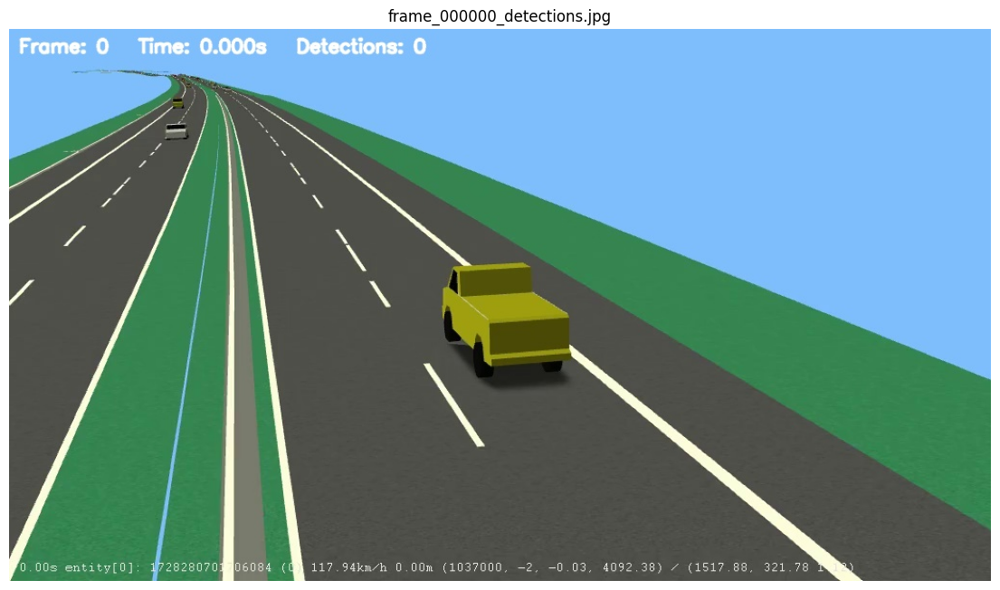


frame_000200_detections.jpg


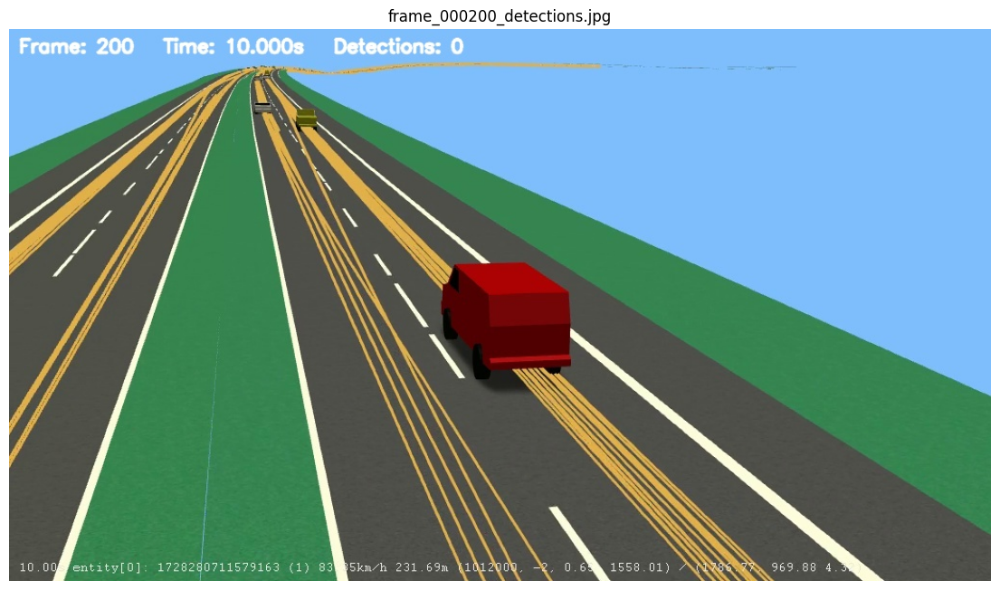


frame_000400_detections.jpg


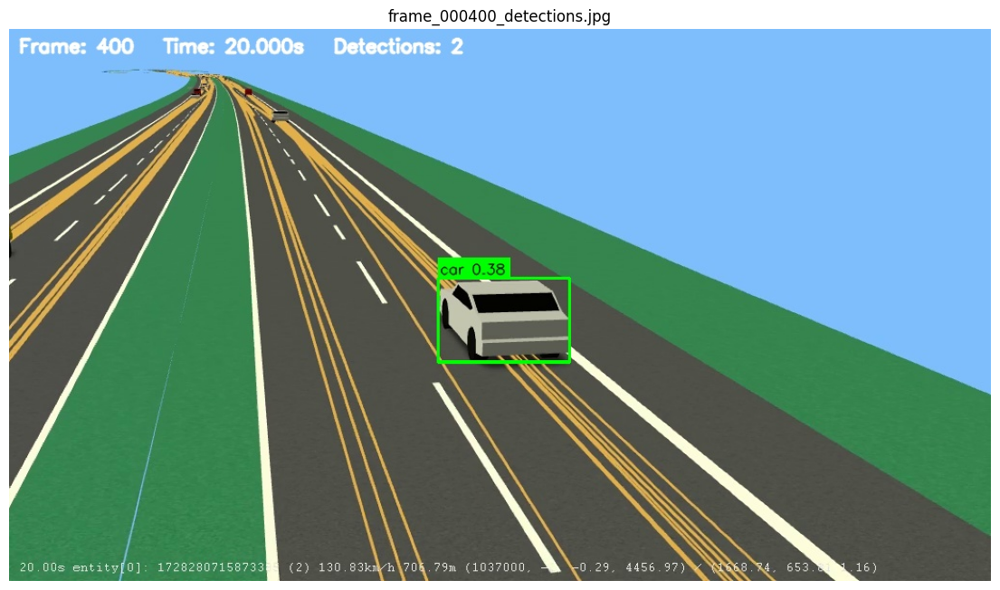


frame_000600_detections.jpg


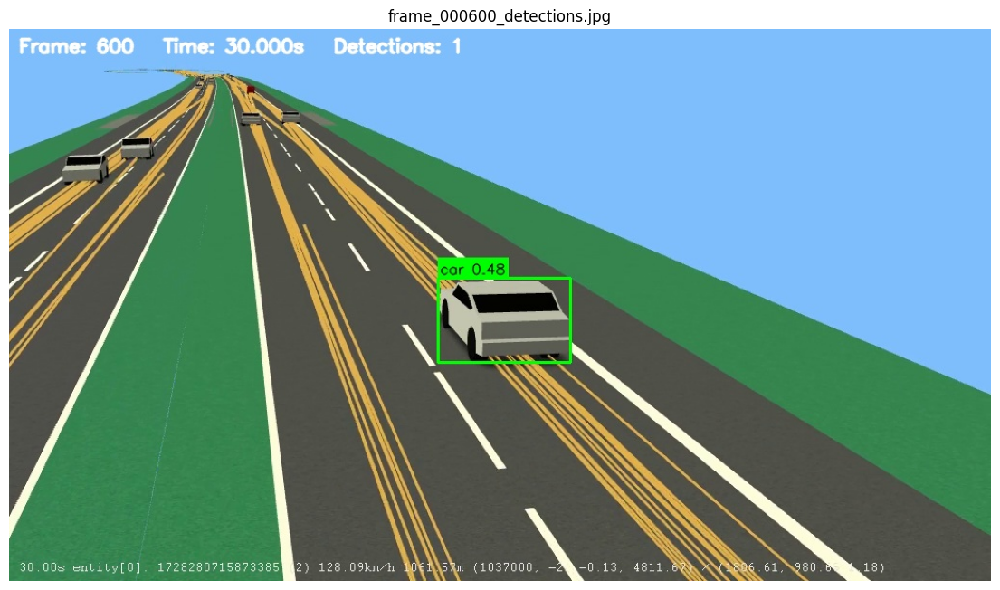


frame_000800_detections.jpg


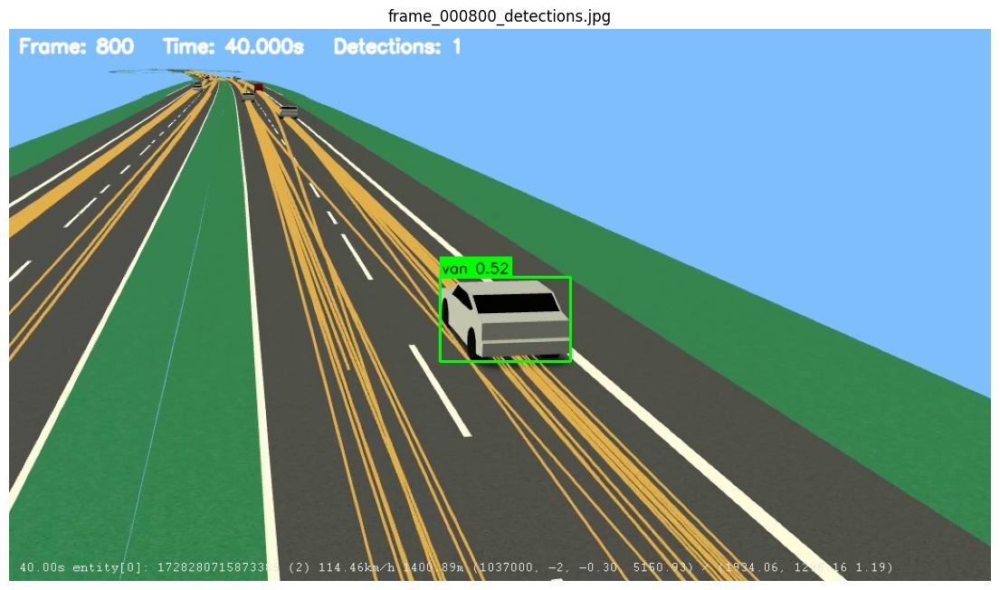


frame_001000_detections.jpg


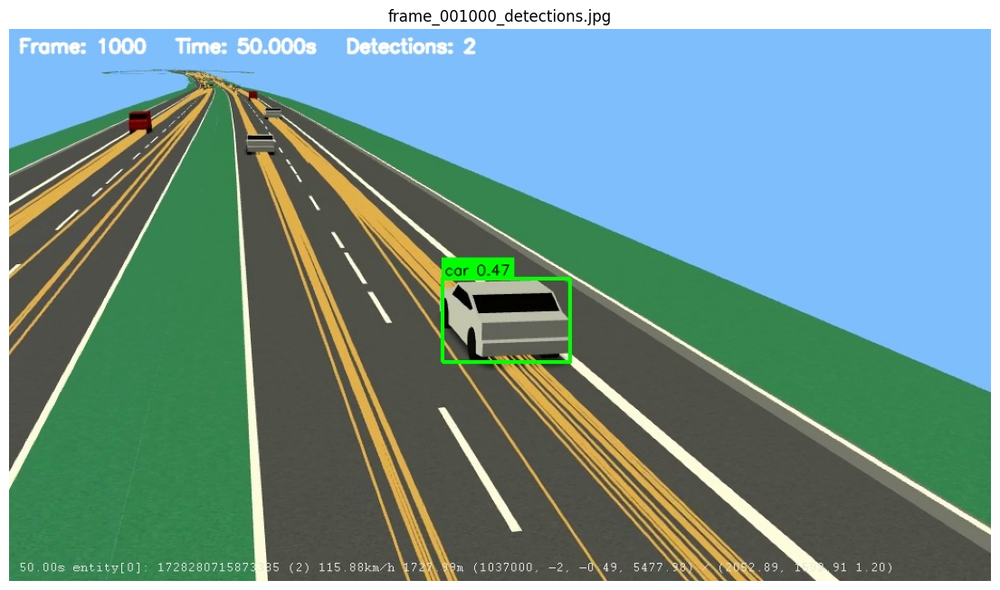


frame_001200_detections.jpg


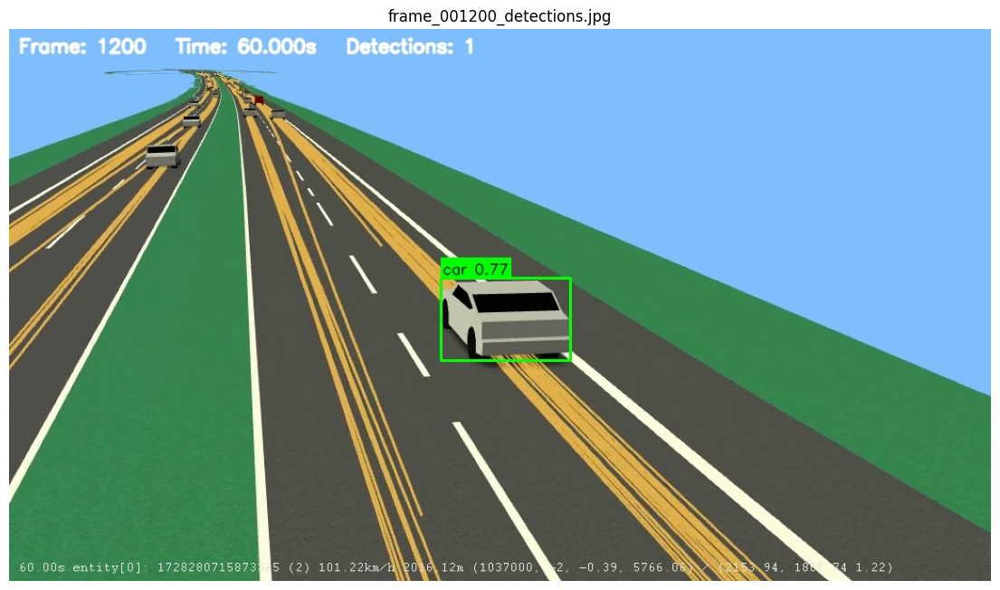

In [ ]:
#12
# ============================================================
# SESSION 3 — DISPLAY REPRESENTATIVE DETECTIONS
# ============================================================

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

VIS_DIR = Path("/content/detrac_stage2/target_cctv/visualizations")

visualization_files = sorted(
    VIS_DIR.glob("*_detections.jpg")
)

print("Found visualizations:", len(visualization_files))

for path in visualization_files:
    print(path)

# Display each separately so they are easy to inspect.
for path in visualization_files:
    print("\n" + "=" * 80)
    print(path.name)

    image = Image.open(path)

    plt.figure(figsize=(14, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title(path.name)
    plt.show()

In [ ]:
#13
# ============================================================
# Stage 2 Robustness Check: Higher Inference Resolution
# Same trained model, same 301 target frames, no retraining  (37)
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from ultralytics import YOLO
from PIL import Image
import json

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

PROJECT_ROOT = Path("/content/detrac_stage2")
FRAME_DIR = Path("/content/stage2_frames")
FRAME_INDEX = Path("/content/frame_index.csv")
MODEL_PATH = PROJECT_ROOT / "yolo11n_detrac_best.pt"

OUTPUT_ROOT = PROJECT_ROOT / "target_cctv_robustness_960"
DETECTIONS_CSV = OUTPUT_ROOT / "detections.csv"
SUMMARY_JSON = OUTPUT_ROOT / "summary.json"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

CONF = 0.25
IMGSZ = 960          # <-- only major change from original run
DEVICE = 0

CLASS_NAMES = {
    0: "car",
    1: "bus",
    2: "van",
    3: "others"
}

# ------------------------------------------------------------
# 3. Load Stage 1 frame index
# ------------------------------------------------------------

frame_index = pd.read_csv(FRAME_INDEX)

print("Stage 1 frame index:")
print(f"  Rows: {len(frame_index)}")
print(f"  Frame range: {frame_index['frame_number'].min()} "
      f"to {frame_index['frame_number'].max()}")
print(f"  Time range: {frame_index['timestamp_seconds'].min():.1f}s "
      f"to {frame_index['timestamp_seconds'].max():.1f}s")

# ------------------------------------------------------------
# 4. Check frames
# ------------------------------------------------------------

frame_paths = []

for _, row in frame_index.iterrows():
    frame_number = int(row["frame_number"])
    path = FRAME_DIR / f"frame_{frame_number:06d}.jpg"

    if not path.exists():
        raise FileNotFoundError(f"Missing frame: {path}")

    frame_paths.append(path)

print(f"PASS: all {len(frame_paths)} Stage 1 frames exist.")

# ------------------------------------------------------------
# 5. Load the SAME trained model
# ------------------------------------------------------------

model = YOLO(str(MODEL_PATH))

print("\nModel loaded:")
print(f"  {MODEL_PATH}")
print(f"  Inference confidence: {CONF}")
print(f"  Inference image size: {IMGSZ}")
print(f"  Device: {DEVICE}")

# ------------------------------------------------------------
# 6. Run inference
# ------------------------------------------------------------

records = []

for i, (_, row) in enumerate(frame_index.iterrows(), start=1):

    frame_number = int(row["frame_number"])
    timestamp = float(row["timestamp_seconds"])
    frame_path = FRAME_DIR / f"frame_{frame_number:06d}.jpg"

    results = model.predict(
        source=str(frame_path),
        conf=CONF,
        imgsz=IMGSZ,
        device=DEVICE,
        verbose=False
    )

    result = results[0]

    if result.boxes is None:
        continue

    boxes = result.boxes

    for j in range(len(boxes)):

        cls_id = int(boxes.cls[j].item())
        confidence = float(boxes.conf[j].item())

        x1, y1, x2, y2 = boxes.xyxy[j].tolist()

        records.append({
            "frame_number": frame_number,
            "timestamp_seconds": timestamp,
            "class": CLASS_NAMES.get(cls_id, str(cls_id)),
            "confidence": confidence,
            "x1": float(x1),
            "y1": float(y1),
            "x2": float(x2),
            "y2": float(y2)
        })

    if i % 25 == 0 or i == len(frame_index):
        print(f"{i}/{len(frame_index)} frames processed | "
              f"detections so far: {len(records)}")

# ------------------------------------------------------------
# 7. Save detections
# ------------------------------------------------------------

detections_df = pd.DataFrame(records)

detections_df.to_csv(DETECTIONS_CSV, index=False)

print("\nPASS: detection complete.")
print(f"Total detections: {len(detections_df)}")

# ------------------------------------------------------------
# 8. Summary statistics
# ------------------------------------------------------------

if len(detections_df) > 0:

    frame_detection_counts = (
        detections_df
        .groupby("frame_number")
        .size()
    )

    frames_with_detections = len(frame_detection_counts)

    class_counts = (
        detections_df["class"]
        .value_counts()
        .to_dict()
    )

    confidence_stats = {
        "mean": float(detections_df["confidence"].mean()),
        "std": float(detections_df["confidence"].std()),
        "min": float(detections_df["confidence"].min()),
        "median": float(detections_df["confidence"].median()),
        "max": float(detections_df["confidence"].max())
    }

    summary = {
        "inference_image_size": IMGSZ,
        "confidence_threshold": CONF,
        "total_frames": len(frame_index),
        "frames_with_detections": frames_with_detections,
        "frames_without_detections":
            len(frame_index) - frames_with_detections,
        "total_detections": len(detections_df),
        "mean_detections_per_frame":
            float(len(detections_df) / len(frame_index)),
        "max_detections_per_frame":
            int(frame_detection_counts.max()),
        "class_counts": class_counts,
        "confidence": confidence_stats
    }

else:

    summary = {
        "inference_image_size": IMGSZ,
        "confidence_threshold": CONF,
        "total_frames": len(frame_index),
        "frames_with_detections": 0,
        "frames_without_detections": len(frame_index),
        "total_detections": 0
    }

with open(SUMMARY_JSON, "w") as f:
    json.dump(summary, f, indent=2)

# ------------------------------------------------------------
# 9. Print results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ROBUSTNESS CHECK RESULTS")
print("=" * 70)

print(f"Inference size:       {IMGSZ}")
print(f"Confidence threshold: {CONF}")
print(f"Total frames:         {len(frame_index)}")
print(f"Frames detected:      {summary['frames_with_detections']}")
print(f"Frames empty:         {summary['frames_without_detections']}")
print(f"Total detections:     {summary['total_detections']}")
print(f"Mean detections/frame:{summary.get('mean_detections_per_frame', 0):.3f}")

print("\nClass counts:")
for cls, count in class_counts.items():
    print(f"  {cls}: {count}")

print("\nConfidence:")
for key, value in confidence_stats.items():
    print(f"  {key}: {value:.4f}")

print("\nSaved:")
print(DETECTIONS_CSV)
print(SUMMARY_JSON)

Stage 1 frame index:
  Rows: 301
  Frame range: 0 to 1200
  Time range: 0.0s to 60.0s
PASS: all 301 Stage 1 frames exist.

Model loaded:
  /content/detrac_stage2/yolo11n_detrac_best.pt
  Inference confidence: 0.25
  Inference image size: 960
  Device: 0
25/301 frames processed | detections so far: 2
50/301 frames processed | detections so far: 4
75/301 frames processed | detections so far: 4
100/301 frames processed | detections so far: 6
125/301 frames processed | detections so far: 32
150/301 frames processed | detections so far: 59
175/301 frames processed | detections so far: 85
200/301 frames processed | detections so far: 116
225/301 frames processed | detections so far: 147
250/301 frames processed | detections so far: 176
275/301 frames processed | detections so far: 203
300/301 frames processed | detections so far: 228
301/301 frames processed | detections so far: 229

PASS: detection complete.
Total detections: 229

ROBUSTNESS CHECK RESULTS
Inference size:       960
Confidenc

In [ ]:
#14
from pathlib import Path

checks = {
    "Stage 2 frames": Path("/content/stage2_frames"),
    "Frame index": Path("/content/frame_index.csv"),
    "Trained DETRAC model": Path("/content/detrac_stage2/yolo11n_detrac_best.pt"),
    "Target detections": Path("/content/detrac_stage2/target_cctv/detections.csv"),
    "960 robustness results": Path("/content/detrac_stage2/target_cctv_robustness_960/detections.csv"),
}

for name, path in checks.items():
    print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'}")

print("\n--- Frame count ---")
frame_dir = Path("/content/stage2_frames")
if frame_dir.exists():
    frames = list(frame_dir.glob("frame_*.jpg"))
    print("Frames:", len(frames))
else:
    print("stage2_frames folder missing")

Stage 2 frames: MISSING
Frame index: MISSING
Trained DETRAC model: MISSING
Target detections: MISSING
960 robustness results: MISSING

--- Frame count ---
stage2_frames folder missing


In [ ]:
#15
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#16
from pathlib import Path

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2"
)

(DRIVE_ROOT / "frames").mkdir(parents=True, exist_ok=True)
(DRIVE_ROOT / "models").mkdir(parents=True, exist_ok=True)
(DRIVE_ROOT / "results" / "target_cctv").mkdir(parents=True, exist_ok=True)
(DRIVE_ROOT / "results" / "robustness_960").mkdir(parents=True, exist_ok=True)

print(DRIVE_ROOT)
print("Created persistent Stage 2 storage.")

/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2
Created persistent Stage 2 storage.


In [ ]:
#17
from google.colab import files

uploaded = files.upload()

Saving DLR_HT_060000_060100.mp4 to DLR_HT_060000_060100.mp4


In [ ]:
#18
from pathlib import Path

video_path = Path("/content/DLR_HT_060000_060100.mp4")

print("Video exists:", video_path.exists())

if video_path.exists():
    print("Size:", round(video_path.stat().st_size / (1024**2), 2), "MB")

Video exists: True
Size: 15.15 MB


In [ ]:
#19
from pathlib import Path
import cv2
import csv
import shutil

VIDEO_PATH = Path("/content/DLR_HT_060000_060100.mp4")
DRIVE_STAGE2 = Path("/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2")
FRAME_DIR = DRIVE_STAGE2 / "frames"
FRAME_INDEX = DRIVE_STAGE2 / "frame_index.csv"

FRAME_DIR.mkdir(parents=True, exist_ok=True)

# Clear any partial recovery
for p in FRAME_DIR.glob("frame_*.jpg"):
    p.unlink()

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not open source video.")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

sample_interval = int(round(fps / 5.0))  # 5 FPS

rows = []
source_frame = 0
saved = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    if source_frame % sample_interval == 0:
        filename = f"frame_{source_frame:06d}.jpg"
        output_path = FRAME_DIR / filename

        if not cv2.imwrite(str(output_path), frame):
            raise RuntimeError(f"Failed to save {filename}")

        rows.append([
            source_frame,
            source_frame / fps,
            str(output_path)
        ])

        saved += 1

    source_frame += 1

cap.release()

with open(FRAME_INDEX, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["frame_number", "timestamp_seconds", "image_path"])
    writer.writerows(rows)

print("Recovery complete.")
print("FPS:", fps)
print("Source frames:", total_frames)
print("Extracted frames:", saved)
print("Frame directory:", FRAME_DIR)
print("Frame index:", FRAME_INDEX)

Recovery complete.
FPS: 20.0
Source frames: 1203
Extracted frames: 301
Frame directory: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/frames
Frame index: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/frame_index.csv


In [ ]:
#20
from pathlib import Path
import csv

DRIVE_STAGE2 = Path("/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2")
FRAME_DIR = DRIVE_STAGE2 / "frames"
FRAME_INDEX = DRIVE_STAGE2 / "frame_index.csv"

frames = sorted(FRAME_DIR.glob("frame_*.jpg"))

with open(FRAME_INDEX, newline="") as f:
    rows = list(csv.DictReader(f))

frame_numbers = [int(r["frame_number"]) for r in rows]
timestamps = [float(r["timestamp_seconds"]) for r in rows]

print("Frames on Drive:", len(frames))
print("CSV rows:", len(rows))
print("First frame:", frames[0].name if frames else "NONE")
print("Last frame:", frames[-1].name if frames else "NONE")
print("First frame number:", frame_numbers[0] if rows else "NONE")
print("Last frame number:", frame_numbers[-1] if rows else "NONE")
print("First timestamp:", timestamps[0] if rows else "NONE")
print("Last timestamp:", timestamps[-1] if rows else "NONE")

assert len(frames) == 301
assert len(rows) == 301
assert frame_numbers == list(range(0, 1201, 4))
assert all(timestamps[i] < timestamps[i+1] for i in range(len(timestamps)-1))
assert frames[0].exists() and frames[-1].exists()

print("\nPASS: Stage 1 recovery is complete and permanently stored in Google Drive.")

Frames on Drive: 301
CSV rows: 301
First frame: frame_000000.jpg
Last frame: frame_001200.jpg
First frame number: 0
Last frame number: 1200
First timestamp: 0.0
Last timestamp: 60.0

PASS: Stage 1 recovery is complete and permanently stored in Google Drive.


In [ ]:
#21
# ============================================================
# DETRAC MODEL RECOVERY
# Recreates the dataset + retrains YOLO11n + saves model to Drive
# ============================================================

import sys
import subprocess
from pathlib import Path
import shutil
import xml.etree.ElementTree as ET
from collections import Counter

# ------------------------------------------------------------
# 1. Install / verify Ultralytics
# ------------------------------------------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "ultralytics", "huggingface_hub"],
    check=True
)

import torch
from ultralytics import YOLO
from huggingface_hub import snapshot_download

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU is not available. Enable a Colab GPU before training.")

# ------------------------------------------------------------
# 2. Paths
# ------------------------------------------------------------
DRIVE_STAGE2 = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2"
)

DRIVE_MODEL = DRIVE_STAGE2 / "models" / "yolo11n_detrac_best.pt"
DRIVE_MODEL.parent.mkdir(parents=True, exist_ok=True)

ROOT = Path("/content/detrac_stage2_recovery")
RAW = ROOT / "raw"
YOLO_DATASET = ROOT / "yolo_dataset"
RUNS = ROOT / "runs"

ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. Download only the six DETRAC sequences previously used
# ------------------------------------------------------------
sequences = [
    "MVI_20012",
    "MVI_40161",
    "MVI_40192",
    "MVI_40752",
    "MVI_40962",
    "MVI_40963",
]

image_patterns = [
    f"DETRAC/DETRAC-Images/DETRAC-Images/{seq}/**"
    for seq in sequences
]

# XML annotations are small compared with the images, so download
# the complete DETRAC training annotation directory.
patterns = image_patterns + [
    "DETRAC/DETRAC-Train-Annotations-XML/**"
]

print("\nDownloading selected DETRAC data...")
snapshot_download(
    repo_id="kalyan1729/trafficmanagementdataset",
    repo_type="dataset",
    local_dir=str(RAW),
    allow_patterns=patterns,
)

print("Download complete.")

# ------------------------------------------------------------
# 4. Locate actual downloaded image / XML roots
# ------------------------------------------------------------
image_root_candidates = [
    RAW / "DETRAC" / "DETRAC-Images" / "DETRAC-Images",
    RAW / "DETRAC" / "DETRAC-Images",
]

image_root = next(
    (p for p in image_root_candidates if p.exists()),
    None
)

if image_root is None:
    raise RuntimeError("Could not locate DETRAC image directory.")

xml_root_candidates = [
    RAW / "DETRAC" / "DETRAC-Train-Annotations-XML" /
    "DETRAC-Train-Annotations-XML",
    RAW / "DETRAC" / "DETRAC-Train-Annotations-XML",
]

xml_root = next(
    (p for p in xml_root_candidates if p.exists()),
    None
)

if xml_root is None:
    raise RuntimeError("Could not locate DETRAC XML directory.")

print("Image root:", image_root)
print("XML root:", xml_root)

# ------------------------------------------------------------
# 5. Find sequence directories robustly
# ------------------------------------------------------------
seq_dirs = {}

for seq in sequences:
    candidates = list(image_root.rglob(seq))
    candidates = [p for p in candidates if p.is_dir()]

    if not candidates:
        raise RuntimeError(f"Image sequence not found: {seq}")

    seq_dirs[seq] = candidates[0]

print("\nSequences found:")
for seq, path in seq_dirs.items():
    count = len(list(path.glob("*.jpg")))
    print(f"{seq}: {count} images")

# ------------------------------------------------------------
# 6. Find XML files robustly
# ------------------------------------------------------------
xml_files = {}

for seq in sequences:
    candidates = list(xml_root.rglob(f"*{seq}*.xml"))

    if not candidates:
        raise RuntimeError(f"XML annotation not found: {seq}")

    # Prefer an exact filename if present.
    exact = [p for p in candidates if p.stem == seq]
    xml_files[seq] = exact[0] if exact else candidates[0]

print("\nXML files found:")
for seq, path in xml_files.items():
    print(seq, "->", path)

# ------------------------------------------------------------
# 7. XML parser
# ------------------------------------------------------------
def parse_detrac_xml(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()

    frame_data = {}

    for frame in root.findall(".//frame"):
        frame_num = int(frame.attrib["num"])
        boxes = []

        target_list = frame.find("target_list")

        if target_list is None:
            frame_data[frame_num] = boxes
            continue

        for target in target_list.findall("target"):
            box = target.find("box")
            attr = target.find("attribute")

            if box is None or attr is None:
                continue

            vehicle_type = attr.attrib.get("vehicle_type")

            if vehicle_type not in {"car", "bus", "van", "others"}:
                continue

            left = float(box.attrib["left"])
            top = float(box.attrib["top"])
            width = float(box.attrib["width"])
            height = float(box.attrib["height"])

            if width <= 0 or height <= 0:
                continue

            boxes.append(
                (vehicle_type, left, top, width, height)
            )

        frame_data[frame_num] = boxes

    return frame_data

# ------------------------------------------------------------
# 8. Build YOLO dataset
# ------------------------------------------------------------
if YOLO_DATASET.exists():
    shutil.rmtree(YOLO_DATASET)

for split in ["train", "val"]:
    (YOLO_DATASET / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DATASET / "labels" / split).mkdir(parents=True, exist_ok=True)

class_map = {
    "car": 0,
    "bus": 1,
    "van": 2,
    "others": 3,
}

# Same split as the successful previous training:
# MVI_40963 = validation
train_sequences = [
    "MVI_20012",
    "MVI_40161",
    "MVI_40192",
    "MVI_40752",
    "MVI_40962",
]

val_sequences = ["MVI_40963"]

stats = Counter()

def convert_sequence(seq, split):
    image_dir = seq_dirs[seq]
    annotations = parse_detrac_xml(xml_files[seq])

    image_files = sorted(image_dir.glob("*.jpg"))

    for image_path in image_files:
        # DETRAC image names are normally frame-based.
        # Extract the final numeric component from the filename.
        digits = "".join(
            ch if ch.isdigit() else " "
            for ch in image_path.stem
        ).split()

        if not digits:
            continue

        frame_num = int(digits[-1])

        boxes = annotations.get(frame_num, [])

        # Read image dimensions.
        import cv2
        img = cv2.imread(str(image_path))

        if img is None:
            continue

        h, w = img.shape[:2]

        out_stem = f"{seq}_{image_path.stem}"

        dst_img = YOLO_DATASET / "images" / split / f"{out_stem}.jpg"
        dst_lbl = YOLO_DATASET / "labels" / split / f"{out_stem}.txt"

        shutil.copy2(image_path, dst_img)

        with open(dst_lbl, "w") as f:
            for vehicle_type, left, top, width, height in boxes:
                xc = (left + width / 2) / w
                yc = (top + height / 2) / h
                nw = width / w
                nh = height / h

                cls = class_map[vehicle_type]

                f.write(
                    f"{cls} {xc:.6f} {yc:.6f} "
                    f"{nw:.6f} {nh:.6f}\n"
                )

                stats[(split, vehicle_type)] += 1

        stats[(split, "images")] += 1

for seq in train_sequences:
    convert_sequence(seq, "train")

for seq in val_sequences:
    convert_sequence(seq, "val")

# ------------------------------------------------------------
# 9. Write YAML
# ------------------------------------------------------------
yaml_path = YOLO_DATASET / "data.yaml"

yaml_path.write_text(
    f"""path: {YOLO_DATASET}
train: images/train
val: images/val
nc: 4
names:
  0: car
  1: bus
  2: van
  3: others
"""
)

train_images = len(list((YOLO_DATASET / "images" / "train").glob("*.jpg")))
val_images = len(list((YOLO_DATASET / "images" / "val").glob("*.jpg")))

train_labels = len(list((YOLO_DATASET / "labels" / "train").glob("*.txt")))
val_labels = len(list((YOLO_DATASET / "labels" / "val").glob("*.txt")))

print("\nDataset rebuilt:")
print("Train images:", train_images)
print("Train labels:", train_labels)
print("Val images:", val_images)
print("Val labels:", val_labels)

print("\nBox counts:")
for cls in ["car", "bus", "van", "others"]:
    print(
        cls,
        "train =", stats[("train", cls)],
        "val =", stats[("val", cls)]
    )

# ------------------------------------------------------------
# 10. Train exactly the successful baseline
# ------------------------------------------------------------
print("\nStarting YOLO11n DETRAC training...")

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    seed=42,
    patience=8,
    cache=False,
    pretrained=True,
    plots=True,
    project=str(RUNS),
    name="yolo11n_detrac_baseline",
    exist_ok=True,
)

# ------------------------------------------------------------
# 11. Find and permanently save best model
# ------------------------------------------------------------
best_path = (
    RUNS /
    "yolo11n_detrac_baseline" /
    "weights" /
    "best.pt"
)

if not best_path.exists():
    raise RuntimeError(f"Training completed but best.pt not found: {best_path}")

shutil.copy2(best_path, DRIVE_MODEL)

print("\n================================================")
print("DETRAC MODEL RECOVERY COMPLETE")
print("================================================")
print("Best model:", best_path)
print("Permanent Drive copy:", DRIVE_MODEL)
print("Model size (MB):", round(DRIVE_MODEL.stat().st_size / (1024**2), 2))
print("================================================")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch: 2.11.0+cu130
CUDA available: True



Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10400 files:   0%|          | 0/10400 [00:00<?, ?it/s]

Download complete.
Image root: /content/detrac_stage2_recovery/raw/DETRAC/DETRAC-Images/DETRAC-Images
XML root: /content/detrac_stage2_recovery/raw/DETRAC/DETRAC-Train-Annotations-XML/DETRAC-Train-Annotations-XML

Sequences found:
MVI_20012: 936 images
MVI_40161: 1490 images
MVI_40192: 2195 images
MVI_40752: 2025 images
MVI_40962: 1875 images
MVI_40963: 1820 images

XML files found:
MVI_20012 -> /content/detrac_stage2_recovery/raw/DETRAC/DETRAC-Train-Annotations-XML/DETRAC-Train-Annotations-XML/MVI_20012.xml
MVI_40161 -> /content/detrac_stage2_recovery/raw/DETRAC/DETRAC-Train-Annotations-XML/DETRAC-Train-Annotations-XML/MVI_40161.xml
MVI_40192 -> /content/detrac_stage2_recovery/raw/DETRAC/DETRAC-Train-Annotations-XML/DETRAC-Train-Annotations-XML/MVI_40192.xml
MVI_40752 -> /content/detrac_stage2_recovery/raw/DETRAC/DETRAC-Train-Annotations-XML/DETRAC-Train-Annotations-XML/MVI_40752.xml
MVI_40962 -> /content/detrac_stage2_recovery/raw/DETRAC/DETRAC-Train-Annotations-XML/DETRAC-Train-Anno

In [ ]:
#22
from pathlib import Path
import csv
import json
from collections import Counter

from ultralytics import YOLO
import pandas as pd

# ============================================================
# Permanent Drive paths
# ============================================================
STAGE2 = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2"
)

FRAME_DIR = STAGE2 / "frames"
FRAME_INDEX = STAGE2 / "frame_index.csv"
MODEL_PATH = STAGE2 / "models" / "yolo11n_detrac_best.pt"

OUTPUT_ROOT = STAGE2 / "results" / "target_cctv"
VIS_DIR = OUTPUT_ROOT / "visualizations"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
VIS_DIR.mkdir(parents=True, exist_ok=True)

DETECTIONS_CSV = OUTPUT_ROOT / "detections.csv"
SUMMARY_JSON = OUTPUT_ROOT / "summary.json"

# ============================================================
# Configuration
# ============================================================
CONF = 0.25
IMGSZ = 640

CLASS_NAMES = {
    0: "car",
    1: "bus",
    2: "van",
    3: "others",
}

VIS_FRAMES = {0, 200, 400, 600, 800, 1000, 1200}

# ============================================================
# Verify permanent artifacts before inference
# ============================================================
assert FRAME_DIR.exists(), f"Missing frame directory: {FRAME_DIR}"
assert FRAME_INDEX.exists(), f"Missing frame index: {FRAME_INDEX}"
assert MODEL_PATH.exists(), f"Missing model: {MODEL_PATH}"

frame_paths = sorted(FRAME_DIR.glob("frame_*.jpg"))

with open(FRAME_INDEX, newline="") as f:
    frame_index = list(csv.DictReader(f))

assert len(frame_paths) == 301
assert len(frame_index) == 301

print("Permanent artifacts verified:")
print("  Frames:", len(frame_paths))
print("  Frame index rows:", len(frame_index))
print("  Model:", MODEL_PATH)

# ============================================================
# Load model
# ============================================================
model = YOLO(str(MODEL_PATH))

print("\nModel loaded successfully.")
print("Classes:", model.names)

# ============================================================
# Run inference
# ============================================================
rows = []
frame_detection_counts = []

for i, record in enumerate(frame_index):

    frame_number = int(record["frame_number"])
    timestamp = float(record["timestamp_seconds"])
    image_path = FRAME_DIR / Path(record["image_path"]).name

    if not image_path.exists():
        raise FileNotFoundError(image_path)

    results = model.predict(
        source=str(image_path),
        conf=CONF,
        imgsz=IMGSZ,
        device=0,
        verbose=False,
    )

    result = results[0]

    count = 0

    if result.boxes is not None:
        for box in result.boxes:
            cls_id = int(box.cls.item())
            confidence = float(box.conf.item())

            x1, y1, x2, y2 = box.xyxy[0].tolist()

            rows.append({
                "frame_number": frame_number,
                "timestamp_seconds": timestamp,
                "class": CLASS_NAMES.get(cls_id, str(cls_id)),
                "confidence": confidence,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
            })

            count += 1

    frame_detection_counts.append(count)

    # Save selected visualization frames directly to Drive.
    if frame_number in VIS_FRAMES:
        annotated = result.plot()

        import cv2

        visual_path = VIS_DIR / f"frame_{frame_number:06d}_detections.jpg"

        cv2.imwrite(str(visual_path), annotated)

# ============================================================
# Save detections
# ============================================================
columns = [
    "frame_number",
    "timestamp_seconds",
    "class",
    "confidence",
    "x1",
    "y1",
    "x2",
    "y2",
]

df = pd.DataFrame(rows, columns=columns)
df.to_csv(DETECTIONS_CSV, index=False)

# ============================================================
# Summary
# ============================================================
class_counts = Counter(df["class"]) if len(df) else Counter()

summary = {
    "model": str(MODEL_PATH),
    "confidence_threshold": CONF,
    "image_size": IMGSZ,
    "total_frames": len(frame_index),
    "frames_with_detections": sum(c > 0 for c in frame_detection_counts),
    "frames_without_detections": sum(c == 0 for c in frame_detection_counts),
    "total_detections": len(df),
    "min_detections_per_frame": min(frame_detection_counts),
    "max_detections_per_frame": max(frame_detection_counts),
    "mean_detections_per_frame": (
        sum(frame_detection_counts) / len(frame_detection_counts)
    ),
    "median_detections_per_frame": float(
        pd.Series(frame_detection_counts).median()
    ),
    "class_counts": dict(class_counts),
    "visualizations": len(list(VIS_DIR.glob("*.jpg"))),
}

if len(df):
    summary["confidence"] = {
        "mean": float(df["confidence"].mean()),
        "std": float(df["confidence"].std()),
        "min": float(df["confidence"].min()),
        "median": float(df["confidence"].median()),
        "max": float(df["confidence"].max()),
    }

with open(SUMMARY_JSON, "w") as f:
    json.dump(summary, f, indent=2)

# ============================================================
# Final verification
# ============================================================
assert DETECTIONS_CSV.exists()
assert SUMMARY_JSON.exists()
assert len(list(VIS_DIR.glob("*.jpg"))) == len(VIS_FRAMES)

print("\n================================================")
print("TARGET CCTV INFERENCE COMPLETE")
print("================================================")
print("Total detections:", summary["total_detections"])
print("Frames with detections:", summary["frames_with_detections"])
print("Frames without detections:", summary["frames_without_detections"])
print("Mean detections/frame:", round(summary["mean_detections_per_frame"], 3))
print("Class counts:", summary["class_counts"])

if "confidence" in summary:
    print("Mean confidence:", round(summary["confidence"]["mean"], 4))
    print("Max confidence:", round(summary["confidence"]["max"], 4))

print("\nPermanent outputs:")
print("  Detections:", DETECTIONS_CSV)
print("  Summary:", SUMMARY_JSON)
print("  Visualizations:", VIS_DIR)
print("================================================")

Permanent artifacts verified:
  Frames: 301
  Frame index rows: 301
  Model: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_detrac_best.pt

Model loaded successfully.
Classes: {0: 'car', 1: 'bus', 2: 'van', 3: 'others'}

TARGET CCTV INFERENCE COMPLETE
Total detections: 458
Frames with detections: 301
Frames without detections: 0
Mean detections/frame: 1.522
Class counts: {'van': 358, 'car': 81, 'bus': 19}
Mean confidence: 0.6919
Max confidence: 0.9529

Permanent outputs:
  Detections: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/results/target_cctv/detections.csv
  Summary: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/results/target_cctv/summary.json
  Visualizations: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/results/target_cctv/visualizations


Visualizations found: 7

frame_000000_detections.jpg


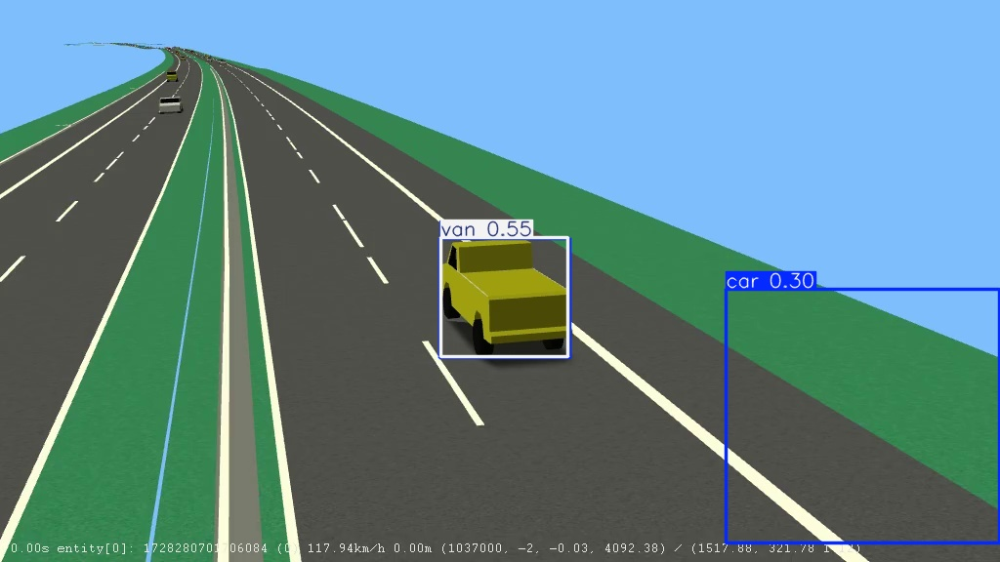

frame_000200_detections.jpg


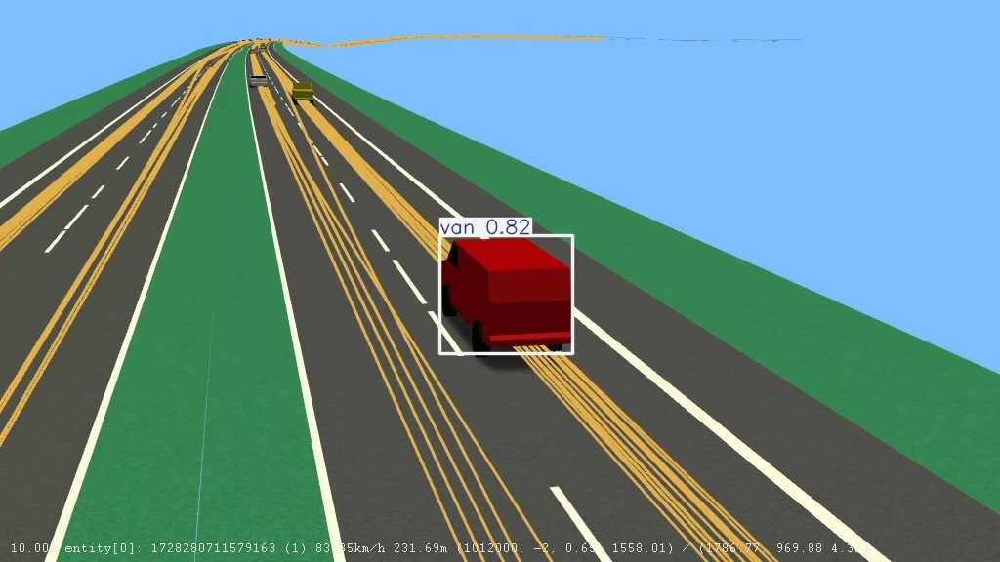

frame_000400_detections.jpg


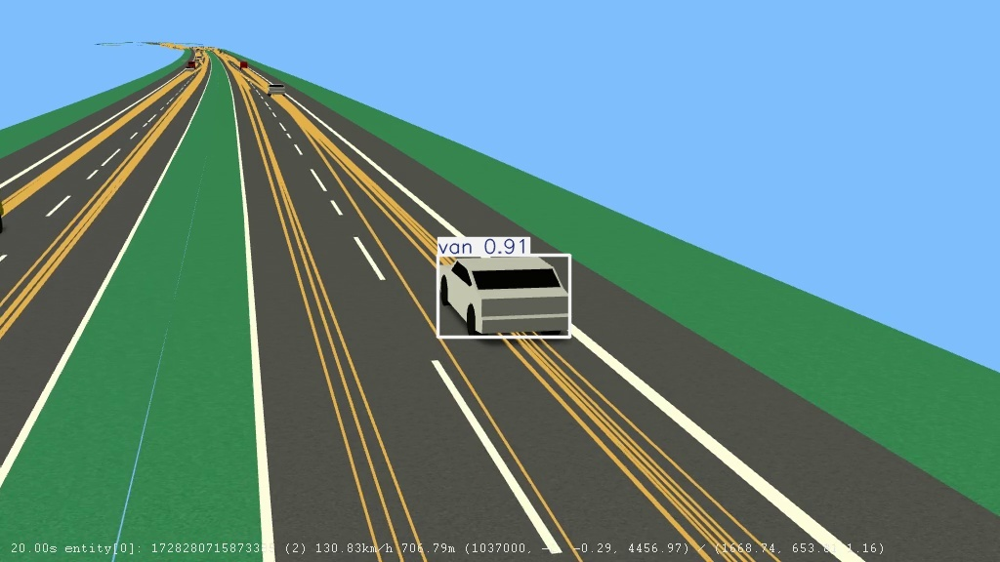

frame_000600_detections.jpg


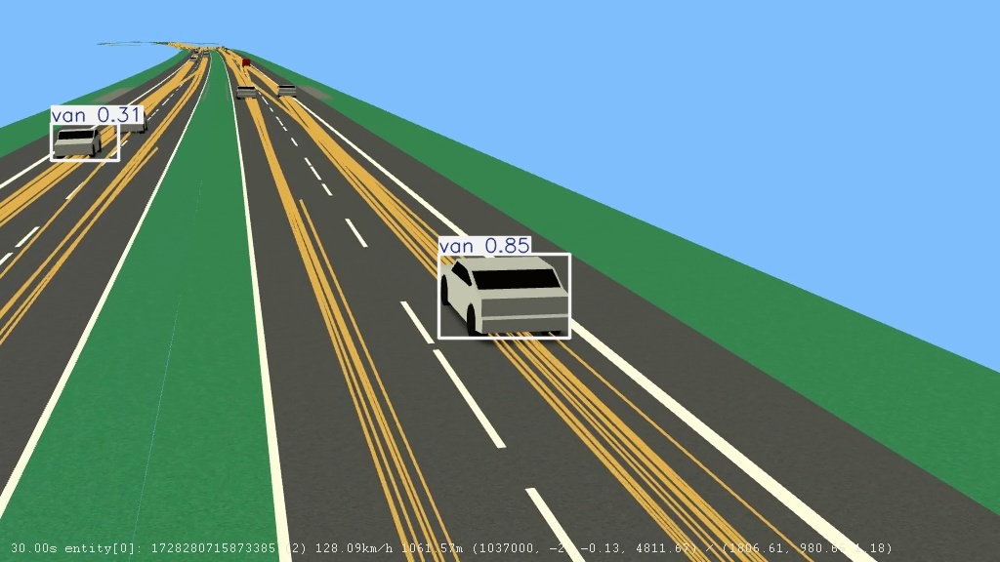

frame_000800_detections.jpg


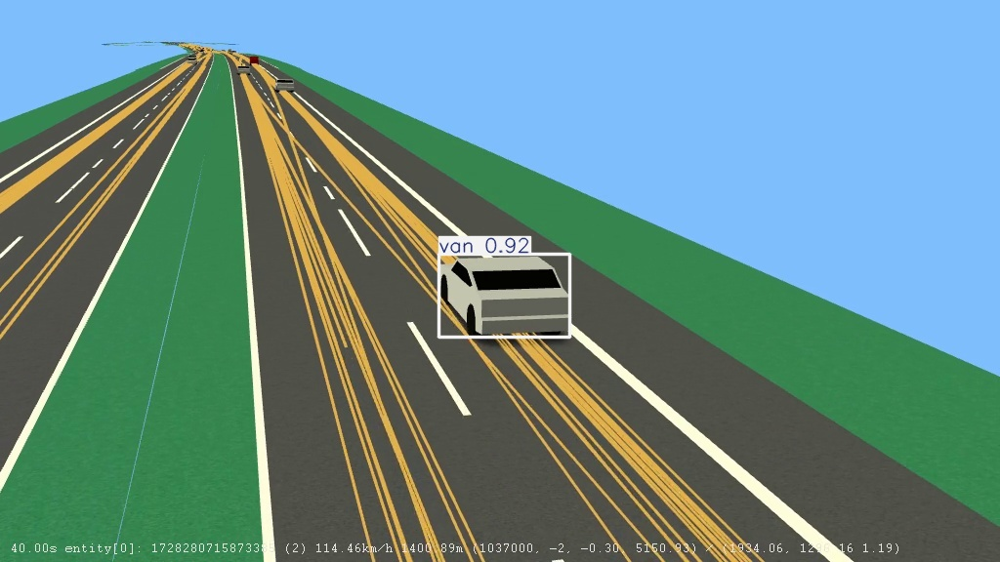

frame_001000_detections.jpg


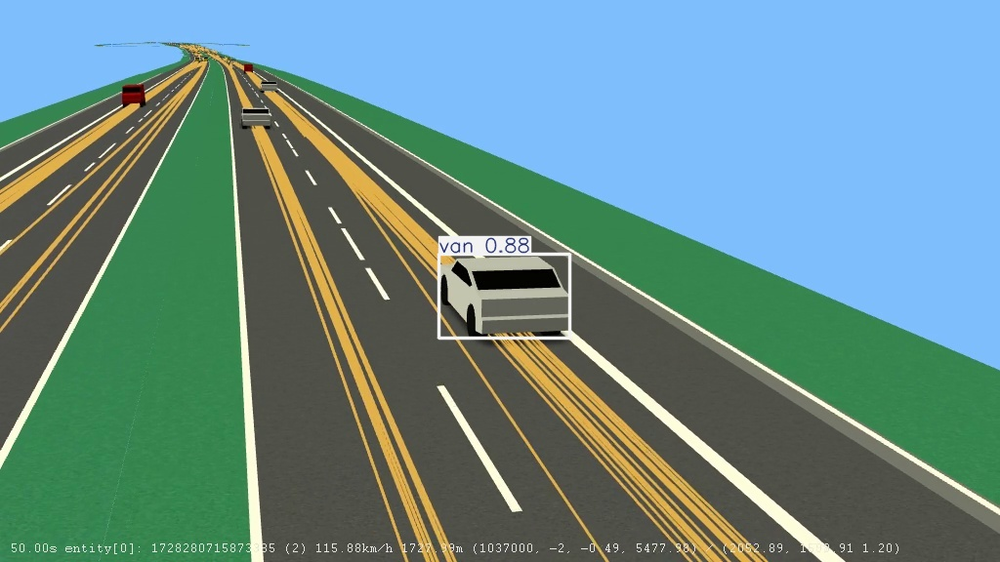

frame_001200_detections.jpg


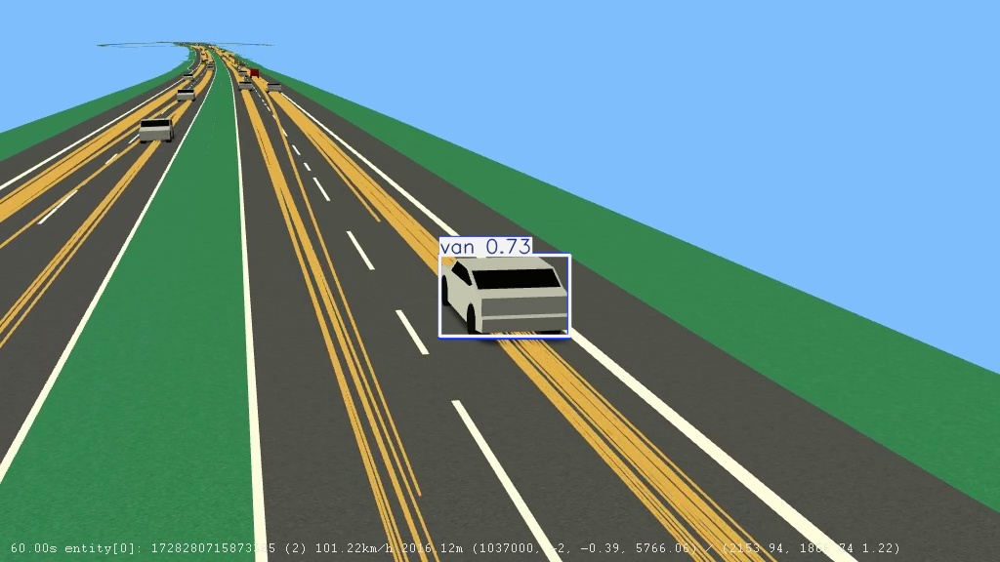

In [ ]:
#23
from pathlib import Path
from IPython.display import display, Image

VIS_DIR = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/results/target_cctv/visualizations"
)

visualizations = sorted(VIS_DIR.glob("*.jpg"))

print("Visualizations found:", len(visualizations))
print()

for path in visualizations:
    print(path.name)
    display(Image(filename=str(path), width=900))

In [ ]:
#24
from google.colab import files
from pathlib import Path
import shutil
import cv2

UPLOAD_DIR = Path("/content/fetv_test")
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)

print("Select the 3 FETV clips:")
uploaded = files.upload()

for name in uploaded:
    src = Path("/content") / name
    dst = UPLOAD_DIR / name
    shutil.move(str(src), str(dst))

print("\nUploaded files:")
for p in sorted(UPLOAD_DIR.glob("*.mp4")):
    print(f"  {p.name}  |  {p.stat().st_size / (1024**2):.2f} MB")

print("\n" + "=" * 70)
print("VIDEO INFORMATION")
print("=" * 70)

for video_path in sorted(UPLOAD_DIR.glob("*.mp4")):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        print(f"\nFAILED: {video_path.name}")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = frames / fps if fps else 0

    cap.release()

    print(f"\n{video_path.name}")
    print(f"  Resolution : {width} × {height}")
    print(f"  FPS        : {fps:.2f}")
    print(f"  Frames     : {frames}")
    print(f"  Duration   : {duration:.2f} sec")

Select the 3 FETV clips:


Saving 006_020.mp4 to 006_020.mp4
Saving 004_005.mp4 to 004_005.mp4
Saving 001_020.mp4 to 001_020.mp4

Uploaded files:
  001_020.mp4  |  5.99 MB
  004_005.mp4  |  2.32 MB
  006_020.mp4  |  1.11 MB

VIDEO INFORMATION

001_020.mp4
  Resolution : 1920 × 1920
  FPS        : 14.59
  Frames     : 116
  Duration   : 7.95 sec

004_005.mp4
  Resolution : 1920 × 1080
  FPS        : 15.09
  Frames     : 122
  Duration   : 8.08 sec

006_020.mp4
  Resolution : 1920 × 1080
  FPS        : 15.48
  Frames     : 48
  Duration   : 3.10 sec


In [ ]:
#25
# ============================================================
# FETV REAL CCTV TRANSFER TEST
# Existing DETRAC-trained YOLO11n
# ============================================================

from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

FETV_DIR = Path("/content/fetv_test")

MODEL_PATH = Path(
    "/content/drive/MyDrive/DAA_Project/"
    "traffic-investigation-system/stage2/models/"
    "yolo11n_detrac_best.pt"
)

OUTPUT_DIR = Path("/content/fetv_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Model exists:", MODEL_PATH.exists())
print("FETV directory exists:", FETV_DIR.exists())

# ------------------------------------------------------------
# 2. Load model
# ------------------------------------------------------------

model = YOLO(str(MODEL_PATH))

print("\nModel loaded.")
print("Classes:", model.names)

# ------------------------------------------------------------
# 3. Videos
# ------------------------------------------------------------

videos = sorted(FETV_DIR.glob("*.mp4"))

print("\nVideos:")
for v in videos:
    print(" ", v.name)

# ------------------------------------------------------------
# 4. Run inference
# ------------------------------------------------------------

CONF = 0.25
IMGSZ = 640

all_results = []
summary = {}

for video_path in videos:

    print("\n" + "=" * 70)
    print(f"PROCESSING: {video_path.name}")
    print("=" * 70)

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        print("FAILED TO OPEN")
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    video_output = OUTPUT_DIR / video_path.stem
    video_output.mkdir(parents=True, exist_ok=True)

    frame_detection_counts = []
    class_counts = {}
    confidences = []

    # Frames to visualize:
    # beginning, early-middle, middle, late-middle, end
    if total_frames <= 5:
        vis_indices = list(range(total_frames))
    else:
        vis_indices = np.linspace(
            0, total_frames - 1, 5, dtype=int
        ).tolist()

    vis_frames = {}

    frame_number = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        timestamp = frame_number / fps if fps > 0 else 0.0

        # ----------------------------------------------------
        # Inference
        # ----------------------------------------------------

        result = model.predict(
            source=frame,
            conf=CONF,
            imgsz=IMGSZ,
            device=0,
            verbose=False
        )[0]

        detections_this_frame = 0

        if result.boxes is not None and len(result.boxes) > 0:

            boxes = result.boxes.xyxy.cpu().numpy()
            classes = result.boxes.cls.cpu().numpy().astype(int)
            scores = result.boxes.conf.cpu().numpy()

            detections_this_frame = len(boxes)

            for box, cls_id, score in zip(boxes, classes, scores):

                class_name = model.names[int(cls_id)]

                x1, y1, x2, y2 = box.tolist()

                all_results.append({
                    "video": video_path.name,
                    "frame_number": frame_number,
                    "timestamp_seconds": timestamp,
                    "class": class_name,
                    "confidence": float(score),
                    "x1": float(x1),
                    "y1": float(y1),
                    "x2": float(x2),
                    "y2": float(y2)
                })

                class_counts[class_name] = (
                    class_counts.get(class_name, 0) + 1
                )

                confidences.append(float(score))

        frame_detection_counts.append(detections_this_frame)

        # ----------------------------------------------------
        # Save selected frames for visual inspection
        # ----------------------------------------------------

        if frame_number in vis_indices:
            annotated = result.plot()

            vis_frames[frame_number] = (
                annotated[:, :, ::-1].copy()
            )

        frame_number += 1

    cap.release()

    # --------------------------------------------------------
    # Statistics
    # --------------------------------------------------------

    frame_detection_counts = np.array(frame_detection_counts)

    frames_with_detections = int(
        np.sum(frame_detection_counts > 0)
    )

    frames_without_detections = int(
        np.sum(frame_detection_counts == 0)
    )

    total_detections = int(
        np.sum(frame_detection_counts)
    )

    mean_detections = float(
        np.mean(frame_detection_counts)
    )

    if confidences:
        conf_array = np.array(confidences)

        conf_stats = {
            "mean": float(np.mean(conf_array)),
            "std": float(np.std(conf_array)),
            "min": float(np.min(conf_array)),
            "median": float(np.median(conf_array)),
            "max": float(np.max(conf_array))
        }
    else:
        conf_stats = {
            "mean": None,
            "std": None,
            "min": None,
            "median": None,
            "max": None
        }

    summary[video_path.name] = {
        "fps": float(fps),
        "frames": total_frames,
        "duration_seconds": (
            float(total_frames / fps) if fps > 0 else None
        ),
        "total_detections": total_detections,
        "frames_with_detections": frames_with_detections,
        "frames_without_detections": frames_without_detections,
        "mean_detections_per_frame": mean_detections,
        "class_counts": class_counts,
        "confidence": conf_stats
    }

    # --------------------------------------------------------
    # Save visualizations
    # --------------------------------------------------------

    for frame_number, image in vis_frames.items():

        out_path = (
            video_output /
            f"frame_{frame_number:04d}.jpg"
        )

        plt.figure(figsize=(10, 10))
        plt.imshow(image)
        plt.axis("off")
        plt.title(
            f"{video_path.name} | "
            f"Frame {frame_number} | "
            f"{frame_number / fps:.2f}s"
        )
        plt.tight_layout()
        plt.savefig(
            out_path,
            dpi=120,
            bbox_inches="tight"
        )
        plt.close()

    print(f"\nFrames: {total_frames}")
    print(f"Duration: {total_frames / fps:.2f}s")
    print(f"Total detections: {total_detections}")
    print(f"Frames with detections: {frames_with_detections}/{total_frames}")
    print(f"Frames without detections: {frames_without_detections}")
    print(f"Mean detections/frame: {mean_detections:.3f}")
    print("Class counts:", class_counts)
    print("Confidence:", conf_stats)

# ------------------------------------------------------------
# 5. Save detection CSV
# ------------------------------------------------------------

detections_df = pd.DataFrame(all_results)

csv_path = OUTPUT_DIR / "detections.csv"
detections_df.to_csv(csv_path, index=False)

# ------------------------------------------------------------
# 6. Save summary
# ------------------------------------------------------------

summary_path = OUTPUT_DIR / "summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# ------------------------------------------------------------
# 7. Final comparison table
# ------------------------------------------------------------

comparison_rows = []

for video_name, s in summary.items():

    row = {
        "video": video_name,
        "frames": s["frames"],
        "duration_s": round(s["duration_seconds"], 2),
        "total_detections": s["total_detections"],
        "frames_with_detections": s["frames_with_detections"],
        "frames_without_detections": s["frames_without_detections"],
        "mean_detections/frame": round(
            s["mean_detections_per_frame"], 3
        ),
        "mean_confidence": (
            round(s["confidence"]["mean"], 3)
            if s["confidence"]["mean"] is not None
            else None
        )
    }

    comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)

print("\n")
print("=" * 90)
print("FINAL FETV TRANSFER-TEST COMPARISON")
print("=" * 90)

display(comparison_df)

print("\nClass counts:")
for video_name, s in summary.items():
    print(f"\n{video_name}")
    for cls, count in s["class_counts"].items():
        print(f"  {cls}: {count}")

print("\nSaved:")
print("  Detections:", csv_path)
print("  Summary:   ", summary_path)
print("  Visuals:   ", OUTPUT_DIR)

Model exists: True
FETV directory exists: True

Model loaded.
Classes: {0: 'car', 1: 'bus', 2: 'van', 3: 'others'}

Videos:
  001_020.mp4
  004_005.mp4
  006_020.mp4

PROCESSING: 001_020.mp4

Frames: 116
Duration: 7.95s
Total detections: 34
Frames with detections: 31/116
Frames without detections: 85
Mean detections/frame: 0.293
Class counts: {'car': 27, 'bus': 7}
Confidence: {'mean': 0.354181508807575, 'std': 0.13647866566779285, 'min': 0.25142738223075867, 'median': 0.309700146317482, 'max': 0.8584945797920227}

PROCESSING: 004_005.mp4

Frames: 122
Duration: 8.08s
Total detections: 204
Frames with detections: 109/122
Frames without detections: 13
Mean detections/frame: 1.672
Class counts: {'car': 204}
Confidence: {'mean': 0.4833953580727764, 'std': 0.20487676143459915, 'min': 0.25150907039642334, 'median': 0.41169629991054535, 'max': 0.9322602152824402}

PROCESSING: 006_020.mp4

Frames: 48
Duration: 3.10s
Total detections: 38
Frames with detections: 24/48
Frames without detections: 2

,video,frames,duration_s,total_detections,frames_with_detections,frames_without_detections,mean_detections/frame,mean_confidence
0,001_020.mp4,116,7.95,34,31,85,0.293,0.354
1,004_005.mp4,122,8.08,204,109,13,1.672,0.483
2,006_020.mp4,48,3.10,38,24,24,0.792,0.603



Class counts:

001_020.mp4
  car: 27
  bus: 7

004_005.mp4
  car: 204

006_020.mp4
  car: 30
  van: 2
  bus: 6

Saved:
  Detections: /content/fetv_results/detections.csv
  Summary:    /content/fetv_results/summary.json
  Visuals:    /content/fetv_results


Found 5 visualization frames.


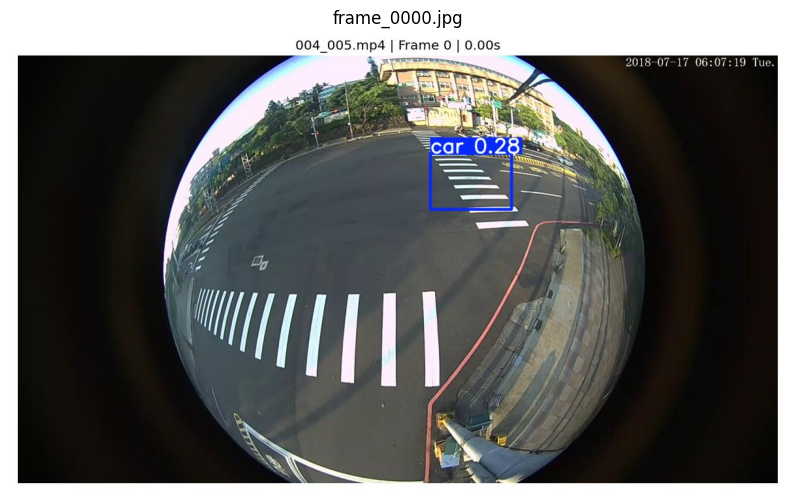

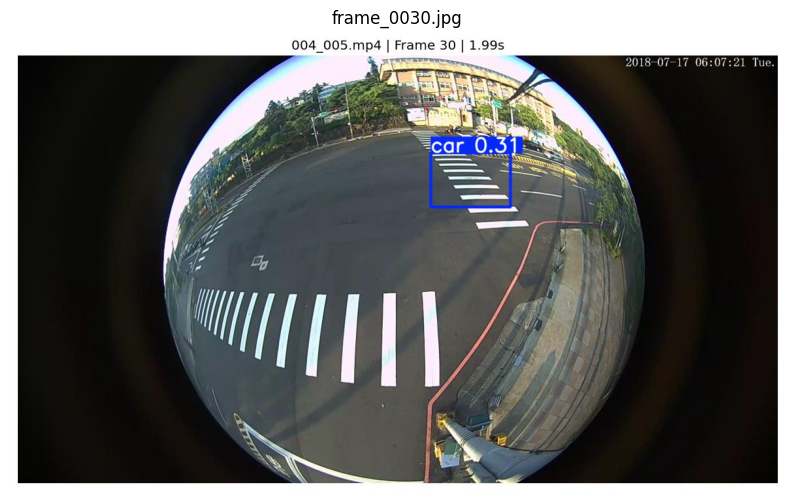

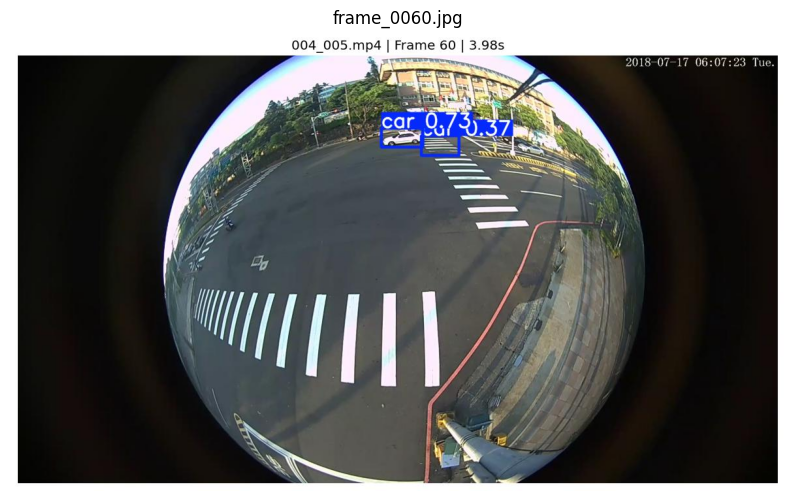

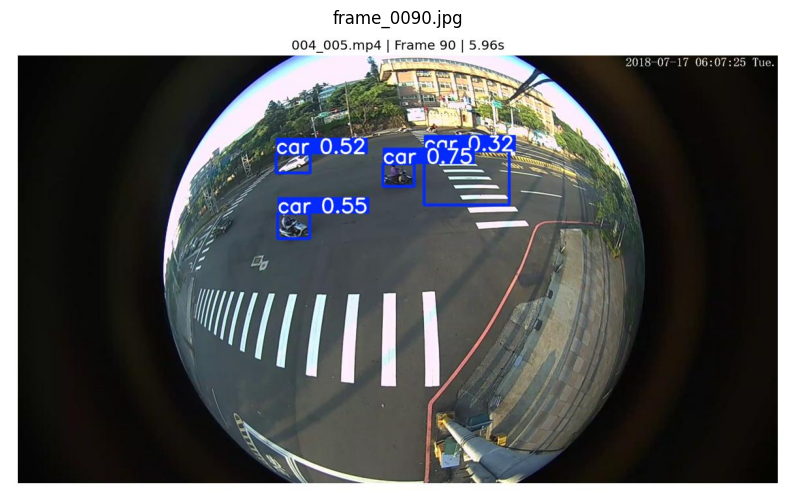

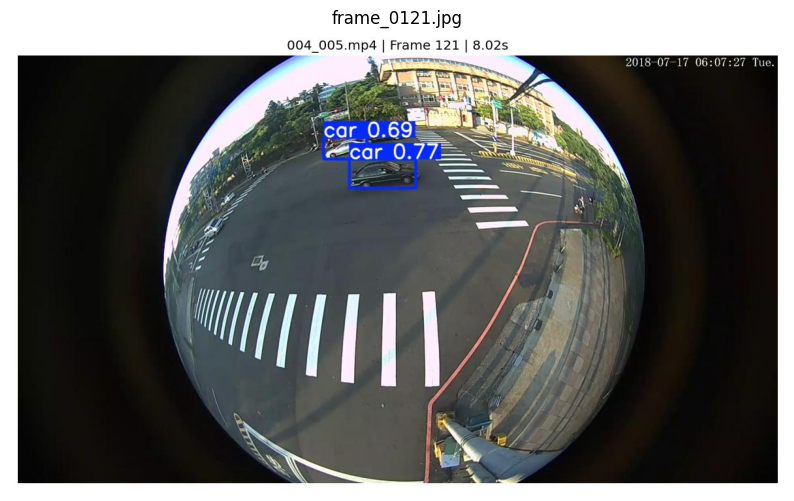

In [ ]:
#26
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

vis_dir = Path("/content/fetv_results/004_005")
images = sorted(vis_dir.glob("*.jpg"))

print(f"Found {len(images)} visualization frames.")

for img_path in images:
    img = Image.open(img_path)

    plt.figure(figsize=(10, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.title(img_path.name)
    plt.show()

In [ ]:
#27
# ============================================================
# DLR TARGET-DOMAIN ADAPTATION
# Select 20 representative frames for pseudo-label generation
# ============================================================

from pathlib import Path
import shutil
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/"
    "traffic-investigation-system"
)

FRAME_DIR = DRIVE_ROOT / "stage2" / "frames"
FRAME_INDEX = FRAME_DIR.parent / "frame_index.csv"

OUTPUT_DIR = DRIVE_ROOT / "stage2" / "target_adaptation" / "selected_frames"

# Clean previous selection if it exists
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Load Stage 1 frame index
# ------------------------------------------------------------

df = pd.read_csv(FRAME_INDEX)

print("Frame index loaded.")
print(f"Total indexed frames: {len(df)}")

# Expected columns from Stage 1:
# frame_number, timestamp_seconds

print("\nColumns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. Define the frames we already know are interesting
# ------------------------------------------------------------
#
# These are the frames we visually inspected earlier:
#
# 0    = prominent vehicle / missed background vehicles
# 200  = prominent vehicle / missed background vehicles
# 400  = prominent vehicle
# 600  = prominent vehicle + background vehicle
# 800  = prominent vehicle
# 1000 = prominent vehicle
# 1200 = prominent vehicle
#
# These deliberately cover the difficult cases we already observed.

known_hard_frames = [
    0,
    200,
    400,
    600,
    800,
    1000,
    1200
]

# Keep only frames that actually exist
known_hard_frames = [
    f for f in known_hard_frames
    if f in set(df["frame_number"].astype(int))
]

# ------------------------------------------------------------
# 4. Select 13 additional frames
# ------------------------------------------------------------
#
# We distribute them across the whole video rather than
# selecting adjacent frames.
#
# This reduces temporal redundancy because neighboring CCTV
# frames are highly similar.

remaining_df = df[
    ~df["frame_number"].isin(known_hard_frames)
].copy()

# 13 evenly distributed positions through the remaining video
positions = np.linspace(
    0,
    len(remaining_df) - 1,
    13,
    dtype=int
)

additional_frames = (
    remaining_df.iloc[positions]["frame_number"]
    .astype(int)
    .tolist()
)

# ------------------------------------------------------------
# 5. Combine and sort
# ------------------------------------------------------------

selected_frames = sorted(
    set(known_hard_frames + additional_frames)
)

# Safety check
assert len(selected_frames) == 20, (
    f"Expected 20 frames, got {len(selected_frames)}"
)

# ------------------------------------------------------------
# 6. Copy selected images
# ------------------------------------------------------------

selected_rows = []

for frame_number in selected_frames:

    row = df[
        df["frame_number"] == frame_number
    ].iloc[0]

    # Stage 1 naming convention
    source_path = FRAME_DIR / f"frame_{frame_number:06d}.jpg"

    if not source_path.exists():
        raise FileNotFoundError(
            f"Missing frame: {source_path}"
        )

    # Preserve original frame number in filename
    destination_path = (
        OUTPUT_DIR /
        f"frame_{frame_number:06d}.jpg"
    )

    shutil.copy2(
        source_path,
        destination_path
    )

    selected_rows.append({
        "frame_number": int(frame_number),
        "timestamp_seconds": float(
            row["timestamp_seconds"]
        ),
        "filename": destination_path.name
    })

# ------------------------------------------------------------
# 7. Save selection metadata
# ------------------------------------------------------------

selected_df = pd.DataFrame(selected_rows)

metadata_path = OUTPUT_DIR / "selected_frames.csv"

selected_df.to_csv(
    metadata_path,
    index=False
)

# ------------------------------------------------------------
# 8. Print result
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SELECTED DLR FRAMES")
print("=" * 70)

print(
    selected_df.to_string(index=False)
)

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(f"Selected frames : {len(selected_df)}")
print(f"Output folder   : {OUTPUT_DIR}")
print(f"Metadata        : {metadata_path}")

print("\nKnown hard-case frames:")
print(known_hard_frames)

print("\nAdditional distributed frames:")
print(additional_frames)

# ------------------------------------------------------------
# 9. Verify files
# ------------------------------------------------------------

copied_images = sorted(
    OUTPUT_DIR.glob("frame_*.jpg")
)

print(
    f"\nVerification: "
    f"{len(copied_images)}/20 images copied successfully."
)

assert len(copied_images) == 20

print("\nPASS: 20 DLR frames are ready for pseudo-label generation.")

Frame index loaded.
Total indexed frames: 301

Columns:
['frame_number', 'timestamp_seconds', 'image_path']

SELECTED DLR FRAMES
 frame_number  timestamp_seconds         filename
            0                0.0 frame_000000.jpg
            4                0.2 frame_000004.jpg
          100                5.0 frame_000100.jpg
          196                9.8 frame_000196.jpg
          200               10.0 frame_000200.jpg
          300               15.0 frame_000300.jpg
          396               19.8 frame_000396.jpg
          400               20.0 frame_000400.jpg
          500               25.0 frame_000500.jpg
          596               29.8 frame_000596.jpg
          600               30.0 frame_000600.jpg
          696               34.8 frame_000696.jpg
          796               39.8 frame_000796.jpg
          800               40.0 frame_000800.jpg
          896               44.8 frame_000896.jpg
          996               49.8 frame_000996.jpg
         1000        

In [ ]:
#28
# ============================================================
# DLR TARGET-DOMAIN ADAPTATION
# Pseudo-label candidate generation
#
# Teacher 1: DETRAC-adapted YOLO11n
# Teacher 2: COCO-pretrained YOLO11x
#
# NO TRAINING YET
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import cv2
import json
from ultralytics import YOLO

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DRIVE_ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/"
    "traffic-investigation-system"
)

FRAME_DIR = (
    DRIVE_ROOT /
    "stage2" /
    "target_adaptation" /
    "selected_frames"
)

DETRAC_MODEL_PATH = (
    DRIVE_ROOT /
    "stage2" /
    "models" /
    "yolo11n_detrac_best.pt"
)

OUTPUT_DIR = (
    DRIVE_ROOT /
    "stage2" /
    "target_adaptation" /
    "pseudo_labels"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Check inputs
# ------------------------------------------------------------

assert FRAME_DIR.exists()
assert DETRAC_MODEL_PATH.exists()

frame_paths = sorted(
    FRAME_DIR.glob("frame_*.jpg")
)

assert len(frame_paths) == 20

print("Input frames:", len(frame_paths))
print("DETRAC model:", DETRAC_MODEL_PATH)

# ------------------------------------------------------------
# 3. Load models
# ------------------------------------------------------------

print("\nLoading DETRAC-adapted model...")

detrac_model = YOLO(
    str(DETRAC_MODEL_PATH)
)

print("DETRAC classes:")
print(detrac_model.names)

# ------------------------------------------------------------
# COCO teacher
# ------------------------------------------------------------

print("\nLoading COCO YOLO11x...")

coco_model = YOLO("yolo11x.pt")

print("COCO model loaded.")

# COCO vehicle classes:
# 1 bicycle
# 2 car
# 3 motorcycle
# 5 bus
# 7 truck

COCO_VEHICLE_IDS = {
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    5: "bus",
    7: "truck"
}

# ------------------------------------------------------------
# 4. Inference configuration
# ------------------------------------------------------------

CONF = 0.20
IMGSZ = 960

print("\nInference:")
print("  confidence:", CONF)
print("  image size :", IMGSZ)

# ------------------------------------------------------------
# 5. Run both teachers
# ------------------------------------------------------------

all_candidates = []

for frame_path in frame_paths:

    frame = cv2.imread(str(frame_path))

    if frame is None:
        raise RuntimeError(
            f"Could not read {frame_path}"
        )

    frame_number = int(
        frame_path.stem.split("_")[1]
    )

    # --------------------------------------------------------
    # DETRAC teacher
    # --------------------------------------------------------

    detrac_result = detrac_model.predict(
        source=frame,
        conf=CONF,
        imgsz=IMGSZ,
        device=0,
        verbose=False
    )[0]

    if (
        detrac_result.boxes is not None
        and len(detrac_result.boxes) > 0
    ):

        boxes = (
            detrac_result.boxes.xyxy
            .cpu()
            .numpy()
        )

        classes = (
            detrac_result.boxes.cls
            .cpu()
            .numpy()
            .astype(int)
        )

        scores = (
            detrac_result.boxes.conf
            .cpu()
            .numpy()
        )

        for box, cls_id, score in zip(
            boxes, classes, scores
        ):

            all_candidates.append({
                "frame_number": frame_number,
                "source": "DETRAC",
                "class": detrac_model.names[int(cls_id)],
                "confidence": float(score),
                "x1": float(box[0]),
                "y1": float(box[1]),
                "x2": float(box[2]),
                "y2": float(box[3])
            })

    # --------------------------------------------------------
    # COCO teacher
    # --------------------------------------------------------

    coco_result = coco_model.predict(
        source=frame,
        conf=CONF,
        imgsz=IMGSZ,
        device=0,
        classes=list(COCO_VEHICLE_IDS.keys()),
        verbose=False
    )[0]

    if (
        coco_result.boxes is not None
        and len(coco_result.boxes) > 0
    ):

        boxes = (
            coco_result.boxes.xyxy
            .cpu()
            .numpy()
        )

        classes = (
            coco_result.boxes.cls
            .cpu()
            .numpy()
            .astype(int)
        )

        scores = (
            coco_result.boxes.conf
            .cpu()
            .numpy()
        )

        for box, cls_id, score in zip(
            boxes, classes, scores
        ):

            all_candidates.append({
                "frame_number": frame_number,
                "source": "COCO",
                "class": COCO_VEHICLE_IDS[int(cls_id)],
                "confidence": float(score),
                "x1": float(box[0]),
                "y1": float(box[1]),
                "x2": float(box[2]),
                "y2": float(box[3])
            })

    print(
        f"Frame {frame_number:4d}: "
        f"DETRAC={len(detrac_result.boxes) if detrac_result.boxes is not None else 0}, "
        f"COCO={len(coco_result.boxes) if coco_result.boxes is not None else 0}"
    )

# ------------------------------------------------------------
# 6. Save all raw pseudo-label candidates
# ------------------------------------------------------------

candidates_df = pd.DataFrame(all_candidates)

raw_path = OUTPUT_DIR / "all_candidates.csv"

candidates_df.to_csv(
    raw_path,
    index=False
)

# ------------------------------------------------------------
# 7. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PSEUDO-LABEL CANDIDATES")
print("=" * 70)

print(
    f"Total candidate boxes: {len(candidates_df)}"
)

if len(candidates_df) > 0:

    print("\nBy teacher:")
    print(
        candidates_df["source"]
        .value_counts()
    )

    print("\nBy class:")
    print(
        candidates_df["class"]
        .value_counts()
    )

    print("\nBy frame:")
    print(
        candidates_df
        .groupby(["frame_number", "source"])
        .size()
        .unstack(fill_value=0)
        .to_string()
    )

# ------------------------------------------------------------
# 8. Save metadata
# ------------------------------------------------------------

metadata = {
    "frames": len(frame_paths),
    "detrac_model": str(DETRAC_MODEL_PATH),
    "coco_model": "yolo11x.pt",
    "confidence": CONF,
    "imgsz": IMGSZ,
    "total_candidates": len(candidates_df)
}

with open(
    OUTPUT_DIR / "metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("\nSaved:")
print(" ", raw_path)
print(" ", OUTPUT_DIR / "metadata.json")

print("\nPASS: pseudo-label candidates generated.")

Input frames: 20
DETRAC model: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_detrac_best.pt

Loading DETRAC-adapted model...
DETRAC classes:
{0: 'car', 1: 'bus', 2: 'van', 3: 'others'}

Loading COCO YOLO11x...
COCO model loaded.

Inference:
  confidence: 0.2
  image size : 960
Frame    0: DETRAC=3, COCO=1
Frame    4: DETRAC=4, COCO=1
Frame  100: DETRAC=2, COCO=1
Frame  196: DETRAC=3, COCO=1
Frame  200: DETRAC=3, COCO=1
Frame  300: DETRAC=3, COCO=1
Frame  396: DETRAC=2, COCO=1
Frame  400: DETRAC=2, COCO=1
Frame  500: DETRAC=2, COCO=1
Frame  596: DETRAC=1, COCO=1
Frame  600: DETRAC=3, COCO=1
Frame  696: DETRAC=4, COCO=1
Frame  796: DETRAC=2, COCO=1
Frame  800: DETRAC=2, COCO=1
Frame  896: DETRAC=3, COCO=1
Frame  996: DETRAC=1, COCO=1
Frame 1000: DETRAC=1, COCO=1
Frame 1096: DETRAC=1, COCO=1
Frame 1196: DETRAC=2, COCO=1
Frame 1200: DETRAC=3, COCO=1

PSEUDO-LABEL CANDIDATES
Total candidate boxes: 67

By teacher:
source
DETRAC    47
COCO      20
Name:

In [ ]:
#29
import os
import urllib.request

url = "https://tcd.miovision.com/static/dataset/MIO-TCD-Localization.tar"
archive = "/content/MIO-TCD-Localization.tar"

print("Downloading MIO-TCD Localization...")
urllib.request.urlretrieve(url, archive)

size_gb = os.path.getsize(archive) / (1024**3)
print(f"Downloaded: {archive}")
print(f"Size: {size_gb:.2f} GB")

Downloaded: /content/MIO-TCD-Localization.tar
Size: 3.48 GB


In [ ]:
#30
import tarfile
archive = "/content/MIO-TCD-Localization.tar"
with tarfile.open(archive, "r") as tar:
    members = tar.getmembers()

print(f"Total archive entries: {len(members):,}")

for m in members[:30]:
    print(m.name)

print("\nTop-level paths:")
top = sorted(set(m.name.split("/")[0] for m in members))
for x in top:
    print(" ", x)

Total archive entries: 137,750
MIO-TCD-Localization/train/00093389.jpg
MIO-TCD-Localization/train/00055961.jpg
MIO-TCD-Localization/train/00087873.jpg
MIO-TCD-Localization/test/00131442.jpg
MIO-TCD-Localization/train/00006569.jpg
MIO-TCD-Localization/train/00030768.jpg
MIO-TCD-Localization/test/00119863.jpg
MIO-TCD-Localization/train/00021031.jpg
MIO-TCD-Localization/train/00090809.jpg
MIO-TCD-Localization/train/00101156.jpg
MIO-TCD-Localization/train/00071079.jpg
MIO-TCD-Localization/train/00033651.jpg
MIO-TCD-Localization/train/00065563.jpg
MIO-TCD-Localization/train/00097475.jpg
MIO-TCD-Localization/train/00022234.jpg
MIO-TCD-Localization/train/00054146.jpg
MIO-TCD-Localization/test/00121752.jpg
MIO-TCD-Localization/train/00002942.jpg
MIO-TCD-Localization/train/00034854.jpg
MIO-TCD-Localization/train/00066766.jpg
MIO-TCD-Localization/test/00118048.jpg
MIO-TCD-Localization/train/00098678.jpg
MIO-TCD-Localization/train/00043253.jpg
MIO-TCD-Localization/train/00075165.jpg
MIO-TCD-Local

In [ ]:
#31
import tarfile
import os

archive = "/content/MIO-TCD-Localization.tar"
extract_dir = "/content/mio_tcd"

os.makedirs(extract_dir, exist_ok=True)

with tarfile.open(archive, "r") as tar:
    tar.extractall(extract_dir)

print("Extraction complete.")
print(os.listdir(extract_dir))

/tmp/ipykernel_756/949692917.py:10: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extract_dir)


Extraction complete.
['MIO-TCD-Localization']


In [ ]:
#32
from pathlib import Path

root = Path("/content/mio_tcd")

print("Directories:")
for p in sorted(root.iterdir()):
    print(" ", p)

print("\nJPG counts:")

for folder in root.rglob("*"):
    if folder.is_dir():
        count = len(list(folder.glob("*.jpg")))
        if count:
            print(f"{folder}: {count:,}")

Directories:
  /content/mio_tcd/MIO-TCD-Localization

JPG counts:
/content/mio_tcd/MIO-TCD-Localization/test: 27,743
/content/mio_tcd/MIO-TCD-Localization/train: 110,000


In [ ]:
#33
print("\nCSV files:")

for p in root.rglob("*.csv"):
    print(p)


CSV files:
/content/mio_tcd/MIO-TCD-Localization/your_result_train.csv
/content/mio_tcd/MIO-TCD-Localization/gt_train.csv
/content/mio_tcd/MIO-TCD-Localization/your_result_test.csv


In [ ]:
#34
# ============================================================
# MIO-TCD → YOLO conversion
# 5 vehicle classes:
#   0 = car
#   1 = van
#   2 = truck
#   3 = motorcycle
#   4 = bicycle
#
# First-pass subset:
#   25,000 train images
#    3,000 validation images
# ============================================================

import pandas as pd
import shutil
import random
from pathlib import Path
from collections import Counter

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

ROOT = Path("/content/mio_tcd/MIO-TCD-Localization")
CSV_PATH = ROOT / "gt_train.csv"

OUT = Path("/content/mio_tcd/yolo_dataset")

TRAIN_IMG_OUT = OUT / "images" / "train"
VAL_IMG_OUT   = OUT / "images" / "val"

TRAIN_LBL_OUT = OUT / "labels" / "train"
VAL_LBL_OUT   = OUT / "labels" / "val"

for path in [
    TRAIN_IMG_OUT,
    VAL_IMG_OUT,
    TRAIN_LBL_OUT,
    VAL_LBL_OUT
]:
    path.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Read annotations
# ------------------------------------------------------------

df = pd.read_csv(
    CSV_PATH,
    header=None,
    names=["image_id", "label", "x1", "y1", "x2", "y2"]
)

print("Total annotation rows:", len(df))
print("Total annotated images:", df["image_id"].nunique())

# ------------------------------------------------------------
# 3. Class mapping
# ------------------------------------------------------------

CLASS_MAP = {
    "car": 0,
    "work_van": 1,
    "single_unit_truck": 2,
    "articulated_truck": 2,
    "pickup_truck": 2,
    "motorcycle": 3,
    "bicycle": 4,
}

CLASS_NAMES = {
    0: "car",
    1: "van",
    2: "truck",
    3: "motorcycle",
    4: "bicycle",
}

KEEP_LABELS = set(CLASS_MAP.keys())

print("\n=== CLASS MAPPING ===")
for k, v in CLASS_MAP.items():
    print(f"{k:25s} -> {v} ({CLASS_NAMES[v]})")

# ------------------------------------------------------------
# 4. Keep only relevant vehicle classes
# ------------------------------------------------------------

df = df[df["label"].isin(KEEP_LABELS)].copy()

print("\n=== FILTERED ANNOTATIONS ===")
print("Remaining boxes:", len(df))
print("Remaining images:", df["image_id"].nunique())

print("\nBoxes by final class:")
print(
    df["label"]
    .map(CLASS_MAP)
    .map(CLASS_NAMES)
    .value_counts()
)

# ------------------------------------------------------------
# 5. Deterministic train/validation image split
# ------------------------------------------------------------

all_ids = sorted(df["image_id"].unique().tolist())

rng = random.Random(42)
rng.shuffle(all_ids)

TRAIN_COUNT = 25_000
VAL_COUNT = 3_000

if len(all_ids) < TRAIN_COUNT + VAL_COUNT:
    raise RuntimeError(
        f"Not enough usable images. Found {len(all_ids)}."
    )

train_ids = set(all_ids[:TRAIN_COUNT])
val_ids = set(all_ids[TRAIN_COUNT:TRAIN_COUNT + VAL_COUNT])

print("\n=== SPLIT ===")
print("Train images:", len(train_ids))
print("Val images:", len(val_ids))

# ------------------------------------------------------------
# 6. Group annotations by image
# ------------------------------------------------------------

grouped = df.groupby("image_id")

# ------------------------------------------------------------
# 7. Conversion function
# ------------------------------------------------------------

def convert_image(image_id, output_image_dir, output_label_dir):
    image_id = int(image_id)

    src_image = ROOT / "train" / f"{image_id:08d}.jpg"
    dst_image = output_image_dir / f"{image_id:08d}.jpg"
    dst_label = output_label_dir / f"{image_id:08d}.txt"

    if not src_image.exists():
        raise FileNotFoundError(src_image)

    # Read image dimensions
    from PIL import Image

    with Image.open(src_image) as img:
        width, height = img.size

    rows = grouped.get_group(image_id)

    yolo_lines = []

    for _, row in rows.iterrows():

        x1 = float(row["x1"])
        y1 = float(row["y1"])
        x2 = float(row["x2"])
        y2 = float(row["y2"])

        class_id = CLASS_MAP[row["label"]]

        # Convert absolute corners → YOLO normalized format
        box_width = x2 - x1
        box_height = y2 - y1

        center_x = (x1 + x2) / 2
        center_y = (y1 + y2) / 2

        # Normalize
        center_x /= width
        center_y /= height
        box_width /= width
        box_height /= height

        yolo_lines.append(
            f"{class_id} "
            f"{center_x:.6f} "
            f"{center_y:.6f} "
            f"{box_width:.6f} "
            f"{box_height:.6f}"
        )

    # Copy image
    shutil.copy2(src_image, dst_image)

    # Write labels
    with open(dst_label, "w") as f:
        f.write("\n".join(yolo_lines))

# ------------------------------------------------------------
# 8. Convert training images
# ------------------------------------------------------------

print("\n=== CONVERTING TRAINING SET ===")

for i, image_id in enumerate(sorted(train_ids), 1):

    convert_image(
        image_id,
        TRAIN_IMG_OUT,
        TRAIN_LBL_OUT
    )

    if i % 1000 == 0 or i == len(train_ids):
        print(f"Train: {i:,}/{len(train_ids):,}")

# ------------------------------------------------------------
# 9. Convert validation images
# ------------------------------------------------------------

print("\n=== CONVERTING VALIDATION SET ===")

for i, image_id in enumerate(sorted(val_ids), 1):

    convert_image(
        image_id,
        VAL_IMG_OUT,
        VAL_LBL_OUT
    )

    if i % 500 == 0 or i == len(val_ids):
        print(f"Val: {i:,}/{len(val_ids):,}")

# ------------------------------------------------------------
# 10. Write YOLO dataset YAML
# ------------------------------------------------------------

yaml_text = f"""path: {OUT}
train: images/train
val: images/val

nc: 5

names:
  0: car
  1: van
  2: truck
  3: motorcycle
  4: bicycle
"""

yaml_path = OUT / "mio_tcd.yaml"

with open(yaml_path, "w") as f:
    f.write(yaml_text)

print("\n=== YAML ===")
print(yaml_path)
print(yaml_text)

# ------------------------------------------------------------
# 11. Final counts
# ------------------------------------------------------------

train_images = len(list(TRAIN_IMG_OUT.glob("*.jpg")))
val_images = len(list(VAL_IMG_OUT.glob("*.jpg")))

train_labels = len(list(TRAIN_LBL_OUT.glob("*.txt")))
val_labels = len(list(VAL_LBL_OUT.glob("*.txt")))

print("=== FINAL DATASET ===")
print("Train images :", train_images)
print("Train labels :", train_labels)
print("Val images   :", val_images)
print("Val labels   :", val_labels)

print("\nDataset location:")
print(OUT)

Total annotation rows: 351549
Total annotated images: 110000

=== CLASS MAPPING ===
car                       -> 0 (car)
work_van                  -> 1 (van)
single_unit_truck         -> 2 (truck)
articulated_truck         -> 2 (truck)
pickup_truck              -> 2 (truck)
motorcycle                -> 3 (motorcycle)
bicycle                   -> 4 (bicycle)

=== FILTERED ANNOTATIONS ===
Remaining boxes: 305628
Remaining images: 105762

Boxes by final class:
label
car           233497
truck          59325
van             8709
bicycle         2260
motorcycle      1837
Name: count, dtype: int64

=== SPLIT ===
Train images: 25000
Val images: 3000

=== CONVERTING TRAINING SET ===
Train: 1,000/25,000
Train: 2,000/25,000
Train: 3,000/25,000
Train: 4,000/25,000
Train: 5,000/25,000
Train: 6,000/25,000
Train: 7,000/25,000
Train: 8,000/25,000
Train: 9,000/25,000
Train: 10,000/25,000
Train: 11,000/25,000
Train: 12,000/25,000
Train: 13,000/25,000
Train: 14,000/25,000
Train: 15,000/25,000
Train: 16,

Image: /content/mio_tcd/yolo_dataset/images/train/00084075.jpg
Label: /content/mio_tcd/yolo_dataset/labels/train/00084075.txt
Image size: (720, 480)
Number of boxes: 2

Displaying annotated image:


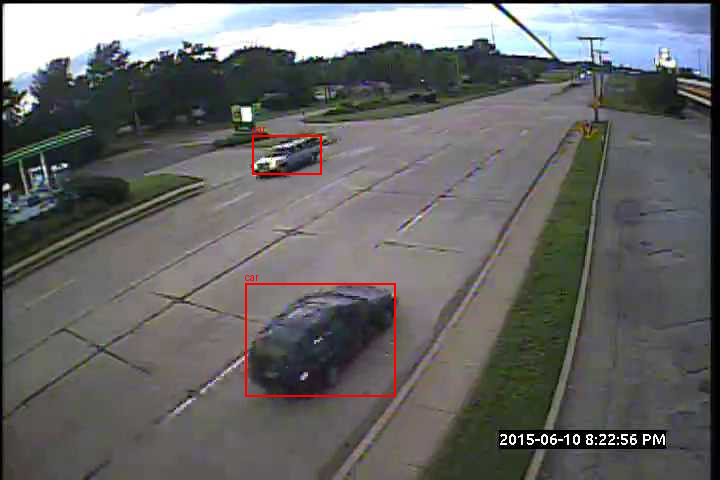

In [ ]:
#35
from pathlib import Path
from PIL import Image, ImageDraw
import random

dataset = Path("/content/mio_tcd/yolo_dataset")

# Pick one training image that has at least one label
image_path = random.choice(list((dataset / "images/train").glob("*.jpg")))
label_path = dataset / "labels/train" / f"{image_path.stem}.txt"

print("Image:", image_path)
print("Label:", label_path)

# Load image
img = Image.open(image_path).convert("RGB")
draw = ImageDraw.Draw(img)

width, height = img.size

# Read YOLO labels
with open(label_path) as f:
    lines = [line.strip() for line in f if line.strip()]

print("Image size:", img.size)
print("Number of boxes:", len(lines))

class_names = {
    0: "car",
    1: "van",
    2: "truck",
    3: "motorcycle",
    4: "bicycle",
}

for line in lines:
    cls, cx, cy, bw, bh = map(float, line.split())

    cls = int(cls)

    # YOLO normalized → pixel coordinates
    cx *= width
    cy *= height
    bw *= width
    bh *= height

    x1 = int(cx - bw / 2)
    y1 = int(cy - bh / 2)
    x2 = int(cx + bw / 2)
    y2 = int(cy + bh / 2)

    draw.rectangle([x1, y1, x2, y2], outline="red", width=2)
    draw.text(
        (x1, max(0, y1 - 12)),
        class_names[cls],
        fill="red"
    )

print("\nDisplaying annotated image:")
display(img)

In [ ]:
#36
from ultralytics import YOLO
from pathlib import Path

DATA = "/content/mio_tcd/yolo_dataset/mio_tcd.yaml"
RUN_DIR = "/content/mio_tcd/runs"

model = YOLO("yolo11n.pt")

results = model.train(
    data=DATA,
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    seed=42,
    patience=8,
    cache=False,
    pretrained=True,
    plots=True,
    project=RUN_DIR,
    name="yolo11n_miotcd_baseline",
)

print("\nTraining complete.")
print("Best model:")
print(Path(RUN_DIR) / "yolo11n_miotcd_baseline" / "weights" / "best.pt")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/mio_tcd/yolo_dataset/mio_tcd.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_miotcd_baseline, nbs=64, nms=None, ops

KeyboardInterrupt: 

In [ ]:
#37
from pathlib import Path
import shutil

src = Path("/content/mio_tcd/runs/yolo11n_miotcd_baseline/weights")

drive_out = Path(
    "/content/drive/MyDrive/"
    "DAA_Project/traffic-investigation-system/stage2/models/"
)

drive_out.mkdir(parents=True, exist_ok=True)

for filename in ["best.pt", "last.pt"]:
    source = src / filename

    if source.exists():
        destination = drive_out / f"yolo11n_miotcd_{filename}"
        shutil.copy2(source, destination)

        print(f"Saved: {destination}")
        print(f"Size: {destination.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"NOT FOUND: {source}")

Saved: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_miotcd_best.pt
Size: 15.18 MB
Saved: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_miotcd_last.pt
Size: 15.18 MB


In [ ]:
#38
from pathlib import Path

drive_out = Path(
    "/content/drive/MyDrive/"
    "DAA_Project/traffic-investigation-system/stage2/models/"
)

for p in drive_out.glob("yolo11n_miotcd_*.pt"):
    print(p.name, f"{p.stat().st_size / (1024**2):.2f} MB")

yolo11n_miotcd_best.pt 15.18 MB
yolo11n_miotcd_last.pt 15.18 MB


In [ ]:
#39
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# --------------------------------------------------
# Paths
# --------------------------------------------------
MODEL = "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_miotcd_best.pt"

FRAMES_DIR = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/target_adaptation/selected_frames"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/target_adaptation/miotcd_test"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# Load model
# --------------------------------------------------
model = YOLO(MODEL)

print("Model loaded:", MODEL)
print("Classes:", model.names)

# --------------------------------------------------
# Get selected DLR frames
# --------------------------------------------------
frame_files = sorted(FRAMES_DIR.glob("*.jpg"))

print(f"\nDLR frames found: {len(frame_files)}")

if len(frame_files) == 0:
    raise FileNotFoundError(f"No JPG frames found in {FRAMES_DIR}")

# --------------------------------------------------
# Run inference
# --------------------------------------------------
results = model.predict(
    source=[str(f) for f in frame_files],
    conf=0.25,
    imgsz=640,
    device=0,
    save=False,
    verbose=False
)

# --------------------------------------------------
# Collect detections
# --------------------------------------------------
rows = []

for frame_path, result in zip(frame_files, results):

    # Extract frame number from filename
    # e.g. frame_000000.jpg -> 0
    frame_number = int(frame_path.stem.split("_")[-1])

    # Read timestamp from Stage 1 frame index
    # We will load it below
    for box in result.boxes:
        cls_id = int(box.cls[0])
        conf = float(box.conf[0])
        x1, y1, x2, y2 = box.xyxy[0].tolist()

        rows.append({
            "frame_number": frame_number,
            "class": model.names[cls_id],
            "confidence": conf,
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

# --------------------------------------------------
# Load Stage 1 timestamps
# --------------------------------------------------
INDEX = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/frame_index.csv"
)

# The selected-frame directory has its own CSV containing
# the original frame/timestamp mapping, so use it if present.
SELECTED_INDEX = FRAMES_DIR.parent / "selected_frames.csv"

if SELECTED_INDEX.exists():
    index_df = pd.read_csv(SELECTED_INDEX)
    print("\nUsing selected_frames.csv for timestamps.")
else:
    index_df = pd.read_csv(INDEX)
    print("\nUsing Stage 1 frame_index.csv for timestamps.")

# Normalize possible column names
print("Index columns:", list(index_df.columns))

# --------------------------------------------------
# Merge timestamps
# --------------------------------------------------
df = pd.DataFrame(rows)

if len(df) > 0:
    # Detect the timestamp column
    timestamp_col = None
    for col in ["timestamp_seconds", "timestamp", "time_seconds"]:
        if col in index_df.columns:
            timestamp_col = col
            break

    if timestamp_col is None:
        raise ValueError(
            f"Could not find timestamp column in index CSV. "
            f"Columns: {list(index_df.columns)}"
        )

    timestamp_map = dict(
        zip(index_df["frame_number"], index_df[timestamp_col])
    )

    df["timestamp_seconds"] = df["frame_number"].map(timestamp_map)

    # Put timestamp second
    df = df[
        [
            "frame_number",
            "timestamp_seconds",
            "class",
            "confidence",
            "x1",
            "y1",
            "x2",
            "y2"
        ]
    ]

else:
    df = pd.DataFrame(
        columns=[
            "frame_number",
            "timestamp_seconds",
            "class",
            "confidence",
            "x1",
            "y1",
            "x2",
            "y2"
        ]
    )

# --------------------------------------------------
# Save raw detection results
# --------------------------------------------------
csv_path = OUTPUT_DIR / "miotcd_dlr_test_detections.csv"
df.to_csv(csv_path, index=False)

print(f"\nSaved detections: {csv_path}")

# --------------------------------------------------
# Summary
# --------------------------------------------------
print("\n========== SUMMARY ==========")
print(f"Input frames: {len(frame_files)}")
print(f"Total detections: {len(df)}")

if len(df) > 0:
    print(f"Frames with detections: {df['frame_number'].nunique()}/{len(frame_files)}")
    print(f"Mean detections/frame: {len(df) / len(frame_files):.2f}")
    print(f"Mean confidence: {df['confidence'].mean():.3f}")
    print(f"Median confidence: {df['confidence'].median():.3f}")
    print("\nClass counts:")
    print(df["class"].value_counts())

    print("\nDetections per frame:")
    print(
        df.groupby("frame_number")
          .size()
          .reindex(
              [int(f.stem.split("_")[-1]) for f in frame_files],
              fill_value=0
          )
    )
else:
    print("NO DETECTIONS.")

# --------------------------------------------------
# Create visualizations
# --------------------------------------------------
VIS_DIR = OUTPUT_DIR / "visualizations"
VIS_DIR.mkdir(exist_ok=True)

for frame_path, result in zip(frame_files, results):

    frame_number = int(frame_path.stem.split("_")[-1])

    plotted = result.plot()

    # Ultralytics returns BGR
    plotted_rgb = cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB)

    out_path = VIS_DIR / frame_path.name
    cv2.imwrite(
        str(out_path),
        cv2.cvtColor(plotted_rgb, cv2.COLOR_RGB2BGR)
    )

print(f"\nVisualizations saved to: {VIS_DIR}")
print("Done.")

Model loaded: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_miotcd_best.pt
Classes: {0: 'car', 1: 'van', 2: 'truck', 3: 'motorcycle', 4: 'bicycle'}

DLR frames found: 20

Using Stage 1 frame_index.csv for timestamps.
Index columns: ['frame_number', 'timestamp_seconds', 'image_path']

Saved detections: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/target_adaptation/miotcd_test/miotcd_dlr_test_detections.csv

========== SUMMARY ==========
Input frames: 20
Total detections: 23
Frames with detections: 18/20
Mean detections/frame: 1.15
Mean confidence: 0.470
Median confidence: 0.509

Class counts:
class
truck    18
van       4
car       1
Name: count, dtype: int64

Detections per frame:
frame_number
0       2
4       0
100     0
196     2
200     2
300     1
396     2
400     1
500     1
596     1
600     1
696     1
796     1
800     1
896     2
996     1
1000    1
1096    1
1196    1
1200    1
dtype: int64

Visualizations sa

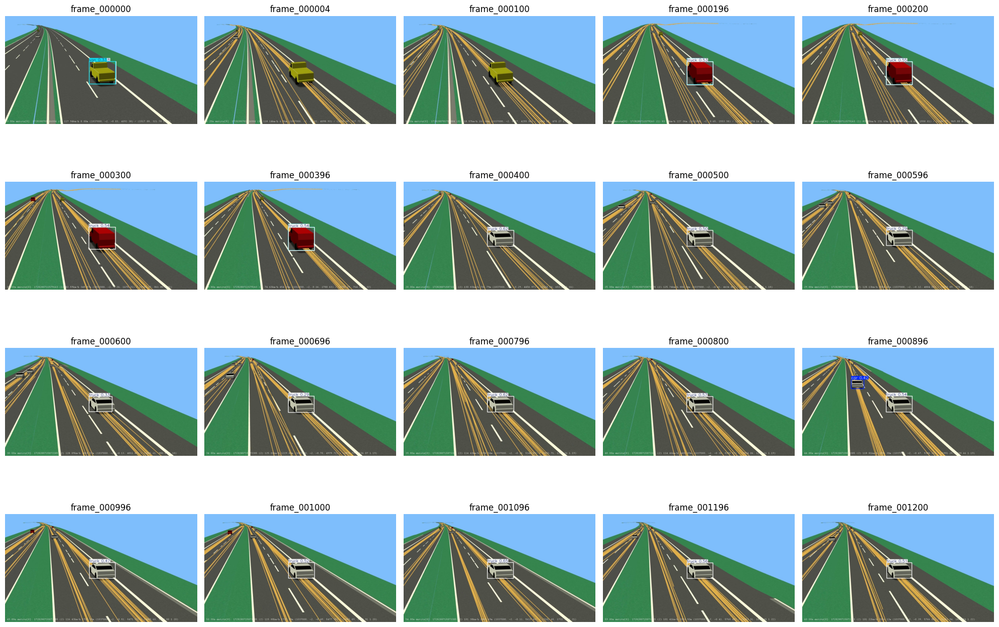

In [ ]:
#40
import matplotlib.pyplot as plt
from pathlib import Path
import math

VIS_DIR = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/target_adaptation/miotcd_test/visualizations"
)

files = sorted(VIS_DIR.glob("*.jpg"))

fig, axes = plt.subplots(4, 5, figsize=(20, 14))
axes = axes.ravel()

for ax, path in zip(axes, files):
    img = plt.imread(path)
    ax.imshow(img)
    ax.set_title(path.stem)
    ax.axis("off")

for ax in axes[len(files):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [1]:
#40.b
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
#40c
from pathlib import Path
import shutil

FETV_DIR = Path("/content/FETV_public_clips")
FETV_DIR.mkdir(exist_ok=True)

for name in ["001_020.mp4", "004_005.mp4", "006_020.mp4"]:
    src = Path("/content") / name
    dst = FETV_DIR / name

    if src.exists():
        shutil.move(str(src), str(dst))
        print(f"Moved: {dst}")
    else:
        print(f"NOT FOUND: {src}")

In [ ]:
#41
from pathlib import Path
from ultralytics import YOLO
import cv2
import pandas as pd

# ============================================================
# PATHS
# ============================================================

MODEL = "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_miotcd_best.pt"

# CHANGE THIS if your FETV clips are stored somewhere else
FETV_DIR = Path("/content/FETV_public_clips")

VIDEOS = [
    FETV_DIR / "001_020.mp4",
    FETV_DIR / "004_005.mp4",
    FETV_DIR / "006_020.mp4",
]

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/target_adaptation/miotcd_fetv_test"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOAD MODEL
# ============================================================

model = YOLO(MODEL)

print("Model loaded:", MODEL)
print("Classes:", model.names)

# ============================================================
# CHECK VIDEOS
# ============================================================

for video in VIDEOS:
    if not video.exists():
        print(f"NOT FOUND: {video}")
    else:
        print(f"Found: {video}")

# ============================================================
# INFERENCE
# ============================================================

all_rows = []

for video_path in VIDEOS:

    print("\n" + "=" * 60)
    print(f"Processing: {video_path.name}")
    print("=" * 60)

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        print("ERROR: Could not open video.")
        continue

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    print(f"Frames: {total_frames}")
    print(f"FPS: {fps:.2f}")

    video_rows = []

    frame_number = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        # Run MIO-TCD detector
        result = model.predict(
            source=frame,
            conf=0.25,
            imgsz=640,
            device=0,
            verbose=False
        )[0]

        for box in result.boxes:

            cls_id = int(box.cls[0])
            confidence = float(box.conf[0])

            x1, y1, x2, y2 = box.xyxy[0].tolist()

            video_rows.append({
                "video": video_path.name,
                "frame_number": frame_number,
                "timestamp_seconds": frame_number / fps,
                "class": model.names[cls_id],
                "confidence": confidence,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2
            })

        frame_number += 1

    cap.release()

    # --------------------------------------------------------
    # Save video detections
    # --------------------------------------------------------

    video_df = pd.DataFrame(video_rows)

    csv_path = OUTPUT_DIR / f"{video_path.stem}_detections.csv"
    video_df.to_csv(csv_path, index=False)

    all_rows.extend(video_rows)

    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------

    print("\nSUMMARY")

    print(f"Total detections: {len(video_df)}")

    if len(video_df) > 0:

        frames_with_detections = video_df["frame_number"].nunique()

        print(
            f"Frames with detections: "
            f"{frames_with_detections}/{total_frames}"
        )

        print(
            f"Mean detections/frame: "
            f"{len(video_df) / total_frames:.3f}"
        )

        print(
            f"Mean confidence: "
            f"{video_df['confidence'].mean():.3f}"
        )

        print("\nClass counts:")
        print(video_df["class"].value_counts())

        print("\nConfidence by class:")
        print(
            video_df.groupby("class")["confidence"]
            .agg(["count", "mean", "median"])
            .round(3)
        )

    else:
        print("NO DETECTIONS")

# ============================================================
# COMBINED RESULTS
# ============================================================

all_df = pd.DataFrame(all_rows)

combined_path = OUTPUT_DIR / "miotcd_fetv_all_detections.csv"
all_df.to_csv(combined_path, index=False)

print("\n" + "=" * 60)
print("COMBINED RESULTS")
print("=" * 60)

print(f"Total detections: {len(all_df)}")

if len(all_df) > 0:

    print("\nDetections by video:")
    print(
        all_df.groupby("video").size()
    )

    print("\nClasses:")
    print(
        all_df["class"].value_counts()
    )

    print("\nMean confidence:")
    print(
        all_df["confidence"].mean()
    )

print(f"\nSaved combined CSV:")
print(combined_path)

Model loaded: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/models/yolo11n_miotcd_best.pt
Classes: {0: 'car', 1: 'van', 2: 'truck', 3: 'motorcycle', 4: 'bicycle'}
Found: /content/FETV_public_clips/001_020.mp4
Found: /content/FETV_public_clips/004_005.mp4
Found: /content/FETV_public_clips/006_020.mp4

Processing: 001_020.mp4
Frames: 116
FPS: 14.59

SUMMARY
Total detections: 418
Frames with detections: 112/116
Mean detections/frame: 3.603
Mean confidence: 0.478

Class counts:
class
motorcycle    155
car           150
bicycle       106
truck           5
van             2
Name: count, dtype: int64

Confidence by class:
            count   mean  median
class                           
bicycle       106  0.627   0.629
car           150  0.492   0.451
motorcycle    155  0.372   0.337
truck           5  0.285   0.292
van             2  0.317   0.317

Processing: 004_005.mp4
Frames: 122
FPS: 15.09

SUMMARY
Total detections: 539
Frames with detections: 122/122
Mean detec

In [ ]:
#42
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import math

# ============================================================
# PATHS
# ============================================================

FETV_DIR = Path("/content/FETV_public_clips")

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/target_adaptation/miotcd_fetv_test"
)

DET_CSV = OUTPUT_DIR / "miotcd_fetv_all_detections.csv"

VIS_DIR = OUTPUT_DIR / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# LOAD DETECTIONS
# ============================================================

df = pd.read_csv(DET_CSV)

print("Loaded detections:", len(df))

# ============================================================
# SUMMARY
# ============================================================

summary_rows = []

for video_name, group in df.groupby("video"):

    video_path = FETV_DIR / video_name

    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS)

    cap.release()

    summary_rows.append({
        "video": video_name,
        "total_frames": total_frames,
        "fps": fps,
        "total_detections": len(group),
        "frames_with_detections": group["frame_number"].nunique(),
        "frames_without_detections":
            total_frames - group["frame_number"].nunique(),
        "mean_detections_per_frame":
            len(group) / total_frames,
        "mean_confidence":
            group["confidence"].mean(),
        "median_confidence":
            group["confidence"].median()
    })

summary_df = pd.DataFrame(summary_rows)

summary_path = OUTPUT_DIR / "miotcd_fetv_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nSUMMARY")
print(summary_df.to_string(index=False))

print(f"\nSaved summary:")
print(summary_path)

# ============================================================
# LOAD MODEL FOR VISUALIZATION
# ============================================================

from ultralytics import YOLO

MODEL = (
    "/content/drive/MyDrive/DAA_Project/"
    "traffic-investigation-system/stage2/models/"
    "yolo11n_miotcd_best.pt"
)

model = YOLO(MODEL)

# ============================================================
# SELECT REPRESENTATIVE FRAMES
# ============================================================

for video_name in ["001_020.mp4", "004_005.mp4", "006_020.mp4"]:

    video_path = FETV_DIR / video_name

    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # 5 evenly distributed frames
    selected = [
        round(i * (total_frames - 1) / 4)
        for i in range(5)
    ]

    video_vis_dir = VIS_DIR / video_path.stem
    video_vis_dir.mkdir(exist_ok=True)

    images = []

    for frame_number in selected:

        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
        ret, frame = cap.read()

        if not ret:
            continue

        result = model.predict(
            source=frame,
            conf=0.25,
            imgsz=640,
            device=0,
            verbose=False
        )[0]

        plotted = result.plot()

        plotted_rgb = cv2.cvtColor(
            plotted,
            cv2.COLOR_BGR2RGB
        )

        # Save individual visualization
        out_path = (
            video_vis_dir /
            f"frame_{frame_number:04d}.jpg"
        )

        cv2.imwrite(
            str(out_path),
            cv2.cvtColor(
                plotted_rgb,
                cv2.COLOR_RGB2BGR
            )
        )

        images.append(
            (frame_number, plotted_rgb)
        )

    cap.release()

    # --------------------------------------------------------
    # Contact sheet
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1, len(images),
        figsize=(22, 5)
    )

    if len(images) == 1:
        axes = [axes]

    for ax, (frame_number, image) in zip(axes, images):
        ax.imshow(image)
        ax.set_title(
            f"{video_name}\nframe {frame_number}"
        )
        ax.axis("off")

    plt.tight_layout()

    contact_path = (
        VIS_DIR /
        f"{video_path.stem}_contact_sheet.jpg"
    )

    plt.savefig(
        contact_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.close()

    print(f"Saved visualizations for {video_name}")

print("\nVisual evidence saved to:")
print(VIS_DIR)

Loaded detections: 1060

SUMMARY
      video  total_frames       fps  total_detections  frames_with_detections  frames_without_detections  mean_detections_per_frame  mean_confidence  median_confidence
001_020.mp4           116 14.591195               418                     112                          4                   3.603448         0.478433           0.451345
004_005.mp4           122 15.092784               539                     122                          0                   4.418033         0.494870           0.483229
006_020.mp4            48 15.483871               103                      47                          1                   2.145833         0.526989           0.495100

Saved summary:
/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/target_adaptation/miotcd_fetv_test/miotcd_fetv_summary.csv
Saved visualizations for 001_020.mp4
Saved visualizations for 004_005.mp4
Saved visualizations for 006_020.mp4

Visual evidence saved to:
/content/dr


 001_020_contact_sheet.jpg


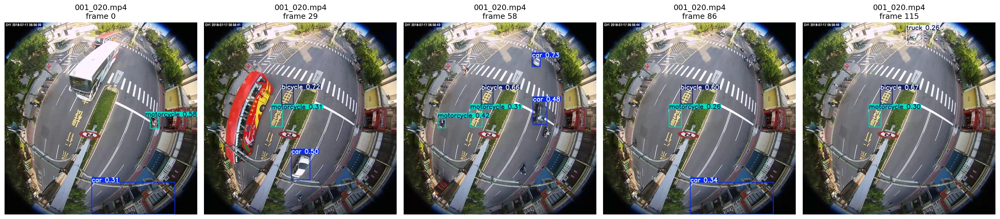


 004_005_contact_sheet.jpg


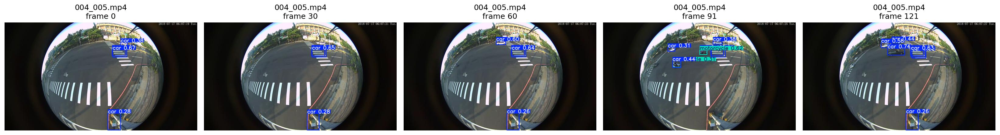


 006_020_contact_sheet.jpg


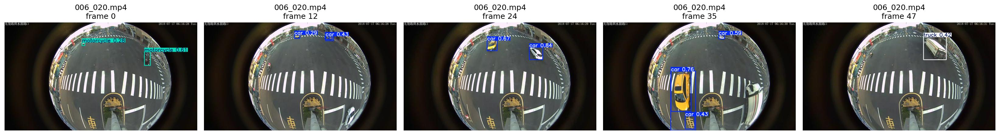

In [ ]:
#43
from pathlib import Path
from IPython.display import display, Image

VIS_DIR = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage2/target_adaptation/miotcd_fetv_test/visualizations"
)

for name in [
    "001_020_contact_sheet.jpg",
    "004_005_contact_sheet.jpg",
    "006_020_contact_sheet.jpg"
]:
    path = VIS_DIR / name

    print("\n", name)
    display(Image(filename=str(path)))

In [ ]:
#44
# ============================================================
# STAGE 3 — TASK 1
# READ-ONLY BYTETRACK COMPATIBILITY INSPECTION
# No package installation. No file modifications.
# ============================================================

import sys
import importlib.util
import importlib.metadata as metadata
import inspect
import platform

print("=" * 76)
print("A. RUNTIME")
print("=" * 76)
print("Python:", sys.version)
print("Platform:", platform.platform())

packages = [
    "numpy", "torch", "supervision", "ultralytics",
    "boxmot", "filterpy", "lap", "lapx", "opencv-python"
]

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package}: installed, version {version}")
    except metadata.PackageNotFoundError:
        print(f"{package}: not installed")
    except Exception as exc:
        print(f"{package}: version check failed: {exc!r}")

print("\n" + "=" * 76)
print("B. BYTE TRACK IMPLEMENTATIONS ALREADY AVAILABLE")
print("=" * 76)

# Inspect Supervision only if already installed.
if importlib.util.find_spec("supervision") is not None:
    try:
        import supervision as sv

        print("\n[Supervision]")
        print("Version:", getattr(sv, "__version__", "unknown"))

        for name in ["ByteTrack", "Detections"]:
            print(f"sv.{name} available:", hasattr(sv, name))

        if hasattr(sv, "ByteTrack"):
            cls = sv.ByteTrack
            try:
                print("Constructor:", inspect.signature(cls))
            except Exception as exc:
                print("Constructor signature unavailable:", repr(exc))

            for method_name in ["update_with_detections", "reset"]:
                method = getattr(cls, method_name, None)
                print(f"{method_name} available:", callable(method))
                if callable(method):
                    try:
                        print("  Signature:", inspect.signature(method))
                    except Exception:
                        pass

            # Inspect source for class handling and empty inputs.
            try:
                source = inspect.getsource(cls)
                print("\nClass-related implementation lines:")
                for line in source.splitlines():
                    if any(term in line.lower() for term in [
                        "class_id", "class_ids", "empty",
                        "tracker.update", "reset"
                    ]):
                        print(" ", line.strip()[:240])
            except Exception as exc:
                print("Class source unavailable:", repr(exc))

        if hasattr(sv, "Detections"):
            try:
                print("Detections constructor:",
                      inspect.signature(sv.Detections))
            except Exception:
                pass
            print("Detections.empty available:",
                  callable(getattr(sv.Detections, "empty", None)))

    except Exception as exc:
        print("Supervision import failed:", repr(exc))
else:
    print("\nSupervision is not installed.")

# Inspect Ultralytics native ByteTrack only if already installed.
if importlib.util.find_spec("ultralytics") is not None:
    try:
        from ultralytics.trackers.byte_tracker import BYTETracker

        print("\n[Ultralytics native ByteTrack]")
        try:
            print("Constructor:", inspect.signature(BYTETracker))
        except Exception as exc:
            print("Constructor signature unavailable:", repr(exc))

        for method_name in ["update", "reset"]:
            method = getattr(BYTETracker, method_name, None)
            print(f"{method_name} available:", callable(method))
            if callable(method):
                try:
                    print("  Signature:", inspect.signature(method))
                except Exception:
                    pass

        try:
            print("\nBYTETracker.update source:")
            print(inspect.getsource(BYTETracker.update)[:6000])
        except Exception as exc:
            print("Update source unavailable:", repr(exc))

    except Exception as exc:
        print("Ultralytics tracker import failed:", repr(exc))
else:
    print("\nUltralytics is not installed.")

print("\n" + "=" * 76)
print("C. INSTALLED PACKAGE DEPENDENCY STATUS")
print("=" * 76)

for package in ["supervision", "ultralytics", "boxmot"]:
    try:
        dist = metadata.distribution(package)
        print(f"\n{package} requirements:")
        requirements = dist.requires or []
        print("\n".join("  " + item for item in requirements[:50])
              if requirements else "  No requirements metadata found")
    except metadata.PackageNotFoundError:
        print(f"\n{package}: not installed; no dependency metadata")

print("\nInspection complete. No installation or file changes performed.")


A. RUNTIME
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
numpy: installed, version 2.1.3
torch: installed, version 2.11.0+cu130
supervision: not installed
ultralytics: not installed
boxmot: not installed
filterpy: not installed
lap: not installed
lapx: not installed
opencv-python: installed, version 5.0.0.93

B. BYTE TRACK IMPLEMENTATIONS ALREADY AVAILABLE

Supervision is not installed.

Ultralytics is not installed.

C. INSTALLED PACKAGE DEPENDENCY STATUS

supervision: not installed; no dependency metadata

ultralytics: not installed; no dependency metadata

boxmot: not installed; no dependency metadata

Inspection complete. No installation or file changes performed.


In [ ]:
#45
from google.colab import files, drive
from pathlib import Path
import shutil

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Upload the three FETV clips from your Windows computer
uploaded = files.upload()

# 3. Check that all three required clips were uploaded
required = {
    "001_020.mp4",
    "004_005.mp4",
    "006_020.mp4",
}

missing = required - set(uploaded.keys())

if missing:
    raise ValueError(
        f"Missing clips: {sorted(missing)}. "
        "Run this cell again and select all three required MP4 files."
    )

# 4. Set the destination in Google Drive
output_dir = Path(
    "/content/drive/MyDrive/DAA_Project/"
    "traffic-investigation-system/stage3/source_videos"
)
output_dir.mkdir(parents=True, exist_ok=True)

# 5. Copy and verify each uploaded file
for name in sorted(required):
    source = Path("/content") / name
    destination = output_dir / name

    shutil.copy2(source, destination)

    if (
        not destination.exists()
        or destination.stat().st_size != source.stat().st_size
    ):
        raise IOError(f"Copy verification failed: {name}")

    print(f"PASS: {name}")
    print(f"  Size: {destination.stat().st_size:,} bytes")
    print(f"  Saved to: {destination}")

print("\nAll three clips copied and size-verified.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving 006_020.mp4 to 006_020.mp4
Saving 004_005.mp4 to 004_005.mp4
Saving 001_020.mp4 to 001_020.mp4
PASS: 001_020.mp4
  Size: 6,277,394 bytes
  Saved to: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/source_videos/001_020.mp4
PASS: 004_005.mp4
  Size: 2,430,553 bytes
  Saved to: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/source_videos/004_005.mp4
PASS: 006_020.mp4
  Size: 1,162,198 bytes
  Saved to: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/source_videos/006_020.mp4

All three clips copied and size-verified.


In [ ]:
#46
import sys
import inspect
import importlib.metadata as metadata
import supervision as sv
import numpy as np

print("Python:", sys.version.split()[0])
print("Supervision:", metadata.version("supervision"))
print("NumPy:", np.__version__)
print("OpenCV:", metadata.version("opencv-python"))

print("\n=== ByteTrack API ===")
print("Class:", sv.ByteTrack)
print("Constructor:", inspect.signature(sv.ByteTrack))
print(
    "update_with_detections:",
    inspect.signature(sv.ByteTrack.update_with_detections)
)
print("reset available:", hasattr(sv.ByteTrack, "reset"))

# Smoke test: create a tracker and send an empty detection set.
tracker = sv.ByteTrack()
empty = sv.Detections.empty()
tracked = tracker.update_with_detections(empty)

print("\n=== Empty-frame smoke test ===")
print("Input detections:", len(empty))
print("Output detections:", len(tracked))
print("Tracker IDs:", tracked.tracker_id)
print("\nDependency/API inspection complete.")


Python: 3.13.15
Supervision: 0.30.9
NumPy: 2.1.3
OpenCV: 5.0.0.93

=== ByteTrack API ===
Class: <class 'supervision.tracker.byte_tracker.core.ByteTrack'>
Constructor: (track_activation_threshold: float = 0.25, lost_track_buffer: int = 30, minimum_matching_threshold: float = 0.8, frame_rate: float = 30, minimum_consecutive_frames: int = 1) -> None
update_with_detections: (self, detections: supervision.detection.core.Detections) -> supervision.detection.core.Detections
reset available: True

=== Empty-frame smoke test ===
Input detections: 0
Output detections: 0
Tracker IDs: []

Dependency/API inspection complete.


/tmp/ipykernel_6611/3274130047.py:17: FutureWarning: The `ByteTrack` was deprecated since v0.28.0. It will be removed in v0.31.0.
  inspect.signature(sv.ByteTrack.update_with_detections)


In [ ]:
#46b

from pathlib import Path
import pandas as pd
import numpy as np
import supervision as sv
from trackers import ByteTrackTracker

ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/"
    "traffic-investigation-system"
)
CSV_DIR = ROOT / "stage2" / "target_adaptation" / "miotcd_fetv_test"

clips = {
    "001_020": "001_020_detections.csv",
    "004_005": "004_005_detections.csv",
    "006_020": "006_020_detections.csv",
}

print("=" * 72)
print("1. DETECTION CONFIDENCE DISTRIBUTION")
print("=" * 72)

for clip, filename in clips.items():
    df = pd.read_csv(CSV_DIR / filename)
    print(f"\n{clip}: {len(df)} detections")

    print(
        df.groupby("class")["confidence"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            minimum="min",
            maximum="max",
        )
        .round(3)
        .to_string()
    )

    print("\nOverall confidence quantiles:")
    print(
        df["confidence"]
        .quantile([0, 0.1, 0.25, 0.5, 0.75, 0.9, 1])
        .round(3)
        .to_string()
    )

print("\n" + "=" * 72)
print("2. REAL-DETECTION API SMOKE TEST")
print("=" * 72)

# Test a short sequence from each clip using a fresh tracker per class.
# This is only a smoke test, not a tracking-quality evaluation.
for clip, filename in clips.items():
    df = pd.read_csv(CSV_DIR / filename)
    classes = sorted(df["class"].dropna().unique())

    trackers_by_class = {
        class_name: ByteTrackTracker(
            frame_rate=15.0,
            track_activation_threshold=0.25,
            minimum_consecutive_frames=1,
            minimum_iou_threshold=0.1,
            high_conf_det_threshold=0.5,
        )
        for class_name in classes
    }

    tracked_observations = 0
    frames_tested = min(10, int(df["frame_number"].max()) + 1)

    for frame_number in range(frames_tested):
        frame_df = df[df["frame_number"] == frame_number]

        for class_name in classes:
            part = frame_df[frame_df["class"] == class_name]
            tracker = trackers_by_class[class_name]

            if len(part):
                detections = sv.Detections(
                    xyxy=part[["x1", "y1", "x2", "y2"]]
                    .to_numpy(dtype=np.float32),
                    confidence=part["confidence"].to_numpy(dtype=np.float32),
                    class_id=np.zeros(len(part), dtype=int),
                )
            else:
                detections = sv.Detections.empty()

            tracked = tracker.update(detections)
            tracked_observations += len(tracked)

            if len(tracked) and tracked.tracker_id is None:
                raise RuntimeError(
                    f"{clip}, frame {frame_number}: "
                    "tracker returned detections without track IDs"
                )

    print(
        f"{clip}: tested {frames_tested} frames; "
        f"tracker-reported observations={tracked_observations}"
    )

print("\nSmoke test complete. No files were written.")


In [ ]:
#47
from pathlib import Path
from collections import defaultdict
import json
import cv2
import numpy as np
import pandas as pd
import supervision as sv
from trackers import ByteTrackTracker

# ============================================================
# 1. CONFIGURATION
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/"
    "traffic-investigation-system"
)

VIDEO_DIR = ROOT / "stage3" / "source_videos"
DETECTION_DIR = (
    ROOT / "stage2" / "target_adaptation" / "miotcd_fetv_test"
)
OUTPUT_ROOT = ROOT / "stage3" / "tracking"

CLIPS = {
    "001_020": {
        "video": VIDEO_DIR / "001_020.mp4",
        "csv": DETECTION_DIR / "001_020_detections.csv",
    },
    "004_005": {
        "video": VIDEO_DIR / "004_005.mp4",
        "csv": DETECTION_DIR / "004_005_detections.csv",
    },
    "006_020": {
        "video": VIDEO_DIR / "006_020.mp4",
        "csv": DETECTION_DIR / "006_020_detections.csv",
    },
}

TRACKER_CONFIG = {
    "tracker": "ByteTrackTracker",
    "lost_track_buffer": 30,
    "track_activation_threshold": 0.25,
    "high_conf_det_threshold": 0.35,
    "minimum_consecutive_frames": 1,
    "minimum_iou_threshold": 0.10,
    "class_aware": True,
    "class_aware_method": "independent tracker per class",
    "empty_frames_updated": True,
    "source_detections_reused": True,
}

REQUIRED_COLUMNS = [
    "frame_number", "timestamp_seconds", "class", "confidence",
    "x1", "y1", "x2", "y2",
]

# Consistent colors for the five detector classes (BGR).
CLASS_COLORS = {
    "car": (60, 200, 60),
    "van": (255, 180, 0),
    "truck": (0, 165, 255),
    "motorcycle": (255, 100, 220),
    "bicycle": (255, 220, 60),
}

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def make_tracker(fps):
    return ByteTrackTracker(
        lost_track_buffer=TRACKER_CONFIG["lost_track_buffer"],
        frame_rate=float(fps),
        track_activation_threshold=(
            TRACKER_CONFIG["track_activation_threshold"]
        ),
        minimum_consecutive_frames=(
            TRACKER_CONFIG["minimum_consecutive_frames"]
        ),
        minimum_iou_threshold=(
            TRACKER_CONFIG["minimum_iou_threshold"]
        ),
        high_conf_det_threshold=(
            TRACKER_CONFIG["high_conf_det_threshold"]
        ),
    )


def draw_detections(frame, frame_df, row_to_track):
    """Draw tracked detections and show detections without a valid ID."""
    canvas = frame.copy()

    for row_idx, row in frame_df.iterrows():
        x1, y1, x2, y2 = [
            int(round(row[c])) for c in ["x1", "y1", "x2", "y2"]
        ]

        class_name = str(row["class"])
        track_id = row_to_track.get(int(row_idx))

        if track_id is not None:
            color = CLASS_COLORS.get(class_name, (0, 255, 0))
            label = (
                f"{class_name} ID:{track_id} "
                f"{float(row['confidence']):.2f}"
            )
        else:
            color = (150, 150, 150)
            label = f"{class_name} untracked"

        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, 2)

        text_y = max(20, y1 - 7)
        cv2.putText(
            canvas,
            label,
            (x1, text_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            color,
            2,
            cv2.LINE_AA,
        )

    return canvas


def create_contact_sheet(image_paths, output_path, clip_name):
    """Create a two-column contact sheet while preserving image aspect ratios."""
    cell_w, cell_h = 640, 420
    header_h = 36
    columns = 2
    rows = (len(image_paths) + columns - 1) // columns

    sheet = np.full(
        (rows * (cell_h + header_h), columns * cell_w, 3),
        245,
        dtype=np.uint8,
    )

    for i, path in enumerate(image_paths):
        image = cv2.imread(str(path))
        if image is None:
            raise IOError(f"Could not read visualization: {path}")

        h, w = image.shape[:2]
        scale = min(cell_w / w, cell_h / h)
        new_w = max(1, int(w * scale))
        new_h = max(1, int(h * scale))
        resized = cv2.resize(image, (new_w, new_h))

        col = i % columns
        row = i // columns
        x0 = col * cell_w
        y0 = row * (cell_h + header_h)

        cv2.putText(
            sheet,
            f"{clip_name} | {path.stem}",
            (x0 + 10, y0 + 25),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (20, 20, 20),
            2,
            cv2.LINE_AA,
        )

        paste_x = x0 + (cell_w - new_w) // 2
        paste_y = y0 + header_h + (cell_h - new_h) // 2
        sheet[
            paste_y:paste_y + new_h,
            paste_x:paste_x + new_w,
        ] = resized

    if not cv2.imwrite(str(output_path), sheet):
        raise IOError(f"Failed to write contact sheet: {output_path}")


# ============================================================
# 3. PROCESS ONE VIDEO
# ============================================================

def process_clip(clip_name, video_path, csv_path):
    print("\n" + "=" * 76)
    print(f"STAGE 3 TRACKING: {clip_name}")
    print("=" * 76)

    if not video_path.is_file():
        raise FileNotFoundError(f"Video not found: {video_path}")
    if not csv_path.is_file():
        raise FileNotFoundError(f"Detection CSV not found: {csv_path}")

    df = pd.read_csv(csv_path)

    missing = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
    if missing:
        raise ValueError(f"{clip_name}: CSV is missing columns {missing}")

    # Use a stable integer row index to map tracker outputs back to the
    # original detector observations, even if tracker output order changes.
    df = df.reset_index(drop=True).copy()

    numeric_columns = [
        "frame_number", "timestamp_seconds", "confidence",
        "x1", "y1", "x2", "y2",
    ]
    for col in numeric_columns:
        df[col] = pd.to_numeric(df[col], errors="raise")

    if df[numeric_columns].isna().any().any():
        raise ValueError(f"{clip_name}: missing numeric CSV values.")

    if not np.allclose(df["frame_number"], np.round(df["frame_number"])):
        raise ValueError(f"{clip_name}: non-integer frame numbers.")

    df["frame_number"] = df["frame_number"].astype(int)

    if df["class"].isna().any():
        raise ValueError(f"{clip_name}: missing class labels.")

    if not df["confidence"].between(0, 1).all():
        raise ValueError(f"{clip_name}: confidence outside [0, 1].")

    if not (
        (df["x2"] > df["x1"]) & (df["y2"] > df["y1"])
    ).all():
        raise ValueError(f"{clip_name}: invalid bounding boxes.")

    classes = sorted(df["class"].astype(str).unique().tolist())
    if not classes:
        raise ValueError(f"{clip_name}: no detection classes in CSV.")

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise IOError(f"{clip_name}: could not open source video.")

    fps = float(cap.get(cv2.CAP_PROP_FPS))
    reported_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    if fps <= 0 or reported_frames <= 0:
        cap.release()
        raise ValueError(f"{clip_name}: invalid video FPS/frame count.")

    if df["frame_number"].min() < 0 or (
        df["frame_number"].max() >= reported_frames
    ):
        cap.release()
        raise ValueError(f"{clip_name}: CSV frame indices exceed video.")

    boxes_in_bounds = (
        (df["x1"] >= 0)
        & (df["y1"] >= 0)
        & (df["x2"] <= width)
        & (df["y2"] <= height)
    )
    if not boxes_in_bounds.all():
        cap.release()
        raise ValueError(
            f"{clip_name}: {int((~boxes_in_bounds).sum())} boxes "
            "exceed video dimensions."
        )

    # Check timestamps are consistent with source frame number / FPS.
    expected_times = df["frame_number"].to_numpy() / fps
    max_timestamp_error = float(
        np.abs(df["timestamp_seconds"].to_numpy() - expected_times).max()
    )
    if max_timestamp_error > 0.05:
        cap.release()
        raise ValueError(
            f"{clip_name}: timestamp deviation "
            f"{max_timestamp_error:.4f}s exceeds 0.05s."
        )

    # One independent tracker per class. This prevents a car detection,
    # for example, from being associated with a motorcycle track.
    trackers = {class_name: make_tracker(fps) for class_name in classes}

    # Local tracker IDs can overlap between class-specific trackers.
    # Convert each (class, local ID) pair to a unique ID within this video.
    global_id_map = {}
    next_global_id = 1

    # Group detections by source frame for efficient frame-by-frame updates.
    rows_by_frame = {
        int(frame_number): group
        for frame_number, group in df.groupby("frame_number", sort=False)
    }

    total_frames = 0
    tracked_rows = []
    untracked_detection_count = 0
    selected_frame_ids = sorted(
        set(np.linspace(
            0, reported_frames - 1,
            num=min(6, reported_frames),
            dtype=int,
        ).tolist())
    )

    visualization_dir = (
        OUTPUT_ROOT / clip_name / "visualizations"
    )
    selected_dir = visualization_dir / "selected_annotated_frames"
    selected_dir.mkdir(parents=True, exist_ok=True)

    selected_image_paths = []

    try:
        for frame_number in range(reported_frames):
            ok, frame = cap.read()
            if not ok:
                raise IOError(
                    f"{clip_name}: decoding stopped at frame {frame_number}."
                )

            total_frames += 1
            frame_df = rows_by_frame.get(frame_number)

            if frame_df is None:
                frame_df = df.iloc[0:0]

            row_to_track = {}

            # Update every class tracker on every source frame, including
            # frames where that class has no detections.
            timestamp = frame_number / fps

            for class_name in classes:
                if len(frame_df):
                    class_df = frame_df[
                        frame_df["class"].astype(str) == class_name
                    ]
                else:
                    class_df = frame_df

                if len(class_df):
                    source_indices = class_df.index.to_numpy(dtype=np.int64)

                    detections = sv.Detections(
                        xyxy=class_df[
                            ["x1", "y1", "x2", "y2"]
                        ].to_numpy(dtype=np.float32),
                        confidence=class_df["confidence"].to_numpy(
                            dtype=np.float32
                        ),
                        # Each tracker receives a single class by design.
                        class_id=np.zeros(len(class_df), dtype=int),
                        data={"source_row_idx": source_indices},
                    )
                else:
                    detections = sv.Detections.empty()

                result = trackers[class_name].update(
                    detections,
                    timestamp=timestamp,
                )

                if len(result) == 0:
                    continue

                if result.tracker_id is None:
                    raise RuntimeError(
                        f"{clip_name}: tracker returned detections "
                        "without tracker IDs."
                    )

                if (
                    result.data is None
                    or "source_row_idx" not in result.data
                ):
                    raise RuntimeError(
                        f"{clip_name}: tracker did not preserve source-row "
                        "metadata; refusing to guess detection correspondence."
                    )

                source_indices_out = result.data["source_row_idx"]

                for source_idx, local_id in zip(
                    source_indices_out, result.tracker_id
                ):
                    local_id = int(local_id)

                    # -1 denotes a detection not assigned a confirmed track.
                    if local_id < 0:
                        untracked_detection_count += 1
                        continue

                    key = (class_name, local_id)
                    if key not in global_id_map:
                        global_id_map[key] = next_global_id
                        next_global_id += 1

                    global_id = global_id_map[key]
                    source_idx = int(source_idx)
                    row_to_track[source_idx] = global_id

                    original = df.loc[source_idx]

                    tracked_rows.append({
                        "frame_number": int(original["frame_number"]),
                        "timestamp_seconds": float(
                            original["timestamp_seconds"]
                        ),
                        "track_id": int(global_id),
                        "class": str(original["class"]),
                        "confidence": float(original["confidence"]),
                        "x1": float(original["x1"]),
                        "y1": float(original["y1"]),
                        "x2": float(original["x2"]),
                        "y2": float(original["y2"]),
                        "x_center": float(
                            (original["x1"] + original["x2"]) / 2
                        ),
                        "y_center": float(
                            (original["y1"] + original["y2"]) / 2
                        ),
                    })

            # Save only selected frames to keep outputs manageable.
            if frame_number in selected_frame_ids:
                annotated = draw_detections(
                    frame, frame_df, row_to_track
                )
                image_path = (
                    selected_dir / f"frame_{frame_number:06d}.jpg"
                )
                if not cv2.imwrite(str(image_path), annotated):
                    raise IOError(
                        f"{clip_name}: failed to save {image_path}"
                    )
                selected_image_paths.append(image_path)

    finally:
        cap.release()

    # ========================================================
    # 4. SAVE TRACKS CSV
    # ========================================================

    output_dir = OUTPUT_ROOT / clip_name
    output_dir.mkdir(parents=True, exist_ok=True)

    track_columns = [
        "frame_number", "timestamp_seconds", "track_id", "class",
        "confidence", "x1", "y1", "x2", "y2", "x_center", "y_center",
    ]

    tracks_df = pd.DataFrame(tracked_rows, columns=track_columns)
    if len(tracks_df):
        tracks_df = tracks_df.sort_values(
            ["frame_number", "track_id"]
        ).reset_index(drop=True)

    tracks_path = output_dir / "tracks.csv"
    tracks_df.to_csv(tracks_path, index=False)

    # ========================================================
    # 5. VALIDATE TRACK OUTPUT
    # ========================================================

    duplicate_observations = (
        int(tracks_df.duplicated(["frame_number", "track_id"]).sum())
        if len(tracks_df) else 0
    )

    if len(tracks_df):
        lengths = tracks_df.groupby("track_id").size()
        gaps = (
            tracks_df.sort_values(["track_id", "frame_number"])
            .groupby("track_id")["frame_number"]
            .diff()
            .dropna()
        )
        max_gap = int(max(0, (gaps - 1).max())) if len(gaps) else 0
        track_length_stats = {
            "minimum": int(lengths.min()),
            "median": float(lengths.median()),
            "maximum": int(lengths.max()),
        }
        tracked_class_counts = {
            str(k): int(v)
            for k, v in tracks_df["class"].value_counts().items()
        }
    else:
        lengths = pd.Series(dtype=int)
        max_gap = 0
        track_length_stats = {
            "minimum": 0, "median": 0.0, "maximum": 0
        }
        tracked_class_counts = {}

    if duplicate_observations:
        raise RuntimeError(
            f"{clip_name}: duplicate (frame_number, track_id) observations."
        )

    if len(tracks_df) and (tracks_df["track_id"] < 1).any():
        raise RuntimeError(f"{clip_name}: invalid global track IDs.")

    # ========================================================
    # 6. SAVE CONFIG, SUMMARY, AND CONTACT SHEET
    # ========================================================

    config = {
        **TRACKER_CONFIG,
        "clip": clip_name,
        "source_video": str(video_path),
        "source_detections_csv": str(csv_path),
        "video_width": width,
        "video_height": height,
        "fps": fps,
        "frame_count": total_frames,
        "classes": classes,
        "note": (
            "Track IDs are unique within each video. "
            "No interpolation is performed. Untracked observations "
            "with tracker_id=-1 are excluded from tracks.csv."
        ),
    }

    with open(output_dir / "tracking_config.json", "w") as f:
        json.dump(config, f, indent=2)

    input_class_counts = {
        str(k): int(v)
        for k, v in df["class"].value_counts().items()
    }

    summary = {
        "clip": clip_name,
        "status": "completed",
        "video": {
            "path": str(video_path),
            "width": width,
            "height": height,
            "fps": fps,
            "reported_frames": reported_frames,
            "decoded_frames": total_frames,
            "duration_seconds": total_frames / fps,
        },
        "input": {
            "detections_csv": str(csv_path),
            "detection_rows": int(len(df)),
            "frames_with_detections": int(df["frame_number"].nunique()),
            "detections_by_class": input_class_counts,
            "max_timestamp_deviation_seconds": max_timestamp_error,
        },
        "tracking": {
            "tracked_observations": int(len(tracks_df)),
            "input_observations_without_track_id": int(
                len(df) - len(tracks_df)
            ),
            "untracked_results_reported_by_tracker": int(
                untracked_detection_count
            ),
            "unique_tracks": int(tracks_df["track_id"].nunique()),
            "tracked_observations_by_class": tracked_class_counts,
            "track_length_observations": track_length_stats,
            "maximum_gap_between_observations_in_frames": max_gap,
            "duplicate_frame_track_pairs": duplicate_observations,
        },
        "evaluation_note": (
            "No IDF1, HOTA, or MOTA is reported because ground-truth "
            "track identities are not supplied."
        ),
    }

    with open(output_dir / "tracking_summary.json", "w") as f:
        json.dump(summary, f, indent=2)

    contact_sheet_path = visualization_dir / "track_contact_sheet.jpg"
    create_contact_sheet(
        selected_image_paths,
        contact_sheet_path,
        clip_name,
    )

    print(f"Video: {width}x{height} @ {fps:.3f} FPS")
    print(f"Frames processed: {total_frames}")
    print(f"Input detections: {len(df)}")
    print(f"Tracked observations: {len(tracks_df)}")
    print(f"Unique tracks: {tracks_df['track_id'].nunique()}")
    print(f"Untracked detector observations: {len(df) - len(tracks_df)}")
    print(f"Duplicate frame/track pairs: {duplicate_observations}")
    print(f"Tracks CSV: {tracks_path}")
    print(f"Summary JSON: {output_dir / 'tracking_summary.json'}")
    print(f"Config JSON: {output_dir / 'tracking_config.json'}")
    print(f"Contact sheet: {contact_sheet_path}")

    return summary


# ============================================================
# 7. RUN ALL THREE CLIPS
# ============================================================

summaries = []

for clip_name, paths in CLIPS.items():
    summary = process_clip(
        clip_name,
        paths["video"],
        paths["csv"],
    )
    summaries.append(summary)

# Save a combined run summary for convenient review.
combined_summary_path = OUTPUT_ROOT / "stage3_run_summary.json"
with open(combined_summary_path, "w") as f:
    json.dump(summaries, f, indent=2)

print("\n" + "=" * 76)
print("STAGE 3 RUN FINISHED")
print("=" * 76)
print("Combined summary:", combined_summary_path)
print("Output root:", OUTPUT_ROOT)
print("Review the contact sheets before treating tracks as reliable.")



STAGE 3 TRACKING: 001_020
Video: 1920x1920 @ 14.591 FPS
Frames processed: 116
Input detections: 418
Tracked observations: 339
Unique tracks: 19
Untracked detector observations: 79
Duplicate frame/track pairs: 0
Tracks CSV: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/001_020/tracks.csv
Summary JSON: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/001_020/tracking_summary.json
Config JSON: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/001_020/tracking_config.json
Contact sheet: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/001_020/visualizations/track_contact_sheet.jpg

STAGE 3 TRACKING: 004_005
Video: 1920x1080 @ 15.093 FPS
Frames processed: 122
Input detections: 539
Tracked observations: 455
Unique tracks: 13
Untracked detector observations: 84
Duplicate frame/track pairs: 0
Tracks CSV: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/s


CLIP: 001_020
Contact sheet dimensions: (1280, 1368)


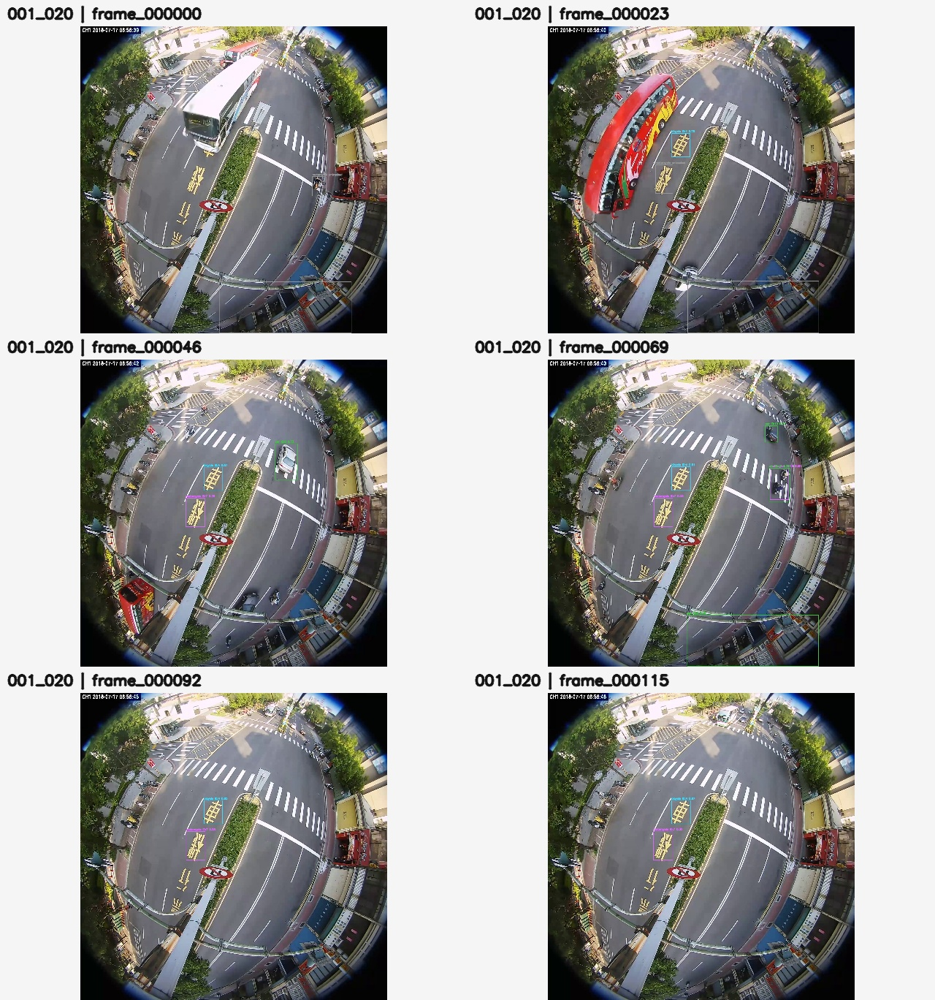


Tracking summary:
{
  "clip": "001_020",
  "status": "completed",
  "video": {
    "path": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/source_videos/001_020.mp4",
    "width": 1920,
    "height": 1920,
    "fps": 14.59119496855346,
    "reported_frames": 116,
    "decoded_frames": 116,
    "duration_seconds": 7.95
  },
  "input": {
    "detections_csv": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/target_adaptation/miotcd_fetv_test/001_020_detections.csv",
    "detection_rows": 418,
    "frames_with_detections": 112,
    "detections_by_class": {
      "motorcycle": 155,
      "car": 150,
      "bicycle": 106,
      "truck": 5,
      "van": 2
    },
    "max_timestamp_deviation_seconds": 8.881784197001252e-16
  },
  "tracking": {
    "tracked_observations": 339,
    "input_observations_without_track_id": 79,
    "untracked_results_reported_by_tracker": 79,
    "unique_tracks": 19,
    "tracked_observations_by_class": {
      "motor

,class,track_id,observations
0,bicycle,4,104
12,motorcycle,7,77
3,car,9,38
1,car,6,36
13,motorcycle,10,19
4,car,13,19
11,motorcycle,5,10
6,car,18,7
16,motorcycle,14,6
7,car,19,5



CLIP: 004_005
Contact sheet dimensions: (1280, 1368)


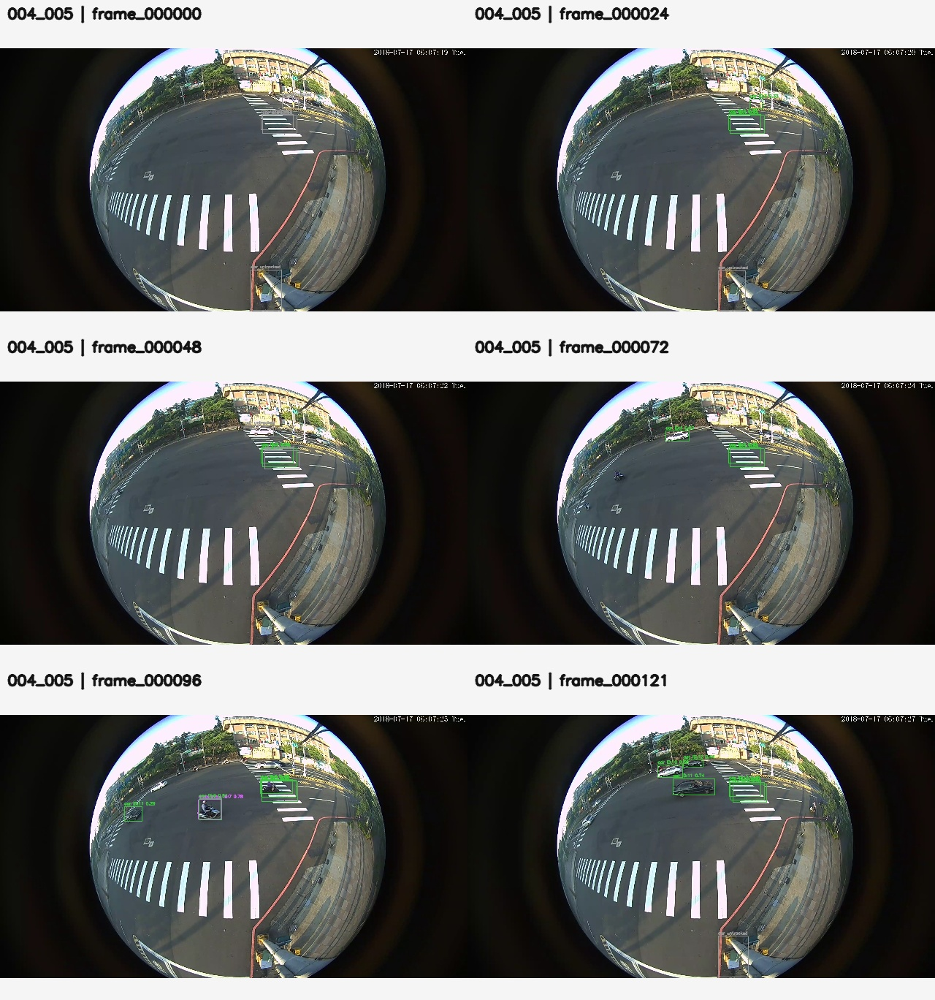


Tracking summary:
{
  "clip": "004_005",
  "status": "completed",
  "video": {
    "path": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/source_videos/004_005.mp4",
    "width": 1920,
    "height": 1080,
    "fps": 15.092783505154639,
    "reported_frames": 122,
    "decoded_frames": 122,
    "duration_seconds": 8.083333333333334
  },
  "input": {
    "detections_csv": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/target_adaptation/miotcd_fetv_test/004_005_detections.csv",
    "detection_rows": 539,
    "frames_with_detections": 122,
    "detections_by_class": {
      "car": 497,
      "motorcycle": 42
    },
    "max_timestamp_deviation_seconds": 8.881784197001252e-16
  },
  "tracking": {
    "tracked_observations": 455,
    "input_observations_without_track_id": 84,
    "untracked_results_reported_by_tracker": 84,
    "unique_tracks": 13,
    "tracked_observations_by_class": {
      "car": 421,
      "motorcycle": 34
    },
    "tr

,class,track_id,observations
0,car,1,118
1,car,2,111
3,car,4,42
6,car,10,28
2,car,3,27
7,car,11,25
5,car,9,21
11,motorcycle,7,20
4,car,6,17
8,car,12,16



CLIP: 006_020
Contact sheet dimensions: (1280, 1368)


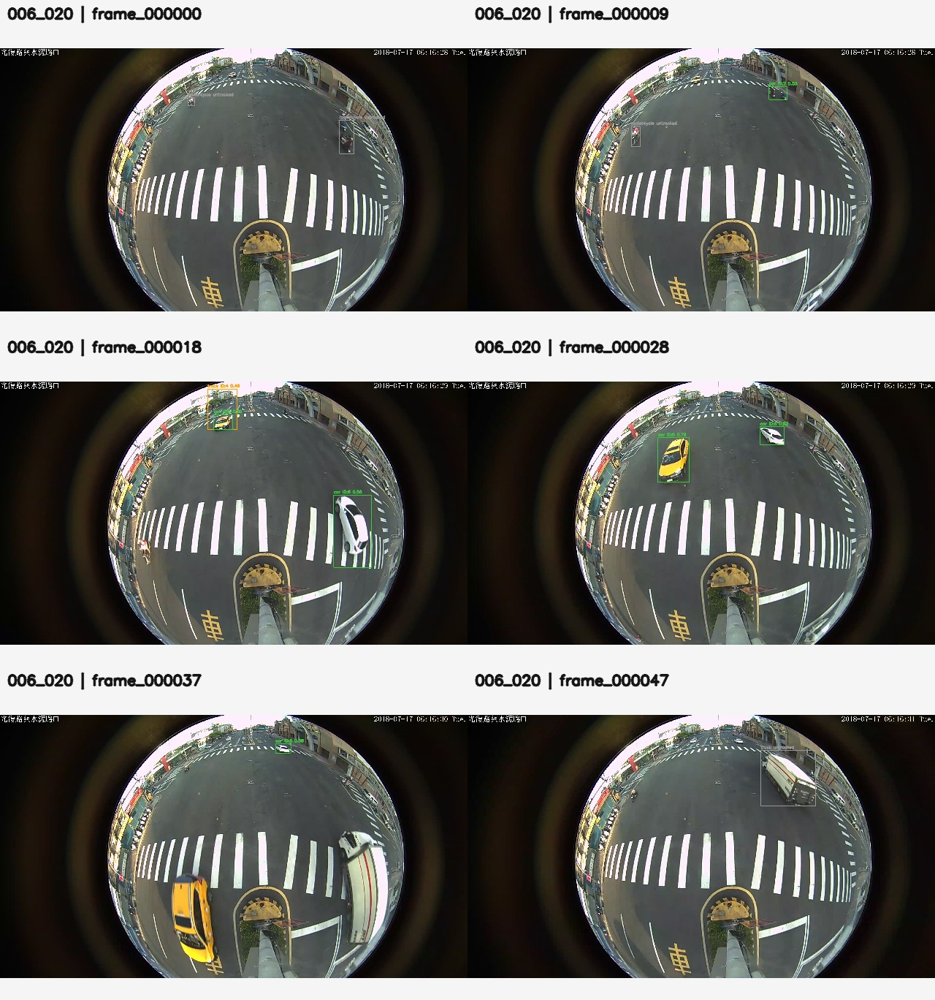


Tracking summary:
{
  "clip": "006_020",
  "status": "completed",
  "video": {
    "path": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/source_videos/006_020.mp4",
    "width": 1920,
    "height": 1080,
    "fps": 15.483870967741936,
    "reported_frames": 48,
    "decoded_frames": 48,
    "duration_seconds": 3.1
  },
  "input": {
    "detections_csv": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage2/target_adaptation/miotcd_fetv_test/006_020_detections.csv",
    "detection_rows": 103,
    "frames_with_detections": 47,
    "detections_by_class": {
      "car": 83,
      "motorcycle": 12,
      "truck": 8
    },
    "max_timestamp_deviation_seconds": 4.440892098500626e-16
  },
  "tracking": {
    "tracked_observations": 75,
    "input_observations_without_track_id": 28,
    "untracked_results_reported_by_tracker": 28,
    "unique_tracks": 8,
    "tracked_observations_by_class": {
      "car": 62,
      "motorcycle": 7,
      "truck": 6


,class,track_id,observations
3,car,6,24
2,car,5,23
0,car,2,8
6,motorcycle,1,7
7,truck,4,6
5,car,8,4
1,car,3,2
4,car,7,1


In [ ]:
#48
from pathlib import Path
from PIL import Image
from IPython.display import display
import json
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/"
    "stage3/tracking"
)

for clip in ["001_020", "004_005", "006_020"]:
    clip_dir = ROOT / clip
    sheet = clip_dir / "visualizations" / "track_contact_sheet.jpg"
    summary_file = clip_dir / "tracking_summary.json"
    tracks_file = clip_dir / "tracks.csv"

    print("\n" + "=" * 70)
    print(f"CLIP: {clip}")
    print("=" * 70)

    # Verify and display the saved visual output
    if sheet.exists():
        with Image.open(sheet) as im:
            print(f"Contact sheet dimensions: {im.size}")
            display(im.copy())
    else:
        print(f"ERROR: Contact sheet not found: {sheet}")

    # Show the saved tracking summary
    if summary_file.exists():
        with open(summary_file, "r") as f:
            summary = json.load(f)
        print("\nTracking summary:")
        print(json.dumps(summary, indent=2))
    else:
        print("ERROR: Summary JSON not found.")

    # Verify the CSV and inspect the longest tracks
    if tracks_file.exists():
        tracks = pd.read_csv(tracks_file)
        print("\nTracks CSV shape:", tracks.shape)
        print("Columns:", tracks.columns.tolist())

        if not tracks.empty:
            lengths = (
                tracks.groupby(["class", "track_id"])
                .size()
                .reset_index(name="observations")
                .sort_values("observations", ascending=False)
            )
            print("\nLongest tracks by class and ID:")
            display(lengths.head(15))
    else:
        print("ERROR: Tracks CSV not found.")


In [ ]:
#49
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system"
)
CLIP = "006_020"

det_path = (
    ROOT / "stage2/target_adaptation/miotcd_fetv_test"
    / f"{CLIP}_detections.csv"
)
track_path = ROOT / "stage3/tracking" / CLIP / "tracks.csv"

assert det_path.exists(), f"Detection CSV not found: {det_path}"
assert track_path.exists(), f"Tracks CSV not found: {track_path}"

det = pd.read_csv(det_path)
trk = pd.read_csv(track_path)

box_cols = ["x1", "y1", "x2", "y2"]
frames_to_check = [0, 9, 18, 28, 37, 47]

# Match rows by original box coordinates and class.
# Stage 3 retains the source detection's coordinates.
def is_tracked(drow, frame_tracks, tol=0.02):
    candidates = frame_tracks[
        frame_tracks["class"].astype(str) == str(drow["class"])
    ]
    for _, trow in candidates.iterrows():
        if all(
            abs(float(drow[c]) - float(trow[c])) <= tol
            for c in box_cols
        ):
            return int(trow["track_id"])
    return None

def iou(a, b):
    ix1 = max(a["x1"], b["x1"])
    iy1 = max(a["y1"], b["y1"])
    ix2 = min(a["x2"], b["x2"])
    iy2 = min(a["y2"], b["y2"])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = max(0, a["x2"] - a["x1"]) * max(0, a["y2"] - a["y1"])
    area_b = max(0, b["x2"] - b["x1"]) * max(0, b["y2"] - b["y1"])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

for frame_no in frames_to_check:
    d = det[det["frame_number"] == frame_no].copy().reset_index(drop=True)
    t = trk[trk["frame_number"] == frame_no].copy()

    print(f"\n{'=' * 22} FRAME {frame_no} {'=' * 22}")
    print(f"Stage 2 detections: {len(d)} | Stage 3 tracked rows: {len(t)}")

    if d.empty:
        print("No Stage 2 detections for this frame.")
        continue

    records = []
    for _, row in d.iterrows():
        track_id = is_tracked(row, t)
        records.append({
            "detection_index": row.name,
            "class": row["class"],
            "confidence": round(float(row["confidence"]), 3),
            "track_id": track_id if track_id is not None else "UNTRACKED",
            "x1": round(float(row["x1"]), 1),
            "y1": round(float(row["y1"]), 1),
            "x2": round(float(row["x2"]), 1),
            "y2": round(float(row["y2"]), 1),
        })

    display(pd.DataFrame(records))

    # Report substantial pairwise box overlap; this is a clue, not proof
    # that two physical vehicles were merged into one detection.
    overlaps = []
    for i in range(len(d)):
        for j in range(i + 1, len(d)):
            score = iou(d.iloc[i], d.iloc[j])
            if score >= 0.15:
                overlaps.append({
                    "detection_A": i,
                    "class_A": d.iloc[i]["class"],
                    "confidence_A": round(float(d.iloc[i]["confidence"]), 3),
                    "detection_B": j,
                    "class_B": d.iloc[j]["class"],
                    "confidence_B": round(float(d.iloc[j]["confidence"]), 3),
                    "box_IoU": round(score, 3),
                })

    print("\nDetection pairs with box IoU >= 0.15:")
    if overlaps:
        display(pd.DataFrame(overlaps).sort_values("box_IoU", ascending=False))
    else:
        print("None.")

print("\nFinished: read-only diagnostic; no outputs were modified.")



====================== FRAME 0 ======================
Stage 2 detections: 2 | Stage 3 tracked rows: 0


,detection_index,class,confidence,track_id,x1,y1,x2,y2
0,0,motorcycle,0.613,UNTRACKED,1393.8,295.4,1453.0,431.6
1,1,motorcycle,0.282,UNTRACKED,771.0,202.3,799.2,234.2



Detection pairs with box IoU >= 0.15:
None.

====================== FRAME 9 ======================
Stage 2 detections: 2 | Stage 3 tracked rows: 1


,detection_index,class,confidence,track_id,x1,y1,x2,y2
0,0,motorcycle,0.598,UNTRACKED,672.3,319.9,707.8,403.1
1,1,car,0.533,2,1238.4,156.6,1311.7,209.6



Detection pairs with box IoU >= 0.15:
None.

====================== FRAME 18 ======================
Stage 2 detections: 3 | Stage 3 tracked rows: 3


...


Detection pairs with box IoU >= 0.15:
None.

====================== FRAME 37 ======================
Stage 2 detections: 1 | Stage 3 tracked rows: 1


,detection_index,class,confidence,track_id,x1,y1,x2,y2
0,0,car,0.585,6,1131.1,118.3,1193.5,156.1



Detection pairs with box IoU >= 0.15:
None.

====================== FRAME 47 ======================
Stage 2 detections: 1 | Stage 3 tracked rows: 0


,detection_index,class,confidence,track_id,x1,y1,x2,y2
0,0,truck,0.423,UNTRACKED,1203.8,145.1,1430.1,374.4



Detection pairs with box IoU >= 0.15:
None.

Finished: read-only diagnostic; no outputs were modified.


In [ ]:
#50
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system"
)
CLIP = "006_020"

det = pd.read_csv(
    ROOT / "stage2/target_adaptation/miotcd_fetv_test"
    / f"{CLIP}_detections.csv"
)
trk = pd.read_csv(ROOT / "stage3/tracking" / CLIP / "tracks.csv")

# Display the first 12 frames, retaining every detector observation.
for frame_no in range(12):
    d = det[det.frame_number == frame_no]
    t = trk[trk.frame_number == frame_no]

    print(f"\nFrame {frame_no}: detections={len(d)}, tracked={len(t)}")

    for _, row in d.iterrows():
        same = t[t["class"].astype(str) == str(row["class"])].copy()

        # Match by the preserved source bounding box.
        match = None
        for _, candidate in same.iterrows():
            if all(
                abs(float(row[c]) - float(candidate[c])) < 0.02
                for c in ["x1", "y1", "x2", "y2"]
            ):
                match = candidate
                break

        status = (
            f"track_id={int(match.track_id)}"
            if match is not None else "UNTRACKED"
        )
        print(
            f"  {row['class']:12s} conf={row['confidence']:.3f} "
            f"{status} box=({row['x1']:.0f},{row['y1']:.0f},"
            f"{row['x2']:.0f},{row['y2']:.0f})"
        )

print("\nTrack observation ranges:")
if not trk.empty:
    ranges = (
        trk.groupby(["class", "track_id"])["frame_number"]
        .agg(first_frame="min", last_frame="max", observations="size")
        .reset_index()
        .sort_values(["class", "track_id"])
    )
    print(ranges.to_string(index=False))

print("\nRead-only diagnostic complete.")



Frame 0: detections=2, tracked=0
  motorcycle   conf=0.613 UNTRACKED box=(1394,295,1453,432)
  motorcycle   conf=0.282 UNTRACKED box=(771,202,799,234)

Frame 1: detections=1, tracked=1
  motorcycle   conf=0.800 track_id=1 box=(1371,255,1430,393)

Frame 2: detections=1, tracked=1
  motorcycle   conf=0.851 track_id=1 box=(1349,249,1415,356)

Frame 3: detections=3, tracked=1
  motorcycle   conf=0.583 UNTRACKED box=(744,227,773,278)
  motorcycle   conf=0.454 track_id=1 box=(1325,239,1379,321)
  car          conf=0.277 UNTRACKED box=(1328,243,1381,321)

Frame 4: detections=1, tracked=1
  motorcycle   conf=0.649 track_id=1 box=(1315,228,1359,298)

Frame 5: detections=2, tracked=1
  motorcycle   conf=0.774 track_id=1 box=(1300,220,1357,279)
  car          conf=0.367 UNTRACKED box=(1301,221,1357,279)

Frame 6: detections=2, tracked=2
  motorcycle   conf=0.474 track_id=1 box=(1291,213,1355,265)
  car          conf=0.473 track_id=2 box=(1293,214,1351,265)

Frame 7: detections=3, tracked=2
  car

In [ ]:
#51
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/DAA_Project/traffic-investigation-system")
STAGE3_TRACKING = PROJECT / "stage3" / "tracking"
SOURCE_VIDEOS = PROJECT / "stage3" / "source_videos"
STAGE4_ROOT = PROJECT / "stage4"
OUTPUT_ROOT = STAGE4_ROOT / "trajectories"
SCRIPT_DIR = STAGE4_ROOT / "scripts"
SCRIPT_PATH = SCRIPT_DIR / "build_trajectories.py"

SCRIPT_DIR.mkdir(parents=True, exist_ok=True)

script = r'''
import argparse
import json
import shutil
import sys
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


PROJECT = Path("/content/drive/MyDrive/DAA_Project/traffic-investigation-system")
INPUT_ROOT = PROJECT / "stage3" / "tracking"
VIDEO_ROOT = PROJECT / "stage3" / "source_videos"
STAGE4_ROOT = PROJECT / "stage4"
OUTPUT_ROOT = STAGE4_ROOT / "trajectories"

CLIPS = ["001_020", "004_005", "006_020"]
REQUIRED_COLUMNS = [
    "frame_number", "timestamp_seconds", "track_id", "class",
    "confidence", "x1", "y1", "x2", "y2",
    "x_center", "y_center",
]

FEATURE_COLUMNS = [
    "x_bottom_center", "y_bottom_center",
    "delta_t_seconds", "frame_gap",
    "delta_x_pixels", "delta_y_pixels", "displacement_pixels",
    "velocity_x_pixels_per_second",
    "velocity_y_pixels_per_second",
    "speed_pixels_per_second",
    "direction_angle_radians",
    "velocity_midpoint_timestamp_seconds",
    "acceleration_x_pixels_per_second_squared",
    "acceleration_y_pixels_per_second_squared",
    "acceleration_pixels_per_second_squared",
    "is_gap_spanning_motion", "motion_valid",
    "is_gap_free_motion", "gap_free_speed_statistic",
    "duplicate_frame_track_observation", "motion_quality_flag",
]


def json_safe(value):
    """Convert NumPy/Pandas values and non-finite floats to JSON-safe values."""
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if pd.isna(value):
        return None
    return value


def write_json(path, payload):
    path.write_text(
        json.dumps(json_safe(payload), indent=2, allow_nan=False),
        encoding="utf-8",
    )


def finite_stats(series):
    values = pd.to_numeric(series, errors="coerce").to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return {"mean": None, "median": None, "max": None}
    return {
        "mean": float(np.mean(values)),
        "median": float(np.median(values)),
        "max": float(np.max(values)),
    }


def process_clip(clip):
    input_dir = INPUT_ROOT / clip
    tracks_path = input_dir / "tracks.csv"
    video_path = VIDEO_ROOT / f"{clip}.mp4"
    out_dir = OUTPUT_ROOT / clip

    if not tracks_path.is_file():
        raise FileNotFoundError(f"Missing Stage 3 tracks: {tracks_path}")
    if not video_path.is_file():
        raise FileNotFoundError(f"Missing source video: {video_path}")

    df = pd.read_csv(tracks_path)
    if list(df.columns) != REQUIRED_COLUMNS:
        missing = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
        extra = sorted(set(df.columns) - set(REQUIRED_COLUMNS))
        raise ValueError(
            f"{clip}: Stage 3 schema mismatch. "
            f"Missing={missing}; extra={extra}; columns={list(df.columns)}"
        )
    if df.empty:
        raise ValueError(f"{clip}: tracks.csv is empty.")

    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"{clip}: cannot open source video {video_path}")
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    video_frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()

    if not np.isfinite(fps) or fps <= 0:
        raise ValueError(f"{clip}: invalid source FPS {fps}")

    # Preserve the input columns and values. Numeric helper columns are used
    # only for calculations and sorting.
    result = df.copy()
    work = pd.DataFrame(index=df.index)
    for col in [
        "frame_number", "timestamp_seconds", "track_id",
        "confidence", "x1", "y1", "x2", "y2",
        "x_center", "y_center",
    ]:
        work[col] = pd.to_numeric(df[col], errors="coerce")

    work["class_text"] = df["class"].fillna("").astype(str)
    work["x_bottom_center"] = (work["x1"] + work["x2"]) / 2.0
    work["y_bottom_center"] = work["y2"]

    n = len(df)
    feature_defaults = {
        "delta_t_seconds": np.nan,
        "frame_gap": np.nan,
        "delta_x_pixels": np.nan,
        "delta_y_pixels": np.nan,
        "displacement_pixels": np.nan,
        "velocity_x_pixels_per_second": np.nan,
        "velocity_y_pixels_per_second": np.nan,
        "speed_pixels_per_second": np.nan,
        "direction_angle_radians": np.nan,
        "velocity_midpoint_timestamp_seconds": np.nan,
        "acceleration_x_pixels_per_second_squared": np.nan,
        "acceleration_y_pixels_per_second_squared": np.nan,
        "acceleration_pixels_per_second_squared": np.nan,
    }
    for col, default in feature_defaults.items():
        result[col] = default

    result["x_bottom_center"] = work["x_bottom_center"]
    result["y_bottom_center"] = work["y_bottom_center"]
    result["is_gap_spanning_motion"] = False
    result["motion_valid"] = False
    result["is_gap_free_motion"] = False
    result["gap_free_speed_statistic"] = False

    duplicate_mask = work.duplicated(
        subset=["track_id", "frame_number"], keep=False
    )
    result["duplicate_frame_track_observation"] = duplicate_mask.to_numpy()
    result["motion_quality_flag"] = "first_observation"

    # Stable ordering for calculations; no detections/observations are added
    # or removed. Every interval's features are attached to its later row.
    calc = work.copy()
    calc["_original_index"] = np.arange(n)
    calc = calc.sort_values(
        ["track_id", "timestamp_seconds", "frame_number", "_original_index"],
        kind="mergesort",
        na_position="last",
    )

    for track_id, group in calc.groupby("track_id", sort=False, dropna=False):
        ordered_indices = group["_original_index"].astype(int).tolist()
        previous_velocity = None

        for position, idx in enumerate(ordered_indices):
            if position == 0:
                result.at[idx, "motion_quality_flag"] = "first_observation"
                continue

            prev_idx = ordered_indices[position - 1]
            prev_frame = work.at[prev_idx, "frame_number"]
            curr_frame = work.at[idx, "frame_number"]
            prev_time = work.at[prev_idx, "timestamp_seconds"]
            curr_time = work.at[idx, "timestamp_seconds"]

            frame_gap = (
                curr_frame - prev_frame
                if np.isfinite(prev_frame) and np.isfinite(curr_frame)
                else np.nan
            )
            dt = (
                curr_time - prev_time
                if np.isfinite(prev_time) and np.isfinite(curr_time)
                else np.nan
            )

            result.at[idx, "frame_gap"] = frame_gap
            result.at[idx, "delta_t_seconds"] = dt

            gap_spanning = bool(np.isfinite(frame_gap) and frame_gap > 1)
            result.at[idx, "is_gap_spanning_motion"] = gap_spanning

            # A repeated frame/track pair makes the adjacent interval
            # ambiguous. Retain the row, but do not derive motion from it.
            duplicate_pair = bool(
                duplicate_mask.iloc[idx] or duplicate_mask.iloc[prev_idx]
            )
            if duplicate_pair:
                result.at[idx, "motion_quality_flag"] = (
                    "duplicate_frame_track_observation"
                )
                previous_velocity = None
                continue

            if (
                not np.isfinite(dt) or dt <= 0
                or not np.isfinite(frame_gap) or frame_gap <= 0
            ):
                result.at[idx, "motion_quality_flag"] = "invalid_time_or_frame_interval"
                previous_velocity = None
                continue

            px = work.at[prev_idx, "x_bottom_center"]
            py = work.at[prev_idx, "y_bottom_center"]
            cx = work.at[idx, "x_bottom_center"]
            cy = work.at[idx, "y_bottom_center"]

            if not all(np.isfinite(v) for v in [px, py, cx, cy]):
                result.at[idx, "motion_quality_flag"] = "invalid_position"
                previous_velocity = None
                continue

            dx = float(cx - px)
            dy = float(cy - py)
            displacement = float(np.hypot(dx, dy))
            vx = dx / dt
            vy = dy / dt
            speed = float(np.hypot(vx, vy))
            midpoint_time = (prev_time + curr_time) / 2.0

            result.at[idx, "delta_x_pixels"] = dx
            result.at[idx, "delta_y_pixels"] = dy
            result.at[idx, "displacement_pixels"] = displacement
            result.at[idx, "velocity_x_pixels_per_second"] = vx
            result.at[idx, "velocity_y_pixels_per_second"] = vy
            result.at[idx, "speed_pixels_per_second"] = speed
            result.at[idx, "velocity_midpoint_timestamp_seconds"] = midpoint_time
            if displacement > 1e-6:
                result.at[idx, "direction_angle_radians"] = float(np.arctan2(dy, dx))

            result.at[idx, "motion_valid"] = True
            gap_free = bool(frame_gap == 1)
            result.at[idx, "is_gap_free_motion"] = gap_free
            result.at[idx, "gap_free_speed_statistic"] = gap_free

            if gap_spanning:
                result.at[idx, "motion_quality_flag"] = "gap_spanning_endpoint_average"
                # Do not calculate acceleration on a gap-spanning interval,
                # and do not bridge the gap when considering the next interval.
                previous_velocity = None
            else:
                result.at[idx, "motion_quality_flag"] = "valid_consecutive_interval"
                if previous_velocity is not None:
                    prev_vx, prev_vy, prev_midpoint = previous_velocity
                    midpoint_dt = midpoint_time - prev_midpoint
                    if np.isfinite(midpoint_dt) and midpoint_dt > 0:
                        ax = (vx - prev_vx) / midpoint_dt
                        ay = (vy - prev_vy) / midpoint_dt
                        result.at[idx, "acceleration_x_pixels_per_second_squared"] = ax
                        result.at[idx, "acceleration_y_pixels_per_second_squared"] = ay
                        result.at[idx, "acceleration_pixels_per_second_squared"] = float(
                            np.hypot(ax, ay)
                        )
                previous_velocity = (vx, vy, midpoint_time)

    # Output is sorted by track and time for downstream consumption.
    result["_sort_track"] = work["track_id"].to_numpy()
    result["_sort_time"] = work["timestamp_seconds"].to_numpy()
    result["_sort_frame"] = work["frame_number"].to_numpy()
    result["_sort_original"] = np.arange(n)
    result = result.sort_values(
        ["_sort_track", "_sort_time", "_sort_frame", "_sort_original"],
        kind="mergesort",
        na_position="last",
    ).drop(columns=["_sort_track", "_sort_time", "_sort_frame", "_sort_original"])

    # Build one summary row per observed track. Speed stats are separated so
    # gap-spanning endpoint averages are never mixed into gap-free statistics.
    summaries = []
    numeric_result = result.copy()
    for col in [
        "frame_number", "timestamp_seconds", "track_id",
        "x_bottom_center", "y_bottom_center",
        "speed_pixels_per_second", "acceleration_pixels_per_second_squared",
        "frame_gap",
    ]:
        numeric_result[col] = pd.to_numeric(numeric_result[col], errors="coerce")

    for track_id, group in numeric_result.groupby("track_id", sort=True, dropna=False):
        group = group.sort_values(
            ["timestamp_seconds", "frame_number"], kind="mergesort"
        )
        classes = sorted(set(group["class"].fillna("").astype(str)))
        frames = group["frame_number"].to_numpy(dtype=float)
        frames = frames[np.isfinite(frames)]
        times = group["timestamp_seconds"].to_numpy(dtype=float)
        times = times[np.isfinite(times)]
        first_time = float(np.min(times)) if len(times) else None
        last_time = float(np.max(times)) if len(times) else None
        first_frame = int(np.min(frames)) if len(frames) else None
        last_frame = int(np.max(frames)) if len(frames) else None

        valid_frame_gaps = np.diff(frames) if len(frames) > 1 else np.array([])
        positive_gaps = valid_frame_gaps[valid_frame_gaps > 0]
        max_frame_difference = (
            int(np.max(positive_gaps)) if len(positive_gaps) else None
        )
        missing_frames = int(np.sum(np.maximum(positive_gaps - 1, 0)))

        x = group["x_bottom_center"].to_numpy(dtype=float)
        y = group["y_bottom_center"].to_numpy(dtype=float)
        finite_xy = np.isfinite(x) & np.isfinite(y)
        x_valid, y_valid = x[finite_xy], y[finite_xy]
        net_displacement = (
            float(np.hypot(x_valid[-1] - x_valid[0], y_valid[-1] - y_valid[0]))
            if len(x_valid) >= 2 else 0.0
        )

        gapfree_speeds = group.loc[
            group["gap_free_speed_statistic"].astype(bool),
            "speed_pixels_per_second",
        ]
        all_valid_speeds = group.loc[
            group["motion_valid"].astype(bool),
            "speed_pixels_per_second",
        ]
        acceleration = group["acceleration_pixels_per_second_squared"]

        summaries.append({
            "track_id": json_safe(track_id),
            "class": classes[0] if len(classes) == 1 else ("mixed" if classes else None),
            "classes_observed": ";".join(classes),
            "class_change_count": max(0, len(group["class"].fillna("").astype(str).drop_duplicates()) - 1),
            "first_frame": first_frame,
            "last_frame": last_frame,
            "first_timestamp_seconds": first_time,
            "last_timestamp_seconds": last_time,
            "observed_duration_seconds": (
                last_time - first_time
                if first_time is not None and last_time is not None else None
            ),
            "n_observations": int(len(group)),
            "n_single_observation_track": bool(len(group) == 1),
            "net_displacement_pixels": net_displacement,
            "max_frame_difference": max_frame_difference,
            "max_missing_frames_between_observations": (
                max(0, max_frame_difference - 1)
                if max_frame_difference is not None else 0
            ),
            "total_missing_frames_between_observations": missing_frames,
            "n_valid_motion_intervals": int(group["motion_valid"].astype(bool).sum()),
            "n_gap_spanning_intervals": int(group["is_gap_spanning_motion"].astype(bool).sum()),
            "n_gap_free_motion_intervals": int(group["is_gap_free_motion"].astype(bool).sum()),
            "n_invalid_or_unavailable_motion_intervals": int(
                len(group) - 1 - group["motion_valid"].astype(bool).sum()
                if len(group) > 0 else 0
            ),
            "n_valid_acceleration_estimates": int(acceleration.notna().sum()),
            "gap_free_speed_mean_pixels_per_second": finite_stats(gapfree_speeds)["mean"],
            "gap_free_speed_median_pixels_per_second": finite_stats(gapfree_speeds)["median"],
            "gap_free_speed_max_pixels_per_second": finite_stats(gapfree_speeds)["max"],
            "all_valid_interval_speed_mean_pixels_per_second": finite_stats(all_valid_speeds)["mean"],
            "all_valid_interval_speed_median_pixels_per_second": finite_stats(all_valid_speeds)["median"],
            "all_valid_interval_speed_max_pixels_per_second": finite_stats(all_valid_speeds)["max"],
            "acceleration_magnitude_mean_pixels_per_second_squared": finite_stats(acceleration)["mean"],
            "acceleration_magnitude_max_pixels_per_second_squared": finite_stats(acceleration)["max"],
        })

    summary_df = pd.DataFrame(summaries)

    # Visualizations: image-coordinate paths and speed over interval midpoint.
    viz_dir = out_dir / "visualizations"
    viz_dir.mkdir(parents=True, exist_ok=True)

    fig, ax = plt.subplots(figsize=(12, 8))
    cmap = plt.get_cmap("tab20")
    for j, (track_id, group) in enumerate(numeric_result.groupby("track_id", sort=True)):
        group = group.sort_values(["timestamp_seconds", "frame_number"])
        x = group["x_bottom_center"].to_numpy(dtype=float)
        y = group["y_bottom_center"].to_numpy(dtype=float)
        valid = np.isfinite(x) & np.isfinite(y)
        if not valid.any():
            continue
        ax.plot(x[valid], y[valid], marker=".", markersize=3, linewidth=1.2,
                color=cmap(j % 20), label=f"ID {track_id}")
        first = np.flatnonzero(valid)[0]
        ax.annotate(str(track_id), (x[first], y[first]), fontsize=8)
    ax.set_xlim(0, width)
    ax.set_ylim(height, 0)
    ax.set_xlabel("Image x (pixels)")
    ax.set_ylabel("Image y (pixels; increases downward)")
    ax.set_title(f"{clip}: observed bottom-center trajectories")
    ax.grid(True, alpha=0.25)
    if summary_df.shape[0] <= 25:
        ax.legend(loc="best", fontsize=7, ncol=2)
    fig.tight_layout()
    fig.savefig(viz_dir / "trajectory_plot.png", dpi=160)
    plt.close(fig)

    # Plot the two longest tracks by observation count, deterministic tie-break.
    top_tracks = (
        summary_df.sort_values(["n_observations", "track_id"], ascending=[False, True])
        .head(2)["track_id"].tolist()
    )
    for track_id in top_tracks:
        group = numeric_result[numeric_result["track_id"] == track_id].copy()
        group = group.sort_values(["timestamp_seconds", "frame_number"])
        midpoint = pd.to_numeric(
            group["velocity_midpoint_timestamp_seconds"], errors="coerce"
        )
        speed = pd.to_numeric(group["speed_pixels_per_second"], errors="coerce")
        gapfree = group["gap_free_speed_statistic"].astype(bool)
        gapspan = group["is_gap_spanning_motion"].astype(bool) & group["motion_valid"].astype(bool)

        fig, ax = plt.subplots(figsize=(10, 4.5))
        ax.plot(midpoint[gapfree], speed[gapfree], marker="o", markersize=3,
                linewidth=1.2, label="Gap-free interval speed")
        ax.scatter(midpoint[gapspan], speed[gapspan], marker="x", s=35,
                   label="Gap-spanning endpoint average")
        ax.set_xlabel("Interval midpoint timestamp (seconds)")
        ax.set_ylabel("Image-plane speed (pixels/second)")
        ax.set_title(f"{clip}: speed vs time — track {track_id}")
        ax.grid(True, alpha=0.3)
        ax.legend()
        fig.tight_layout()
        fig.savefig(viz_dir / f"speed_track_{track_id}.png", dpi=160)
        plt.close(fig)

    result_path = out_dir / "trajectory_points.csv"
    summary_path = out_dir / "track_summaries.csv"
    result.to_csv(result_path, index=False)
    summary_df.to_csv(summary_path, index=False)

    # Output-level counters for quick review.
    frame_gap_series = pd.to_numeric(result["frame_gap"], errors="coerce")
    trajectory_summary = {
        "clip": clip,
        "generated_utc": datetime.now(timezone.utc).isoformat(),
        "status": "completed",
        "input_tracks_csv": str(tracks_path),
        "source_video": str(video_path),
        "outputs": {
            "trajectory_points_csv": str(result_path),
            "track_summaries_csv": str(summary_path),
            "visualizations_dir": str(viz_dir),
        },
        "source_video_metadata": {
            "fps": fps, "width": width, "height": height,
            "reported_frame_count": video_frame_count,
        },
        "input_observations": int(len(df)),
        "output_observations": int(len(result)),
        "unique_track_ids": int(df["track_id"].nunique(dropna=True)),
        "classes": {
            str(k): int(v) for k, v in df["class"].fillna("UNKNOWN").value_counts().items()
        },
        "motion_quality_counts": {
            str(k): int(v) for k, v in result["motion_quality_flag"].value_counts().items()
        },
        "valid_motion_intervals": int(result["motion_valid"].astype(bool).sum()),
        "gap_spanning_intervals": int(result["is_gap_spanning_motion"].astype(bool).sum()),
        "gap_free_motion_intervals": int(result["is_gap_free_motion"].astype(bool).sum()),
        "valid_acceleration_estimates": int(result["acceleration_pixels_per_second_squared"].notna().sum()),
        "duplicate_frame_track_observations": int(result["duplicate_frame_track_observation"].astype(bool).sum()),
        "max_frame_difference_observed": (
            int(frame_gap_series.max()) if frame_gap_series.notna().any() else None
        ),
        "gap_policy": {
            "policy": "retain_and_flag",
            "endpoint_average_velocity": "computed for positive-time valid intervals, including gaps",
            "gap_spanning_flag": "frame difference > 1",
            "acceleration": "computed only from two consecutive gap-free valid velocity intervals",
            "gap_free_speed_statistics": "include only valid intervals with frame difference exactly 1",
        },
        "coordinate_semantics": {
            "reference_point": "bounding-box bottom-center",
            "x_bottom_center": "(x1 + x2) / 2",
            "y_bottom_center": "y2",
            "units": "pixels and seconds; not calibrated real-world speed",
            "direction_angle": "atan2(delta_y, delta_x); image y increases downward",
        },
        "processing_rules": [
            "No interpolation or smoothing",
            "No detection inference or retracking",
            "Original Stage 3 observations retained; output sorted by track_id, timestamp, frame",
            "Undefined motion values are empty CSV fields, not fabricated zeros",
        ],
    }

    config = {
        "stage": 4,
        "clip": clip,
        "script": "build_trajectories.py",
        "generated_utc": datetime.now(timezone.utc).isoformat(),
        "source_tracks_csv": str(tracks_path),
        "source_video": str(video_path),
        "output_directory": str(out_dir),
        "source_video_fps": fps,
        "source_video_width": width,
        "source_video_height": height,
        "source_video_reported_frame_count": video_frame_count,
        "required_input_columns": REQUIRED_COLUMNS,
        "added_feature_columns": FEATURE_COLUMNS,
        "position_reference": "bounding-box bottom-center",
        "time_source": "timestamp_seconds from Stage 3 tracks.csv",
        "velocity_definition": "displacement between observed bottom-centers divided by timestamp difference",
        "acceleration_definition": "difference between consecutive gap-free interval velocity vectors divided by their midpoint-time difference",
        "gap_definition": "frame_gap > 1 means gap-spanning interval",
        "gap_policy": "retain endpoint-average velocity across valid-time gaps, flag it, exclude it from acceleration and gap-free speed statistics",
        "direction_angle_definition": "atan2(delta_y_pixels, delta_x_pixels), radians, image y increases downward",
        "direction_epsilon_pixels": 1e-6,
        "smoothing": False,
        "interpolation": False,
        "detector_or_tracker_rerun": False,
        "limitations": [
            "Coordinates and speeds are in image pixels, not calibrated physical units.",
            "Bottom-center is a bounding-box proxy, not verified physical road contact.",
            "Detector misses and tracker ID fragmentation/class confusion remain upstream limitations.",
            "Gap-spanning velocity is an endpoint average and does not describe unobserved intermediate motion.",
            "Acceleration is unavailable for gap-spanning intervals and whenever two consecutive gap-free velocity estimates are unavailable.",
        ],
    }

    write_json(out_dir / "trajectory_config.json", config)
    write_json(out_dir / "trajectory_summary.json", trajectory_summary)

    print(
        f"[{clip}] DONE: observations {len(df)} -> {len(result)}, "
        f"tracks={df['track_id'].nunique()}, "
        f"valid intervals={trajectory_summary['valid_motion_intervals']}, "
        f"gap intervals={trajectory_summary['gap_spanning_intervals']}, "
        f"acceleration estimates={trajectory_summary['valid_acceleration_estimates']}"
    )

    return trajectory_summary


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--clips", nargs="+", choices=CLIPS, default=CLIPS)
    parser.add_argument("--overwrite", action="store_true",
                        help="Explicitly replace Stage 4 outputs for selected clips.")
    args = parser.parse_args()

    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
    existing = [OUTPUT_ROOT / clip for clip in args.clips if (OUTPUT_ROOT / clip).exists()]
    run_summary_path = STAGE4_ROOT / "stage4_run_summary.json"
    if (existing or run_summary_path.exists()) and not args.overwrite:
        found = [str(p) for p in existing]
        if run_summary_path.exists():
            found.append(str(run_summary_path))
        print("REFUSING TO OVERWRITE existing Stage 4 output(s):", *found, sep="\n  ")
        print("Re-run with --overwrite only if replacement is intentional.")
        sys.exit(2)

    # Validate all selected inputs before changing any existing output.
    for clip in args.clips:
        if not (INPUT_ROOT / clip / "tracks.csv").is_file():
            raise FileNotFoundError(INPUT_ROOT / clip / "tracks.csv")
        if not (VIDEO_ROOT / f"{clip}.mp4").is_file():
            raise FileNotFoundError(VIDEO_ROOT / f"{clip}.mp4")

    run_records = []
    for clip in args.clips:
        out_dir = OUTPUT_ROOT / clip
        if out_dir.exists():
            shutil.rmtree(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)
        try:
            record = process_clip(clip)
            run_records.append(record)
        except Exception as exc:
            record = {
                "clip": clip,
                "status": "failed",
                "error_type": type(exc).__name__,
                "error": str(exc),
            }
            run_records.append(record)
            write_json(out_dir / "trajectory_summary.json", record)
            print(f"[{clip}] FAILED: {type(exc).__name__}: {exc}")
            raise

    run_summary = {
        "stage": 4,
        "generated_utc": datetime.now(timezone.utc).isoformat(),
        "status": "completed" if all(r.get("status") == "completed" for r in run_records) else "failed",
        "clips_requested": args.clips,
        "clips_completed": sum(r.get("status") == "completed" for r in run_records),
        "clips_failed": sum(r.get("status") != "completed" for r in run_records),
        "total_observations_output": sum(r.get("output_observations", 0) for r in run_records),
        "per_clip": run_records,
    }
    write_json(run_summary_path, run_summary)
    print("\nRun summary:", run_summary_path)
    print(json.dumps(json_safe(run_summary), indent=2, allow_nan=False))


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH.write_text(script, encoding="utf-8")
print("Created:", SCRIPT_PATH)
print("Project exists:", PROJECT.exists())
print("Stage 3 tracking exists:", STAGE3_TRACKING.exists())
print("Source videos exist:", SOURCE_VIDEOS.exists())
print("Stage 4 output root:", OUTPUT_ROOT)

# Pilot only on the shortest clip. This intentionally refuses to overwrite
# existing Stage 4 results unless you explicitly add --overwrite.
import subprocess, sys
run = subprocess.run(
    [sys.executable, str(SCRIPT_PATH), "--clips", "006_020"],
    text=True, capture_output=True
)
print(run.stdout)
if run.stderr:
    print("STDERR:\n", run.stderr)
print("Exit code:", run.returncode)
if run.returncode != 0:
    raise RuntimeError(
        "Stage 4 pilot did not complete. Read the output above before retrying."
    )


Created: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage4/scripts/build_trajectories.py
Project exists: True
Stage 3 tracking exists: True
Source videos exist: True
Stage 4 output root: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage4/trajectories
[006_020] DONE: observations 75 -> 75, tracks=8, valid intervals=67, gap intervals=5, acceleration estimates=55

Run summary: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage4/stage4_run_summary.json
{
  "stage": 4,
  "generated_utc": "2026-10-10T17:42:36.013038+00:00",
  "status": "completed",
  "clips_requested": [
    "006_020"
  ],
  "clips_completed": 1,
  "clips_failed": 0,
  "total_observations_output": 75,
  "per_clip": [
    {
      "clip": "006_020",
      "generated_utc": "2026-10-10T17:42:35.998515+00:00",
      "status": "completed",
      "input_tracks_csv": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/006_020/tracks.csv",
      

In [ ]:
#52
from pathlib import Path
import subprocess
import sys

PROJECT = Path("/content/drive/MyDrive/DAA_Project/traffic-investigation-system")
VALIDATOR_PATH = PROJECT / "stage4" / "scripts" / "validate_trajectories.py"
VALIDATOR_PATH.parent.mkdir(parents=True, exist_ok=True)

validator = r'''
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/DAA_Project/traffic-investigation-system")
INPUT_ROOT = PROJECT / "stage3" / "tracking"
OUTPUT_ROOT = PROJECT / "stage4" / "trajectories"

ORIGINAL_COLUMNS = [
    "frame_number", "timestamp_seconds", "track_id", "class",
    "confidence", "x1", "y1", "x2", "y2", "x_center", "y_center",
]

NUMERIC_FEATURES = [
    "delta_t_seconds", "delta_x_pixels", "delta_y_pixels",
    "displacement_pixels", "velocity_x_pixels_per_second",
    "velocity_y_pixels_per_second", "speed_pixels_per_second",
    "direction_angle_radians",
    "acceleration_x_pixels_per_second_squared",
    "acceleration_y_pixels_per_second_squared",
    "acceleration_pixels_per_second_squared",
]

def close(a, b, label, atol=1e-7, rtol=1e-8):
    if not (np.isfinite(a) and np.isfinite(b) and np.isclose(a, b, atol=atol, rtol=rtol)):
        raise AssertionError(f"{label}: expected {b!r}, got {a!r}")

def validate_clip(clip):
    src = INPUT_ROOT / clip / "tracks.csv"
    out = OUTPUT_ROOT / clip
    points_path = out / "trajectory_points.csv"
    summaries_path = out / "track_summaries.csv"
    config_path = out / "trajectory_config.json"
    summary_path = out / "trajectory_summary.json"

    for p in [src, points_path, summaries_path, config_path, summary_path]:
        assert p.is_file(), f"{clip}: missing file: {p}"

    original = pd.read_csv(src)
    points = pd.read_csv(points_path)
    summaries = pd.read_csv(summaries_path)
    config = json.loads(config_path.read_text(encoding="utf-8"))
    summary = json.loads(summary_path.read_text(encoding="utf-8"))

    assert list(original.columns) == ORIGINAL_COLUMNS, f"{clip}: source schema changed"
    assert len(points) == len(original), (
        f"{clip}: observation count changed: {len(original)} -> {len(points)}"
    )
    assert all(c in points.columns for c in ORIGINAL_COLUMNS), (
        f"{clip}: one or more original columns missing"
    )

    # Compare the original 11 fields as multisets after canonical sorting.
    # This checks that rows and original values were preserved, independent
    # of the builder's output ordering.
    sort_cols = ["track_id", "timestamp_seconds", "frame_number"]
    a = original[ORIGINAL_COLUMNS].sort_values(sort_cols, kind="mergesort").reset_index(drop=True)
    b = points[ORIGINAL_COLUMNS].sort_values(sort_cols, kind="mergesort").reset_index(drop=True)
    pd.testing.assert_frame_equal(
        a, b, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-10
    )

    assert not points.duplicated(["frame_number", "track_id"]).any(), (
        f"{clip}: duplicate frame/track observations in output"
    )
    assert not points["duplicate_frame_track_observation"].astype(bool).any(), (
        f"{clip}: builder flagged duplicate frame/track rows"
    )
    assert points["track_id"].nunique() == original["track_id"].nunique()
    assert len(summaries) == original["track_id"].nunique()
    assert summary["input_observations"] == len(original)
    assert summary["output_observations"] == len(original)
    assert summary["unique_track_ids"] == original["track_id"].nunique()

    # Independently recompute each observed interval and the acceleration
    # support rule. Features are attached to the later observation.
    expected_valid = 0
    expected_gap = 0
    expected_gapfree = 0
    expected_acceleration = 0
    checked_intervals = 0

    work = points.copy()
    for c in [
        "frame_number", "timestamp_seconds", "track_id",
        "x1", "x2", "y2",
    ]:
        work[c] = pd.to_numeric(work[c], errors="coerce")
    work["bx"] = (work["x1"] + work["x2"]) / 2.0
    work["by"] = work["y2"]

    for track_id, g in work.groupby("track_id", sort=False):
        g = g.sort_values(["timestamp_seconds", "frame_number"], kind="mergesort")
        rows = list(g.iterrows())
        previous_velocity = None

        assert len(rows) >= 1
        first_idx, first = rows[0]
        assert not bool(first["motion_valid"]), f"{clip}/{track_id}: first row has motion"
        assert first["motion_quality_flag"] == "first_observation"

        for k in range(1, len(rows)):
            prev_idx, prev = rows[k - 1]
            idx, curr = rows[k]
            dt = float(curr["timestamp_seconds"] - prev["timestamp_seconds"])
            frame_gap = float(curr["frame_number"] - prev["frame_number"])

            # The known dataset has positive time/frame intervals and no duplicate pairs.
            if not (np.isfinite(dt) and dt > 0 and np.isfinite(frame_gap) and frame_gap > 0):
                assert not bool(curr["motion_valid"]), (
                    f"{clip}/{track_id}: invalid interval incorrectly marked valid"
                )
                previous_velocity = None
                continue

            dx = float(curr["bx"] - prev["bx"])
            dy = float(curr["by"] - prev["by"])
            displacement = float(np.hypot(dx, dy))
            vx, vy = dx / dt, dy / dt
            speed = float(np.hypot(vx, vy))
            midpoint = (float(curr["timestamp_seconds"]) + float(prev["timestamp_seconds"])) / 2.0
            gap_spanning = frame_gap > 1
            gap_free = frame_gap == 1

            assert bool(curr["motion_valid"]), (
                f"{clip}/{track_id} row {idx}: valid interval not marked valid"
            )
            assert bool(curr["is_gap_spanning_motion"]) == gap_spanning
            assert bool(curr["is_gap_free_motion"]) == gap_free
            assert bool(curr["gap_free_speed_statistic"]) == gap_free
            close(float(curr["delta_t_seconds"]), dt, f"{clip} dt")
            close(float(curr["frame_gap"]), frame_gap, f"{clip} frame gap")
            close(float(curr["delta_x_pixels"]), dx, f"{clip} dx")
            close(float(curr["delta_y_pixels"]), dy, f"{clip} dy")
            close(float(curr["displacement_pixels"]), displacement, f"{clip} displacement")
            close(float(curr["velocity_x_pixels_per_second"]), vx, f"{clip} vx")
            close(float(curr["velocity_y_pixels_per_second"]), vy, f"{clip} vy")
            close(float(curr["speed_pixels_per_second"]), speed, f"{clip} speed")
            close(float(curr["velocity_midpoint_timestamp_seconds"]), midpoint, f"{clip} midpoint")

            expected_valid += 1
            expected_gap += int(gap_spanning)
            expected_gapfree += int(gap_free)
            checked_intervals += 1

            if gap_spanning:
                # Endpoint velocity is retained, but cannot be used to bridge
                # acceleration calculations.
                assert pd.isna(curr["acceleration_pixels_per_second_squared"]), (
                    f"{clip}/{track_id}: acceleration emitted on gap-spanning interval"
                )
                previous_velocity = None
            else:
                if previous_velocity is not None:
                    pvx, pvy, p_midpoint = previous_velocity
                    midpoint_dt = midpoint - p_midpoint
                    assert midpoint_dt > 0
                    ax, ay = (vx - pvx) / midpoint_dt, (vy - pvy) / midpoint_dt
                    amag = float(np.hypot(ax, ay))
                    close(float(curr["acceleration_x_pixels_per_second_squared"]), ax, f"{clip} ax")
                    close(float(curr["acceleration_y_pixels_per_second_squared"]), ay, f"{clip} ay")
                    close(float(curr["acceleration_pixels_per_second_squared"]), amag, f"{clip} acceleration")
                    expected_acceleration += 1
                else:
                    assert pd.isna(curr["acceleration_pixels_per_second_squared"]), (
                        f"{clip}/{track_id}: acceleration lacks two consecutive valid velocities"
                    )
                previous_velocity = (vx, vy, midpoint)

    assert int(points["motion_valid"].astype(bool).sum()) == expected_valid
    assert int(points["is_gap_spanning_motion"].astype(bool).sum()) == expected_gap
    assert int(points["is_gap_free_motion"].astype(bool).sum()) == expected_gapfree
    assert int(points["acceleration_pixels_per_second_squared"].notna().sum()) == expected_acceleration

    assert summary["valid_motion_intervals"] == expected_valid
    assert summary["gap_spanning_intervals"] == expected_gap
    assert summary["gap_free_motion_intervals"] == expected_gapfree
    assert summary["valid_acceleration_estimates"] == expected_acceleration
    assert config["gap_policy"].startswith("retain endpoint-average velocity")

    viz = out / "visualizations"
    assert (viz / "trajectory_plot.png").is_file(), f"{clip}: missing trajectory plot"
    assert (viz / "trajectory_plot.png").stat().st_size > 1000
    speed_plots = list(viz.glob("speed_track_*.png"))
    assert len(speed_plots) >= 1, f"{clip}: no speed plots found"
    assert all(p.stat().st_size > 1000 for p in speed_plots)

    print(
        f"PASS {clip}: rows={len(points)}, tracks={len(summaries)}, "
        f"valid_intervals={expected_valid}, gap_spanning={expected_gap}, "
        f"gap_free={expected_gapfree}, acceleration={expected_acceleration}, "
        f"speed_plots={len(speed_plots)}"
    )
    return {
        "clip": clip,
        "observations": len(points),
        "tracks": len(summaries),
        "valid_intervals": expected_valid,
        "gap_spanning": expected_gap,
        "gap_free": expected_gapfree,
        "acceleration_estimates": expected_acceleration,
    }

def main():
    clips = sys.argv[1:] or ["006_020"]
    reports = [validate_clip(c) for c in clips]
    print("\nINDEPENDENT VALIDATION PASSED")
    print(json.dumps(reports, indent=2))

if __name__ == "__main__":
    main()
'''

VALIDATOR_PATH.write_text(validator, encoding="utf-8")
print("Created validator:", VALIDATOR_PATH)

run = subprocess.run(
    [sys.executable, str(VALIDATOR_PATH), "006_020"],
    text=True, capture_output=True
)
print(run.stdout)
if run.stderr:
    print("STDERR:\n", run.stderr)
print("Exit code:", run.returncode)
if run.returncode != 0:
    raise RuntimeError("Pilot validation failed. Do not process the remaining clips yet.")


In [ ]:
#53
from pathlib import Path
import subprocess
import sys

PROJECT = Path("/content/drive/MyDrive/DAA_Project/traffic-investigation-system")
BUILDER = PROJECT / "stage4" / "scripts" / "build_trajectories.py"
VALIDATOR = PROJECT / "stage4" / "scripts" / "validate_trajectories.py"

assert BUILDER.is_file(), f"Builder missing: {BUILDER}"
assert VALIDATOR.is_file(), f"Validator missing: {VALIDATOR}"

# Explicit overwrite applies only to Stage 4 outputs for these three clips.
build = subprocess.run(
    [
        sys.executable, str(BUILDER),
        "--clips", "001_020", "004_005", "006_020",
        "--overwrite",
    ],
    text=True,
    capture_output=True,
)
print("========== STAGE 4 BUILD ==========")
print(build.stdout)
if build.stderr:
    print("BUILD STDERR:\n", build.stderr)
print("Build exit code:", build.returncode)

if build.returncode != 0:
    raise RuntimeError("Build failed. Stop here and inspect the complete error output.")

# Validate every clip, including the previously validated pilot.
validation = subprocess.run(
    [
        sys.executable, str(VALIDATOR),
        "001_020", "004_005", "006_020",
    ],
    text=True,
    capture_output=True,
)
print("\n========== INDEPENDENT VALIDATION ==========")
print(validation.stdout)
if validation.stderr:
    print("VALIDATION STDERR:\n", validation.stderr)
print("Validation exit code:", validation.returncode)

if validation.returncode != 0:
    raise RuntimeError("Validation failed. Do not declare Stage 4 complete.")

# Check the root-level run summary covers the full run.
import json

run_summary_path = PROJECT / "stage4" / "stage4_run_summary.json"
run_summary = json.loads(run_summary_path.read_text(encoding="utf-8"))

assert run_summary["status"] == "completed", run_summary
assert set(run_summary["clips_requested"]) == {"001_020", "004_005", "006_020"}
assert run_summary["clips_completed"] == 3
assert run_summary["clips_failed"] == 0

print("\nROOT RUN SUMMARY: PASS")
print("Clips completed:", run_summary["clips_completed"])
print("Total observations output:", run_summary["total_observations_output"])
print("All Stage 4 outputs independently validated.")


========== STAGE 4 BUILD ==========
[001_020] DONE: observations 339 -> 339, tracks=19, valid intervals=320, gap intervals=17, acceleration estimates=275
[004_005] DONE: observations 455 -> 455, tracks=13, valid intervals=442, gap intervals=21, acceleration estimates=395
[006_020] DONE: observations 75 -> 75, tracks=8, valid intervals=67, gap intervals=5, acceleration estimates=55

Run summary: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage4/stage4_run_summary.json
{
  "stage": 4,
  "generated_utc": "2026-10-10T17:46:08.336981+00:00",
  "status": "completed",
  "clips_requested": [
    "001_020",
    "004_005",
    "006_020"
  ],
  "clips_completed": 3,
  "clips_failed": 0,
  "total_observations_output": 869,
  "per_clip": [
    {
      "clip": "001_020",
      "generated_utc": "2026-10-10T17:46:06.082465+00:00",
      "status": "completed",
      "input_tracks_csv": "/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/001_020/tracks.c

# Stage 4 visual review

## Clip 001_020 — trajectories

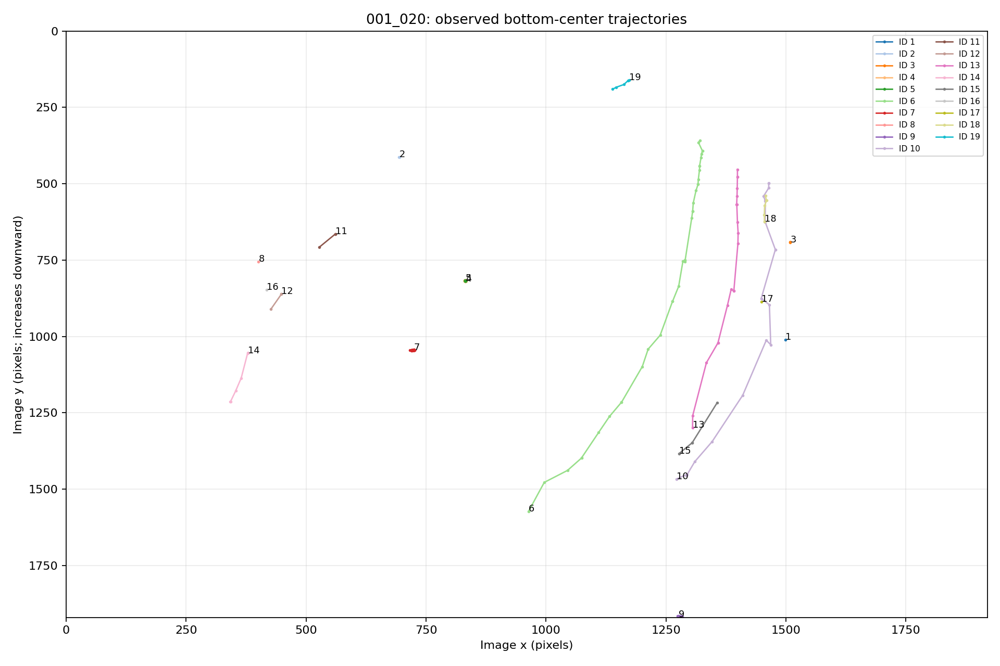

Speed plot: `speed_track_4.png`

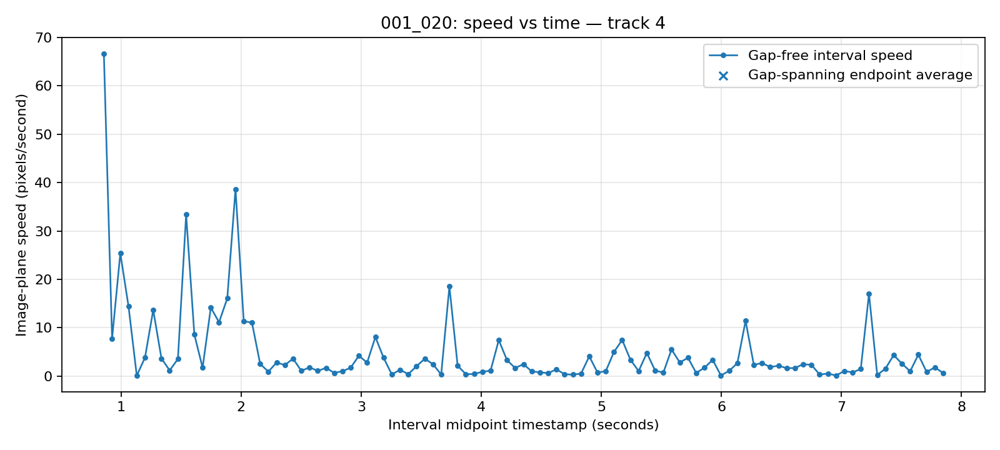

Speed plot: `speed_track_7.png`

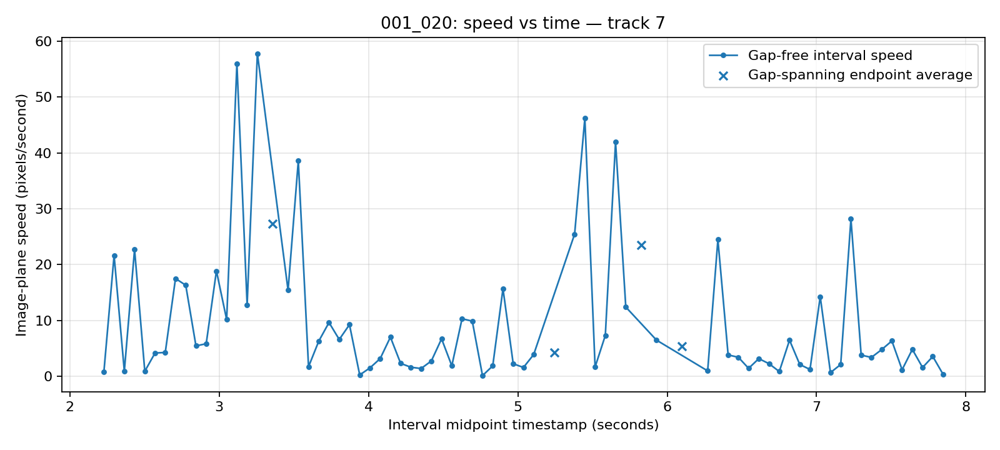

## Clip 004_005 — trajectories

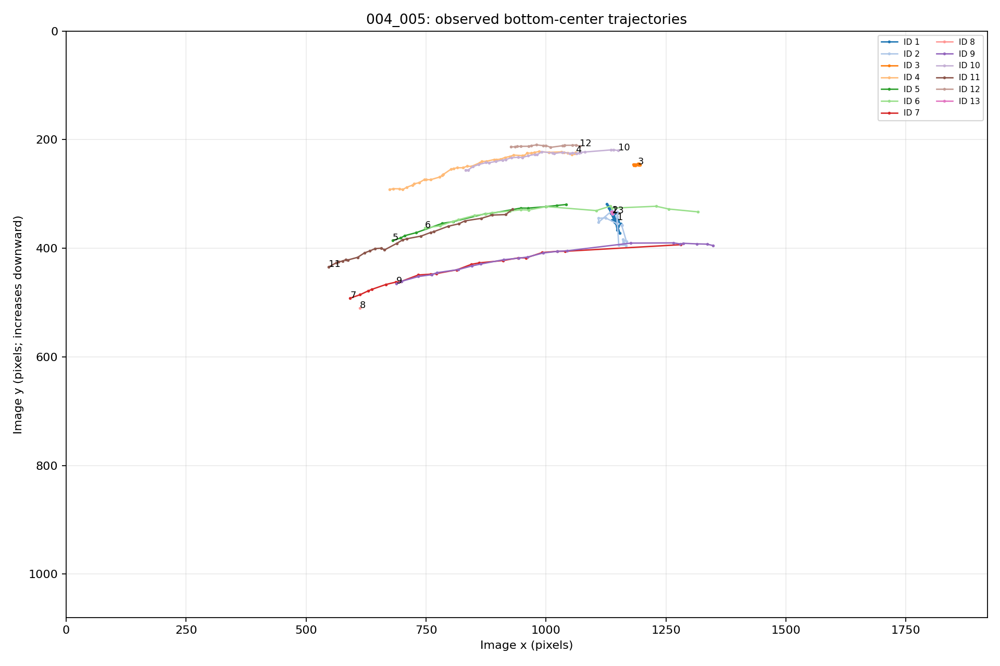

Speed plot: `speed_track_1.png`

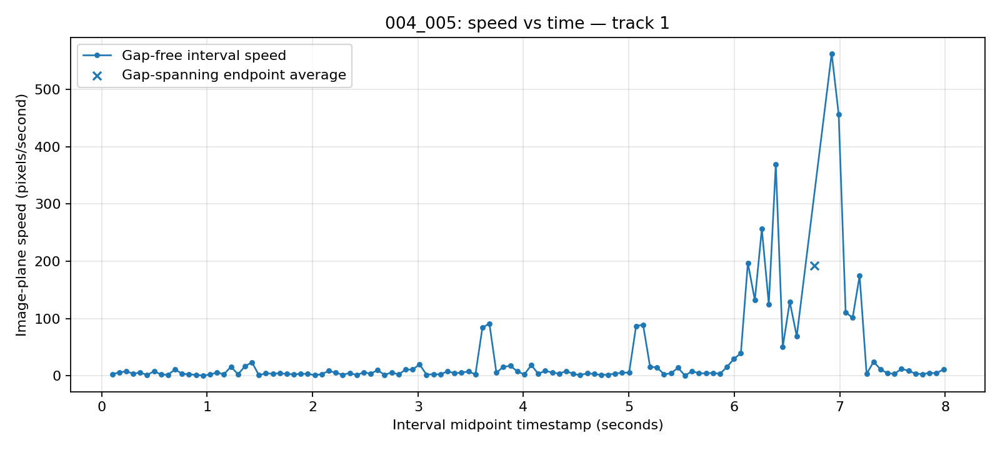

Speed plot: `speed_track_2.png`

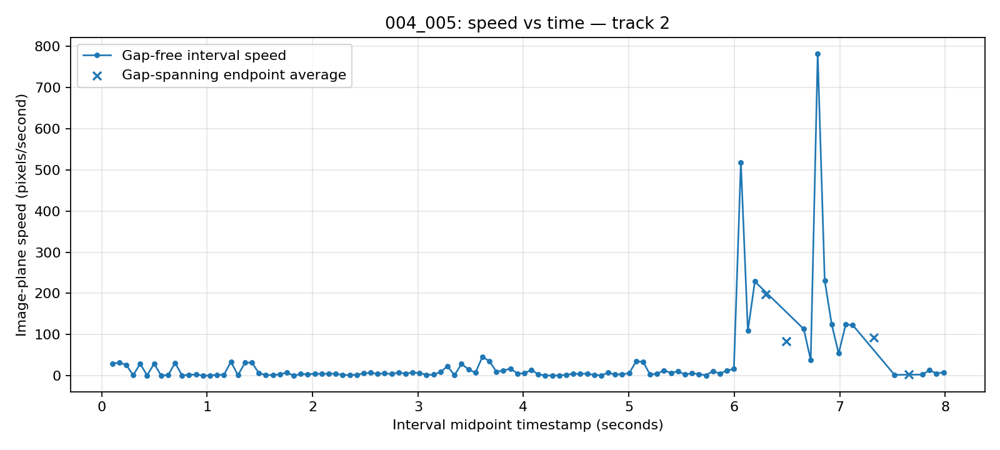

## Clip 006_020 — trajectories

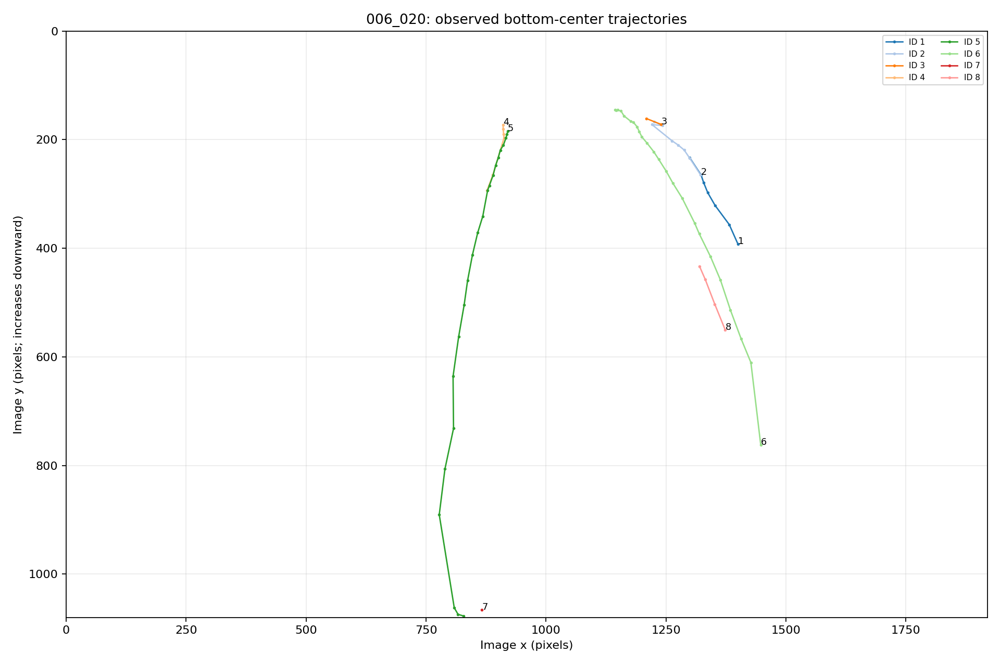

Speed plot: `speed_track_5.png`

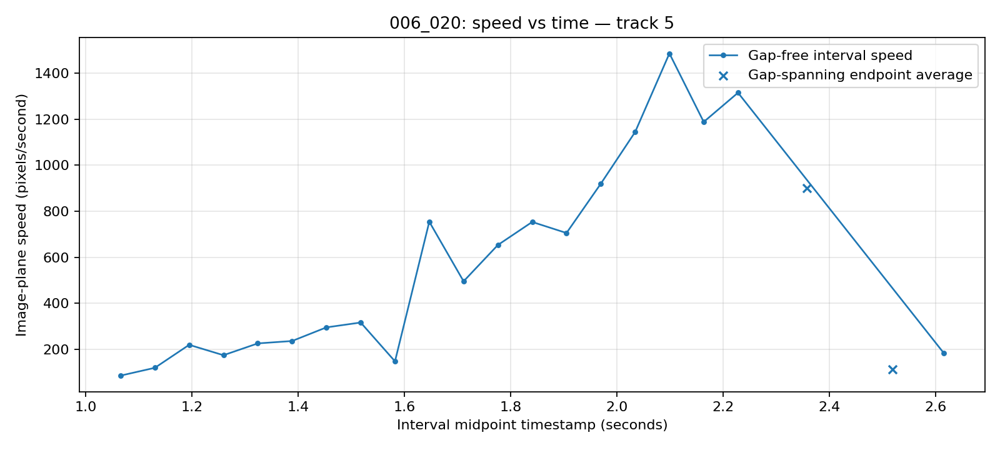

Speed plot: `speed_track_6.png`

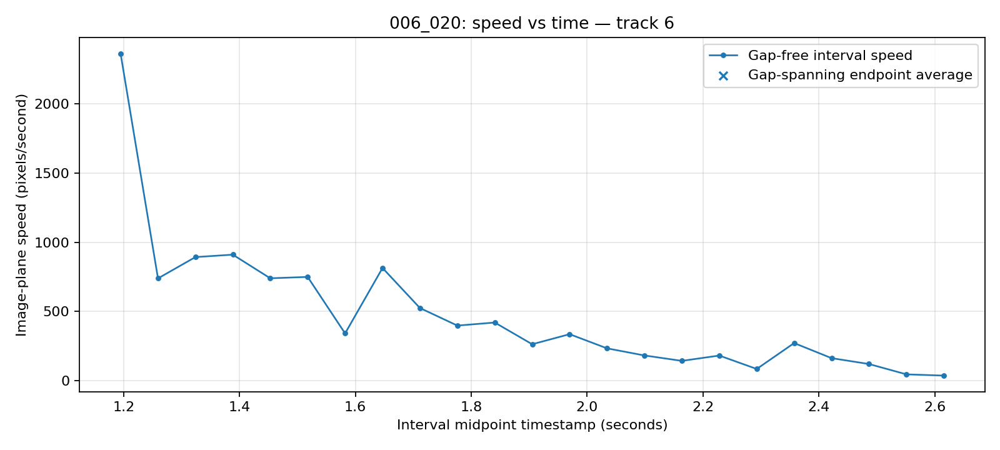


STAGE 4 HANDOFF FILE CREATED
/content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage4/README_STAGE4_HANDOFF.md

Final CSV schemas:
001_020: trajectory_points=(339, 32), track_summaries=(19, 28)
004_005: trajectory_points=(455, 32), track_summaries=(13, 28)
006_020: trajectory_points=(75, 32), track_summaries=(8, 28)

All required Stage 4 deliverables exist.


In [ ]:
#54
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

PROJECT = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system"
)
STAGE4 = PROJECT / "stage4"
TRAJECTORIES = STAGE4 / "trajectories"
RUN_SUMMARY = STAGE4 / "stage4_run_summary.json"

assert RUN_SUMMARY.is_file(), f"Missing run summary: {RUN_SUMMARY}"

run = json.loads(RUN_SUMMARY.read_text(encoding="utf-8"))
assert run["status"] == "completed"
assert run["clips_completed"] == 3
assert run["clips_failed"] == 0
assert run["total_observations_output"] == 869

clips = ["001_020", "004_005", "006_020"]

# ------------------------------------------------------------
# 1. VISUAL REVIEW: show all trajectory plots and speed plots
# ------------------------------------------------------------
display(Markdown("# Stage 4 visual review"))

for clip in clips:
    out_dir = TRAJECTORIES / clip
    trajectory_plot = out_dir / "visualizations" / "trajectory_plot.png"

    assert trajectory_plot.is_file(), f"Missing plot: {trajectory_plot}"

    display(Markdown(f"## Clip {clip} — trajectories"))
    display(Image(filename=str(trajectory_plot)))

    speed_plots = sorted(
        (out_dir / "visualizations").glob("speed_track_*.png")
    )
    assert len(speed_plots) >= 2, f"Expected speed plots for {clip}"

    for plot in speed_plots:
        display(Markdown(f"Speed plot: `{plot.name}`"))
        display(Image(filename=str(plot)))

# ------------------------------------------------------------
# 2. CREATE STAGE 4 HANDOFF DOCUMENT
# ------------------------------------------------------------
handoff = r"""# Stage 4 — Trajectory Analysis and Motion Features

## Purpose and scope

Stage 4 consumes the existing Stage 3 `tracks.csv` files and derives
per-observation trajectory coordinates and motion features. It does not
rerun detection, rerun tracking, interpolate missing observations, or
smooth trajectories.

Stage 4 is a feature-generation stage, not an incident classifier.
Its output can support downstream incident/anomaly analysis, but a
large speed, direction, or acceleration value is not by itself proof
that an incident occurred.

## Input and output locations

Project root:

`/content/drive/MyDrive/DAA_Project/traffic-investigation-system/`

Inputs:

- `stage3/tracking/001_020/tracks.csv`
- `stage3/tracking/004_005/tracks.csv`
- `stage3/tracking/006_020/tracks.csv`

Outputs, per clip, under `stage4/trajectories/<clip>/`:

- `trajectory_points.csv` — original track observations plus motion features
- `track_summaries.csv` — per-track aggregate statistics
- `trajectory_config.json` — processing configuration and conventions
- `trajectory_summary.json` — per-clip counts and metadata
- `visualizations/trajectory_plot.png` — trajectory overview
- `visualizations/speed_track_<id>.png` — speed plots for selected tracks

Stage-level run record:

- `stage4/stage4_run_summary.json`

Builder and validator scripts:

- `stage4/scripts/build_trajectories.py`
- `stage4/scripts/validate_trajectories.py`

## Results and validation

| Clip | Observations | Tracks | Valid motion intervals | Gap-spanning intervals | Gap-free intervals | Acceleration estimates |
|---|---:|---:|---:|---:|---:|---:|
| `001_020` | 339 | 19 | 320 | 17 | 303 | 275 |
| `004_005` | 455 | 13 | 442 | 21 | 421 | 395 |
| `006_020` | 75 | 8 | 67 | 5 | 62 | 55 |
| **Total** | **869** | **40 per-clip track records** | **829** | **43** | **786** | **725** |

All 869 input observations were preserved. The independent validator
passed on all three clips, including checks of original observation
preservation, recomputed motion features, gap flags, summary counts,
and plot existence.

This is structural and numerical validation, not ground-truth
validation of detector or tracker accuracy. Track IDs are local to
each video; they must not be interpreted as cross-video identities.

## Coordinate and time conventions

The existing Stage 3 columns are retained. The reference point used
for trajectory analysis is the bounding-box bottom-center:

- `x_bottom_center = (x1 + x2) / 2`
- `y_bottom_center = y2`

These coordinates are in image pixels. The bottom-center is a bounding
box proxy, not a verified physical tire/road contact point.

Time differences use `timestamp_seconds` from the track observations,
not a hardcoded frame rate. Motion units are therefore pixels/second
and pixels/second squared, not metres/second or calibrated road speed.

Image x increases to the right and image y increases downward.
Consequently, `direction_angle_radians = atan2(delta_y, delta_x)`
uses image-coordinate orientation, not a conventional upward-positive
Cartesian y-axis.

## Added motion fields

- `x_bottom_center`, `y_bottom_center`: chosen reference point.
- `delta_t_seconds`: time elapsed since the previous observation for
  the same track.
- `frame_gap`: current frame number minus the previous observation's
  frame number for that track.
- `delta_x_pixels`, `delta_y_pixels`: reference-point displacement
  components over the interval.
- `displacement_pixels`: Euclidean displacement over the interval.
- `velocity_x_pixels_per_second`, `velocity_y_pixels_per_second`:
  endpoint displacement components divided by elapsed time.
- `speed_pixels_per_second`: magnitude of the endpoint-average velocity.
- `direction_angle_radians`: `atan2(delta_y, delta_x)`.
- `velocity_midpoint_timestamp_seconds`: midpoint of the interval's
  endpoint timestamps, used for acceleration timing.
- `acceleration_x_pixels_per_second_squared`,
  `acceleration_y_pixels_per_second_squared`,
  `acceleration_pixels_per_second_squared`: acceleration estimates
  from eligible consecutive gap-free velocity intervals.
- `is_gap_spanning_motion`: marks an interval whose frame difference
  exceeds one.
- `motion_valid`: marks an interval with a valid positive elapsed time
  and calculable endpoint-average motion.
- `is_gap_free_motion`: marks valid intervals whose frame difference
  is exactly one.
- `gap_free_speed_statistic`: identifies intervals eligible for
  gap-free speed statistics.
- `duplicate_frame_track_observation`: diagnostic flag for duplicate
  frame/track observations.
- `motion_quality_flag`: indicates whether an observation is the first
  observation, a valid consecutive interval, or a gap-spanning
  endpoint-average interval.

The exact column names and order can be confirmed from the header of
`trajectory_points.csv`. The original Stage 3 fields remain present.

## Gap policy — important for downstream use

The selected policy is **retain and flag**:

1. For every valid positive-time interval, calculate endpoint-average
   velocity, including intervals that span missing frames.
2. Flag an interval as gap-spanning when `frame_gap > 1`.
3. Include only `frame_gap == 1` valid intervals in gap-free speed
   statistics.
4. Calculate acceleration only when the current and previous velocity
   intervals are both valid and gap-free. Use the difference between
   their velocity-midpoint timestamps.
5. Do not bridge a gap to estimate acceleration.
6. Undefined features are blank/NaN, not zero.

A gap-spanning velocity is an average between two observed endpoints.
It does not reveal what happened between those endpoints and may hide
stops, turns, or sudden changes. Downstream analysis should retain the
gap flag and avoid treating these intervals as equivalent to
consecutive-frame motion.

## Recommended use by Stage 5

- Use `trajectory_points.csv` for time-ordered, per-observation motion
  analysis.
- Use `track_summaries.csv` for per-track aggregate features and
  candidate ranking.
- Group by **clip and track ID**, not track ID alone.
- Sort by timestamp/frame before deriving any additional temporal
  features.
- Exclude or separately handle gap-spanning intervals when a feature
  assumes continuous observation.
- Check `motion_valid`, `is_gap_free_motion`, and `motion_quality_flag`
  before using a motion value.
- Treat extreme speeds, direction changes, and acceleration values as
  candidates for investigation, not automatic proof of an incident.
- Inspect the original frames or Stage 3 visualizations before making
  a final interpretation.

## Known limitations

- Stage 2 detections can miss small/distant vehicles, localize boxes
  imperfectly, and confuse classes or produce intermittent detections.
- Stage 3 ByteTrack IDs may fragment or switch; the input has no
  ground-truth identities, so identity accuracy has not been established.
- Stage 4 derives motion from the existing boxes and track IDs. It
  cannot repair missed detections, ID switches, or box localization errors.
- Pixel motion depends on camera perspective, object depth, and box
  quality. It is not calibrated real-world velocity.
- Sparse observations and gaps can conceal intermediate motion.
- No smoothing, interpolation, detection inference, or retracking is
  performed.
- The three clips are a small sample; these results do not establish
  generalization or incident-detection performance.

## Reproducibility

Run the builder from the Colab environment with the project on Drive.
The builder refuses to overwrite existing outputs unless the explicit
`--overwrite` option is supplied. The independent validator should be
run after a rebuild:

```bash
python stage4/scripts/build_trajectories.py --clips 001_020 004_005 006_020
python stage4/scripts/validate_trajectories.py 001_020 004_005 006_020
```

When intentionally rebuilding existing outputs, add `--overwrite` to
the builder command. Preserve the run summary and per-clip JSON files
with the CSV outputs when handing Stage 4 to teammates.
"""

readme_path = STAGE4 / "README_STAGE4_HANDOFF.md"
readme_path.write_text(handoff, encoding="utf-8")

# ------------------------------------------------------------
# 3. FINAL DELIVERABLE CHECK
# ------------------------------------------------------------
required_files = [readme_path, RUN_SUMMARY]

for clip in clips:
    folder = TRAJECTORIES / clip
    required_files.extend([
        folder / "trajectory_points.csv",
        folder / "track_summaries.csv",
        folder / "trajectory_config.json",
        folder / "trajectory_summary.json",
        folder / "visualizations" / "trajectory_plot.png",
    ])

missing = [str(path) for path in required_files if not path.is_file()]
assert not missing, "Missing deliverables:\n" + "\n".join(missing)

print("\nSTAGE 4 HANDOFF FILE CREATED")
print(readme_path)
print("\nFinal CSV schemas:")
for clip in clips:
    points = pd.read_csv(TRAJECTORIES / clip / "trajectory_points.csv")
    summaries = pd.read_csv(TRAJECTORIES / clip / "track_summaries.csv")
    print(
        f"{clip}: trajectory_points={points.shape}, "
        f"track_summaries={summaries.shape}"
    )

print("\nAll required Stage 4 deliverables exist.")


# Stage 3 annotations — 001_020

Directory: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/001_020/visualizations
Files found: 7
  selected_annotated_frames/frame_000000.jpg  (1,117,243 bytes)
  selected_annotated_frames/frame_000023.jpg  (1,077,343 bytes)
  selected_annotated_frames/frame_000046.jpg  (1,144,366 bytes)
  selected_annotated_frames/frame_000069.jpg  (1,155,910 bytes)
  selected_annotated_frames/frame_000092.jpg  (1,161,818 bytes)
  selected_annotated_frames/frame_000115.jpg  (1,167,714 bytes)
  track_contact_sheet.jpg  (714,907 bytes)


**Image: `frame_000000.jpg`**

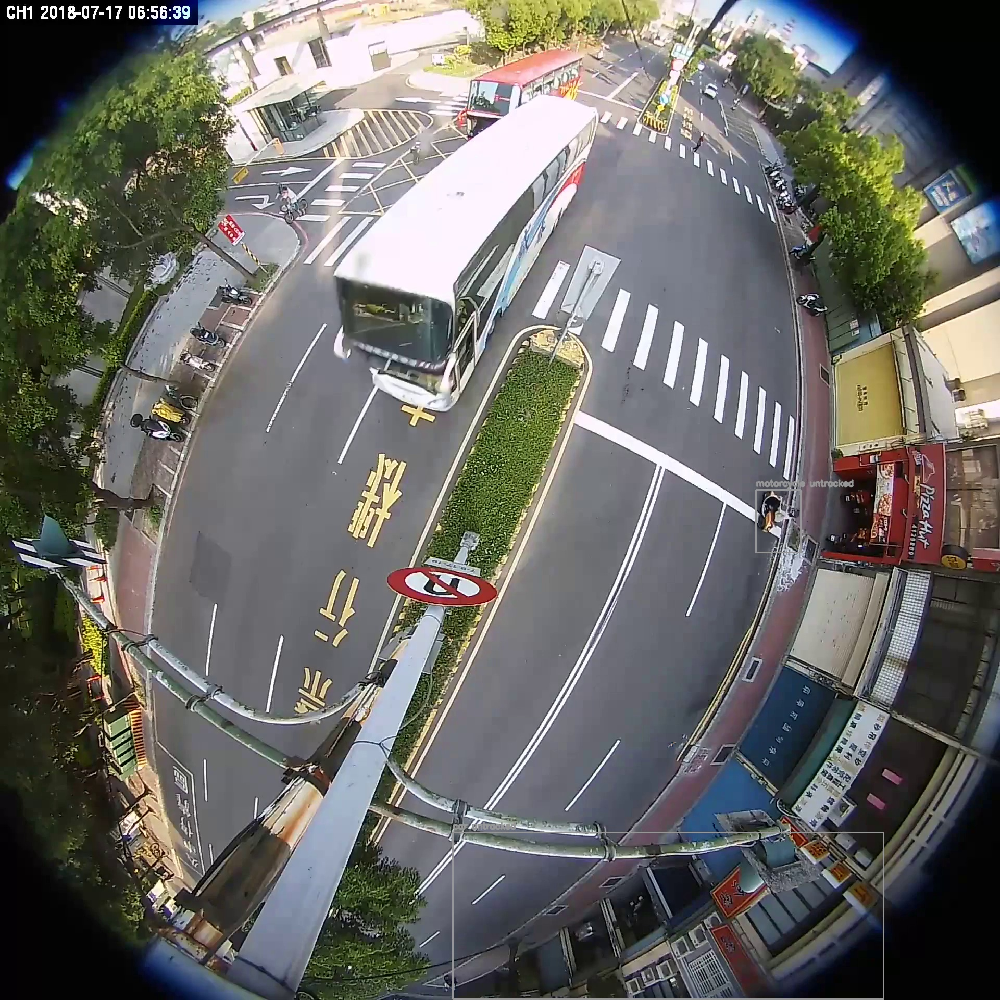

**Image: `frame_000023.jpg`**

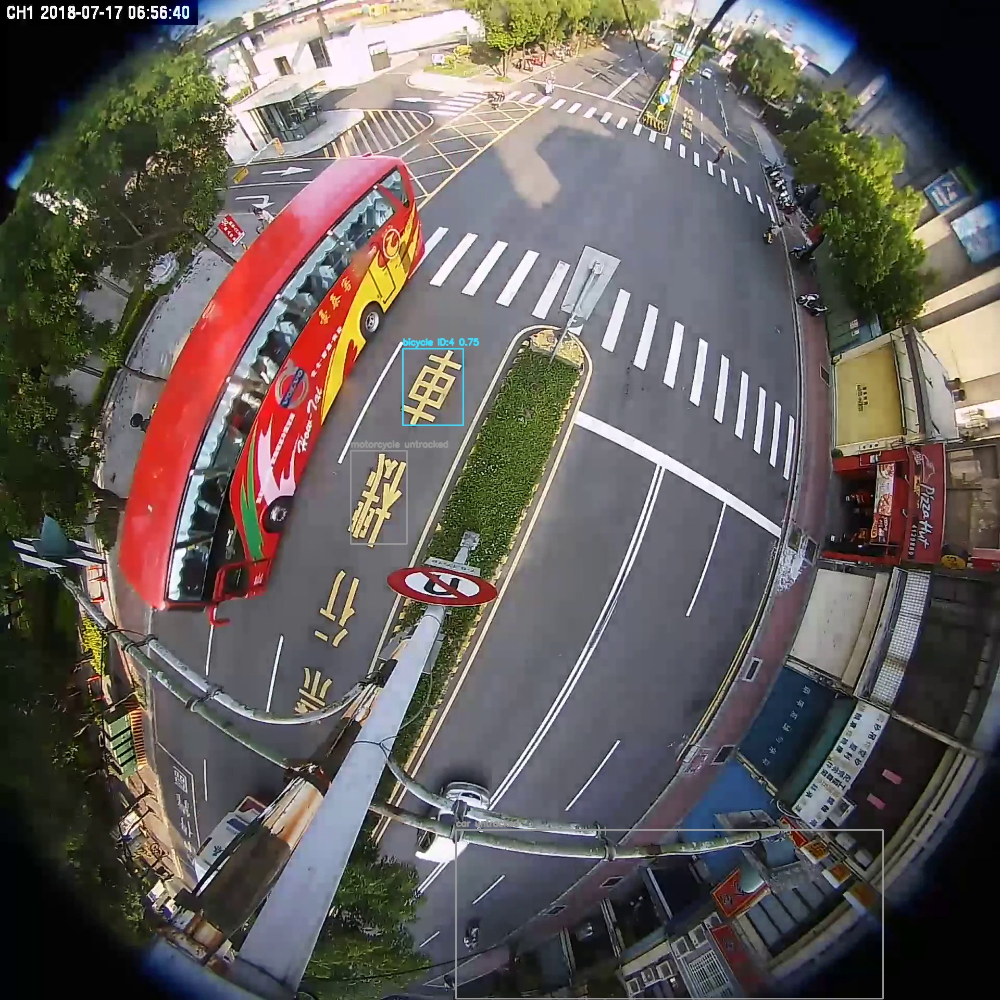

**Image: `frame_000046.jpg`**

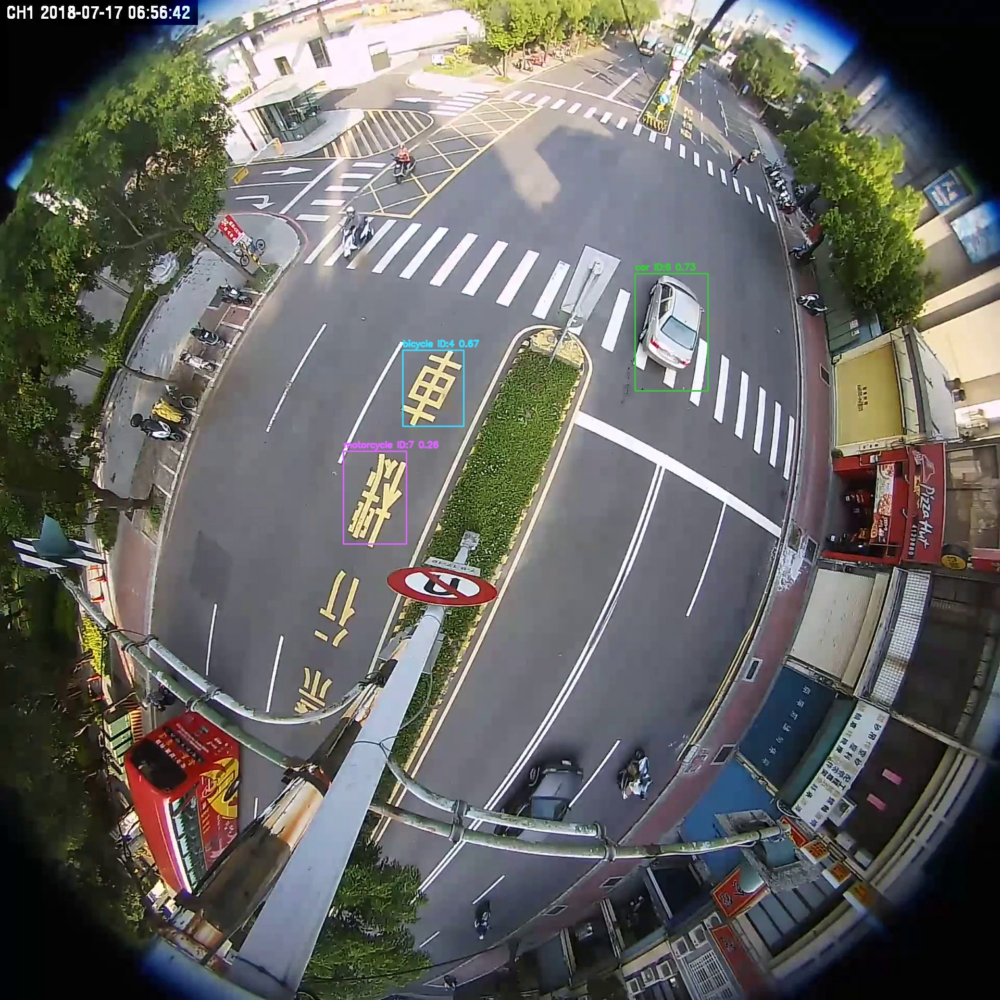

**Image: `frame_000069.jpg`**

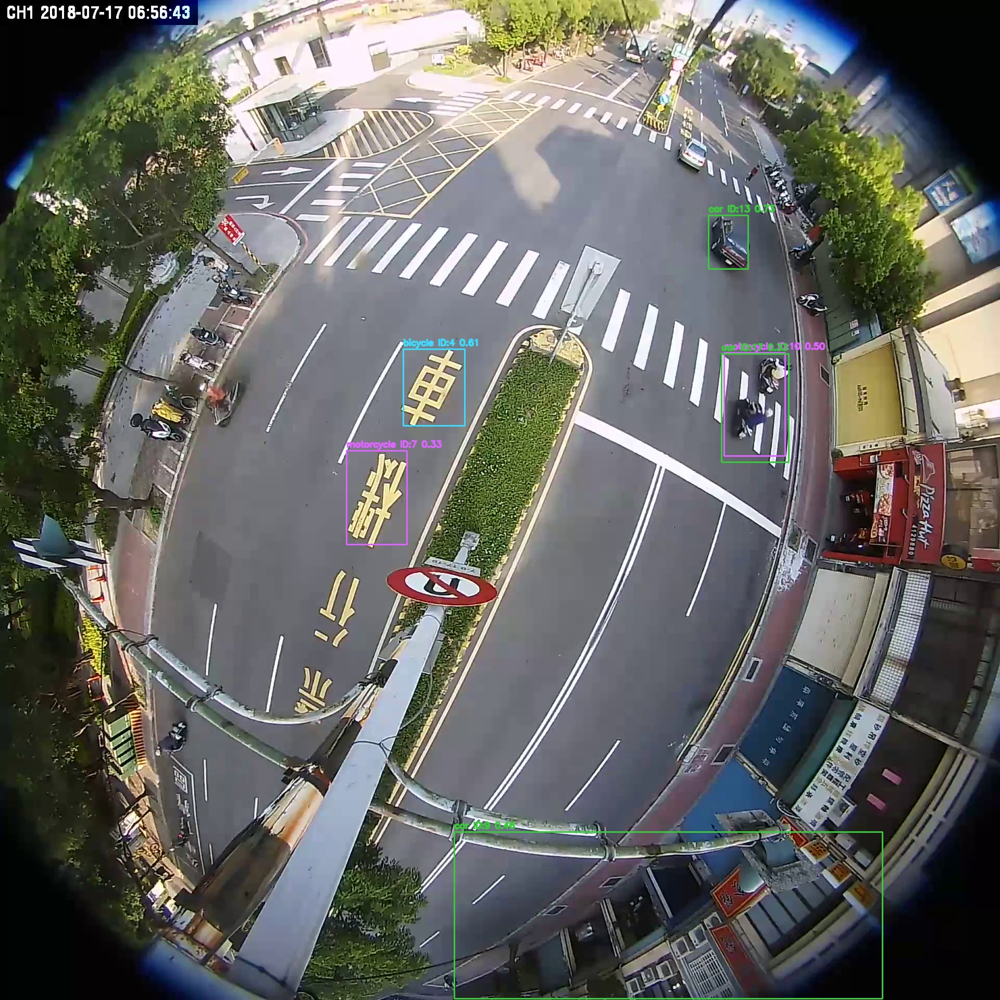

**Image: `frame_000092.jpg`**

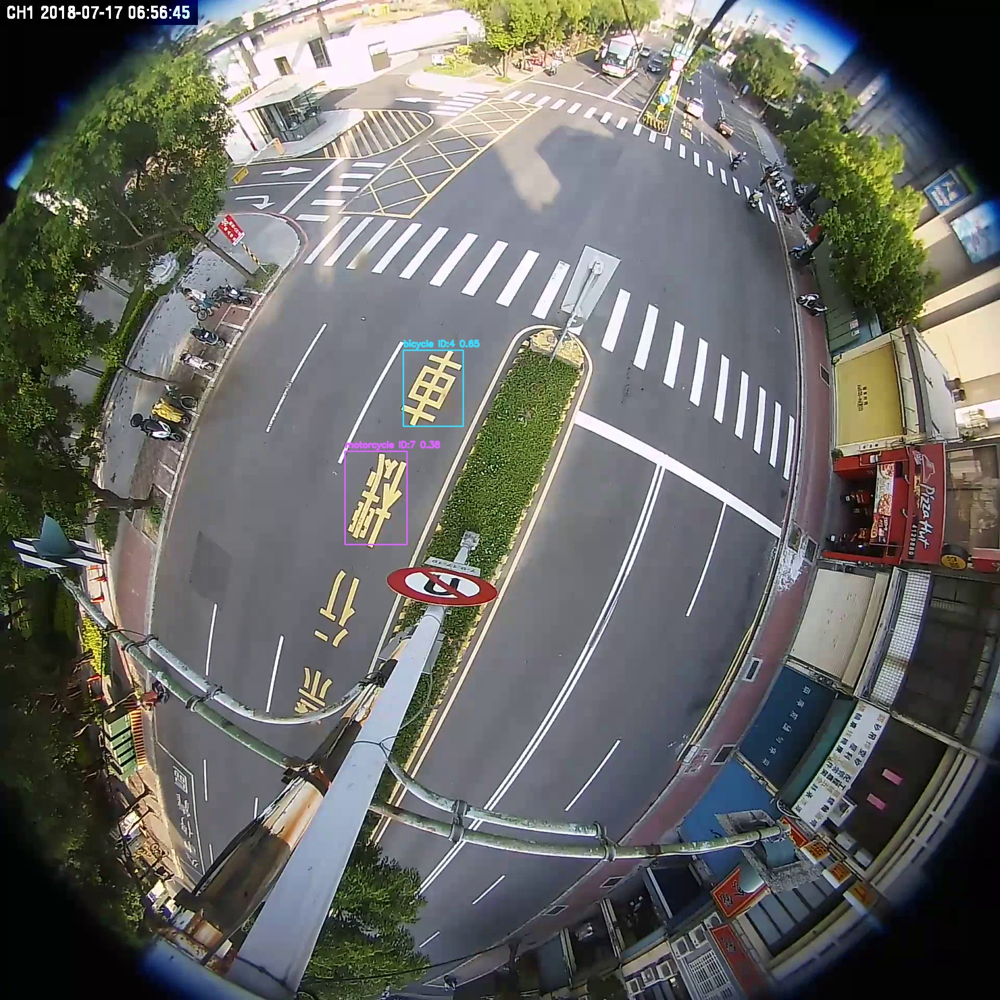

**Image: `frame_000115.jpg`**

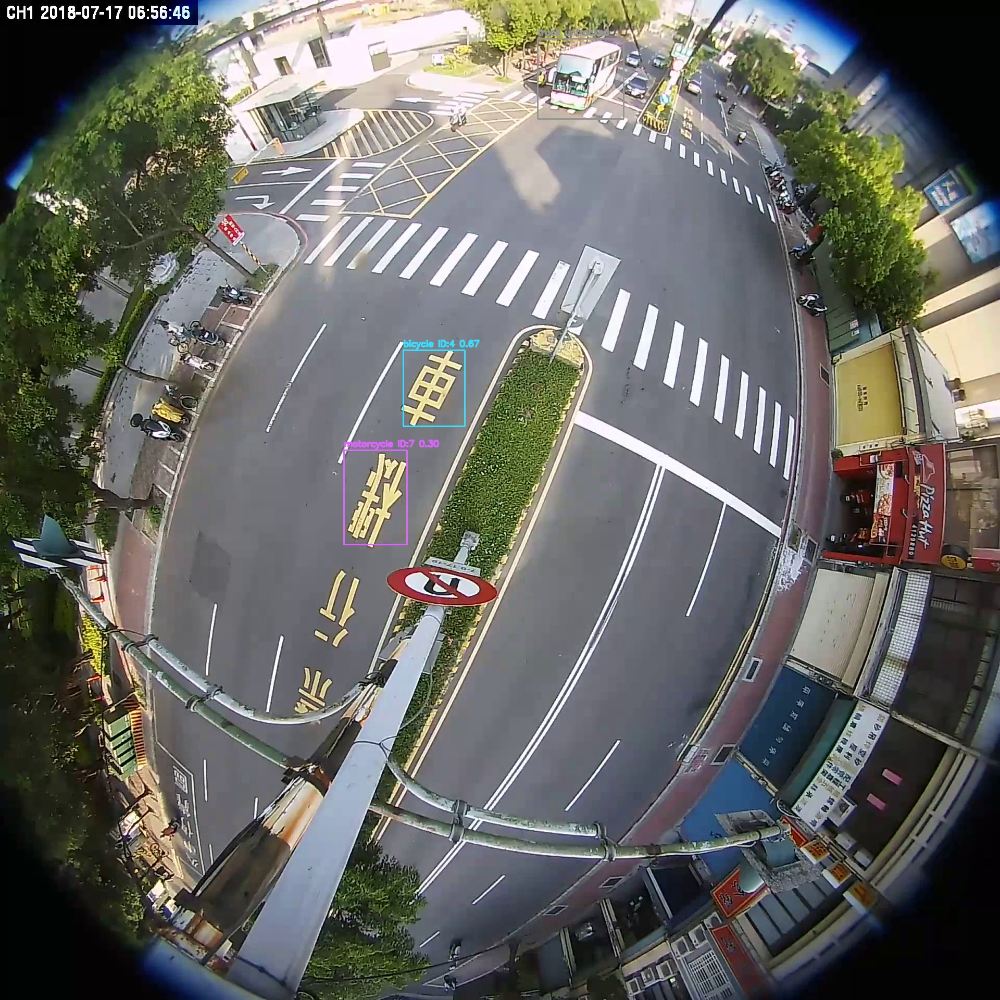

**Image: `track_contact_sheet.jpg`**

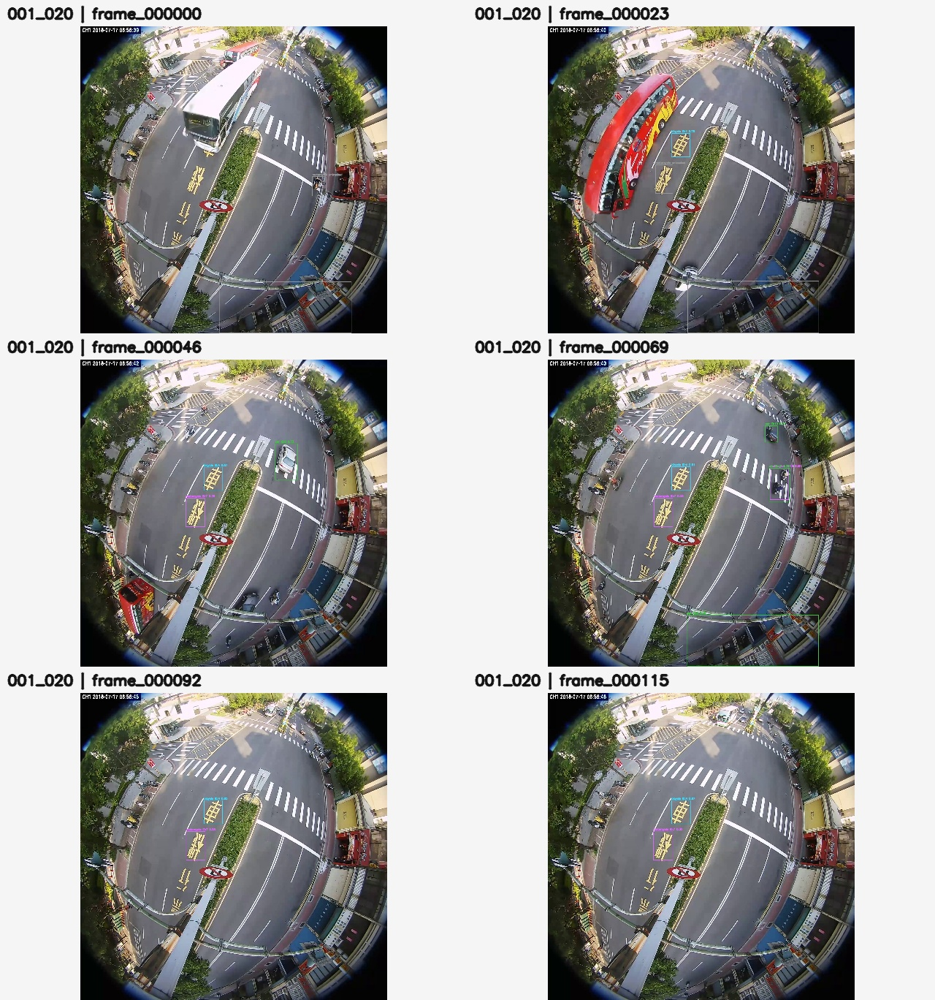

# Stage 3 annotations — 004_005

Directory: /content/drive/MyDrive/DAA_Project/traffic-investigation-system/stage3/tracking/004_005/visualizations
Files found: 7
  selected_annotated_frames/frame_000000.jpg  (409,357 bytes)
  selected_annotated_frames/frame_000024.jpg  (422,448 bytes)
  selected_annotated_frames/frame_000048.jpg  (428,951 bytes)
  selected_annotated_frames/frame_000072.jpg  (435,498 bytes)
  selected_annotated_frames/frame_000096.jpg  (448,316 bytes)
  selected_annotated_frames/frame_000121.jpg  (433,309 bytes)
  track_contact_sheet.jpg  (544,034 bytes)


**Image: `frame_000000.jpg`**

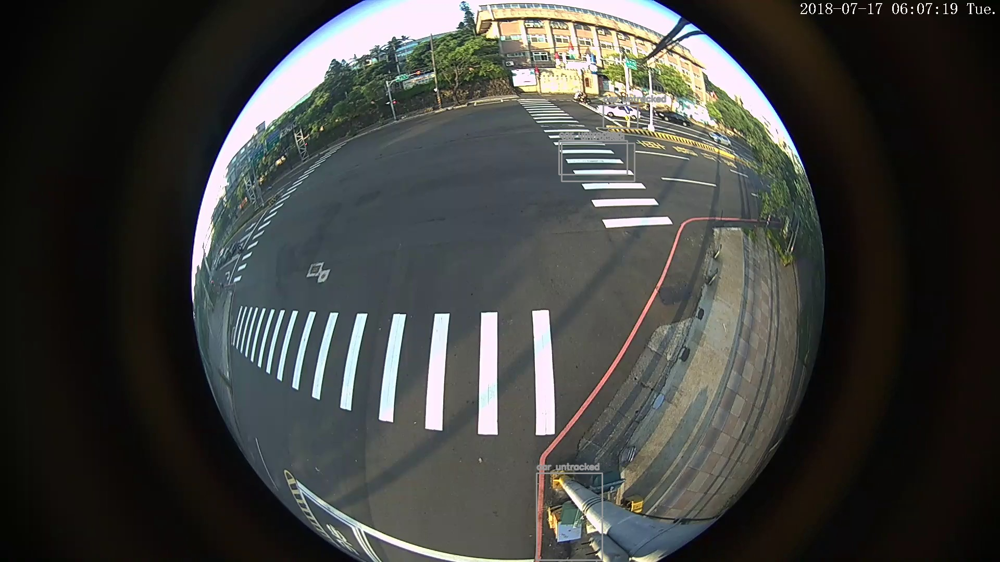

**Image: `frame_000024.jpg`**

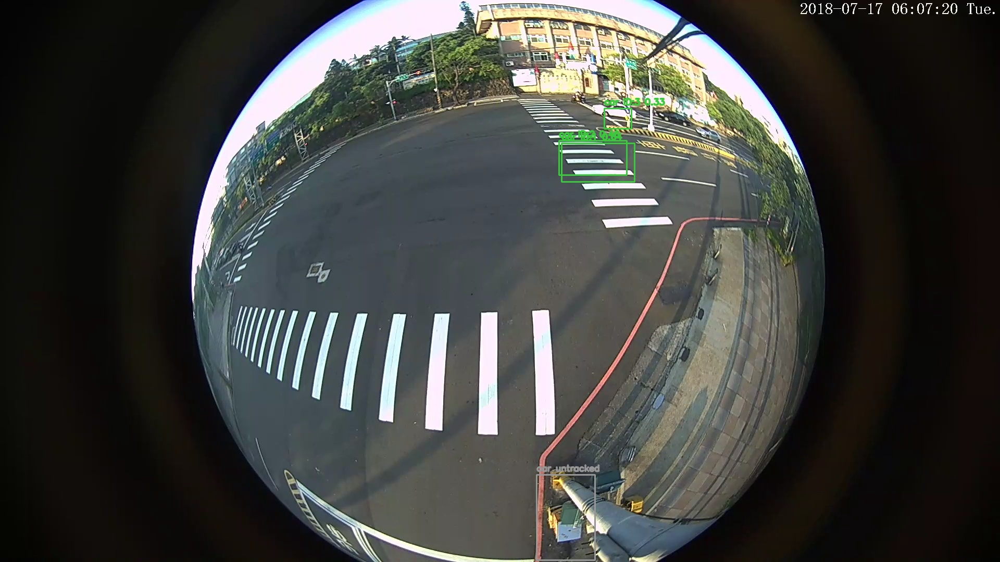

**Image: `frame_000048.jpg`**

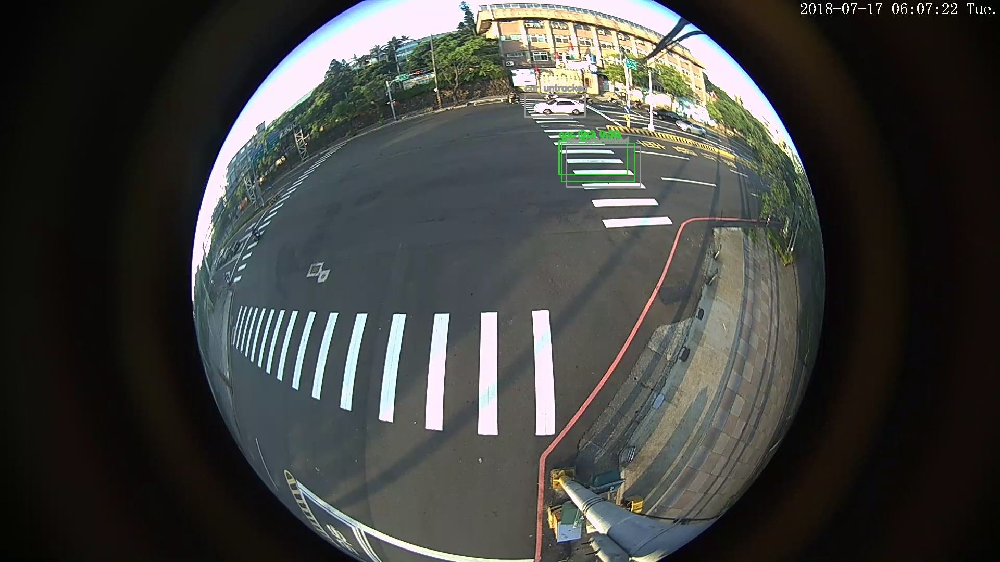

**Image: `frame_000072.jpg`**

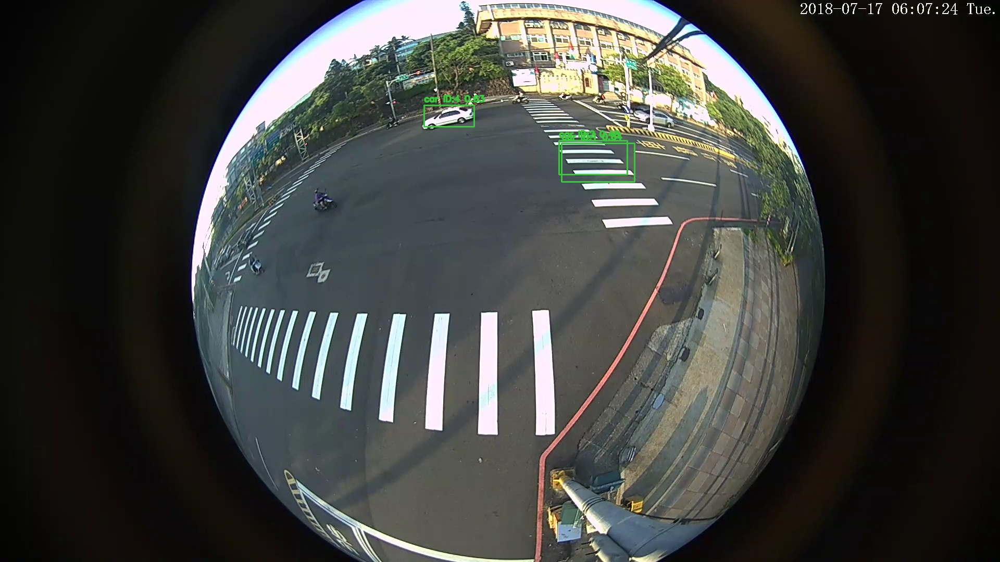

**Image: `frame_000096.jpg`**

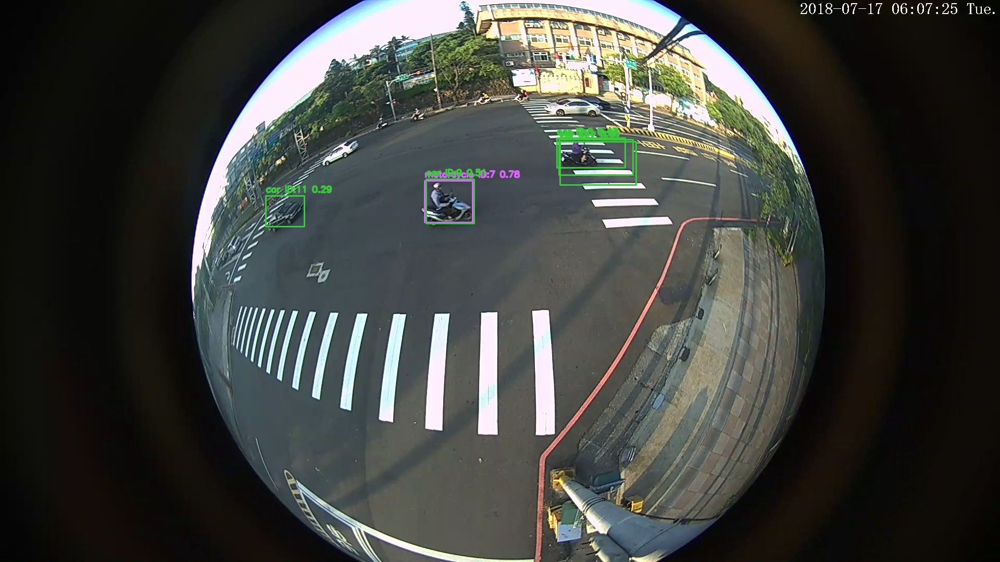

**Image: `frame_000121.jpg`**

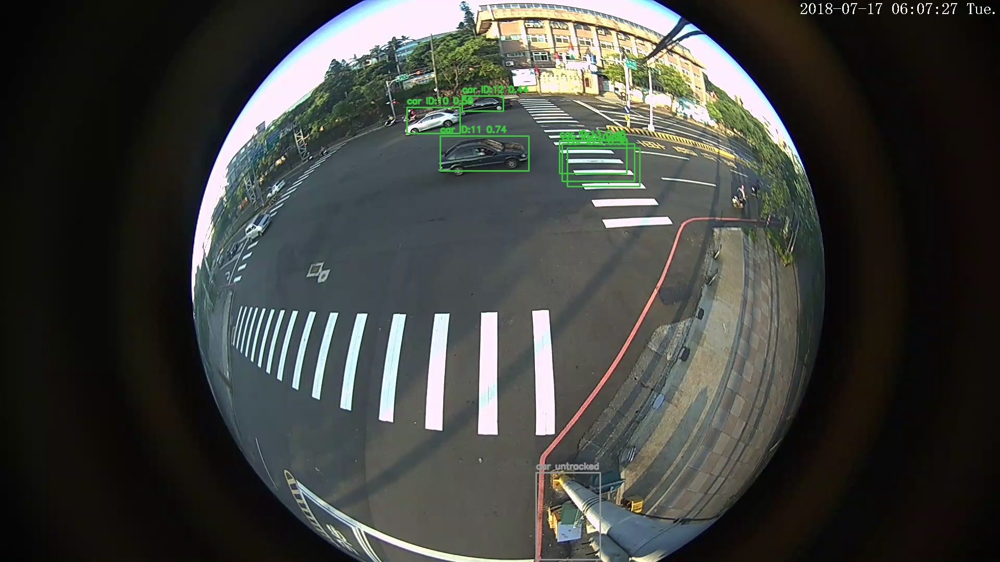

**Image: `track_contact_sheet.jpg`**

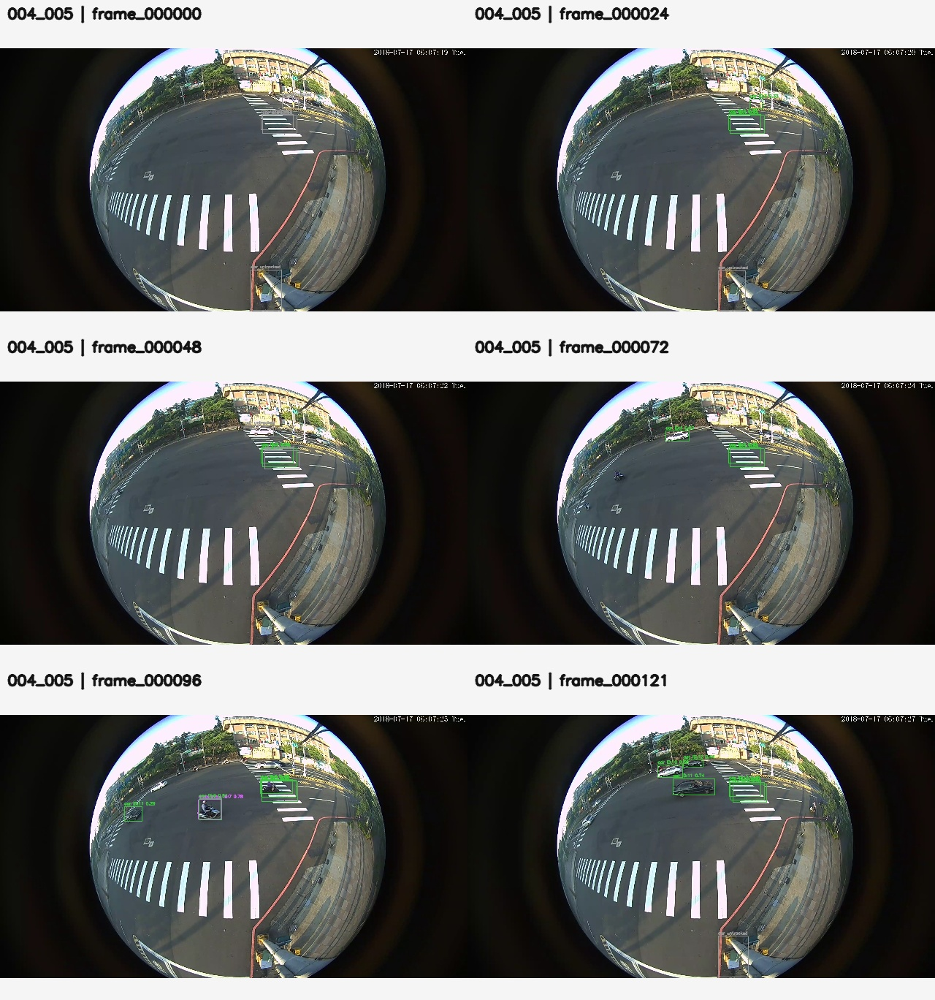

In [ ]:
#55
from pathlib import Path
from IPython.display import display, Markdown, Image, Video
import os

PROJECT = Path(
    "/content/drive/MyDrive/DAA_Project/traffic-investigation-system"
)
TRACKING = PROJECT / "stage3" / "tracking"

for clip in ["001_020", "004_005"]:
    vis_dir = TRACKING / clip / "visualizations"

    display(Markdown(f"# Stage 3 annotations — {clip}"))

    if not vis_dir.is_dir():
        print(f"Visualization directory missing: {vis_dir}")
        continue

    files = sorted(
        p for p in vis_dir.rglob("*")
        if p.is_file()
    )

    print(f"Directory: {vis_dir}")
    print(f"Files found: {len(files)}")

    for p in files:
        print(f"  {p.relative_to(vis_dir)}  ({p.stat().st_size:,} bytes)")

    images = [
        p for p in files
        if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".webp"}
    ]
    videos = [
        p for p in files
        if p.suffix.lower() in {".mp4", ".webm", ".avi", ".mov"}
    ]

    for p in images:
        display(Markdown(f"**Image: `{p.name}`**"))
        display(Image(filename=str(p)))

    for p in videos:
        display(Markdown(f"**Annotated video: `{p.name}`**"))
        display(Video(filename=str(p), embed=True, width=900))
